<div style="background-color: #FFFF00; color: #000000; padding: 12px 18px; font-family: Arial, Helvetica, sans-serif;">
<strong style="color: #000000;">MINE-4101 Ciencia de Datos Aplicada · Universidad de los Andes · 2026-20</strong><br>
<span style="color: #000000;">Proyecto final · Primera entrega · Actividad 6</span>
</div>

# Entendimiento de los datos

Análisis exploratorio y calidad de los datos del levantamiento catastral de un municipio colombiano.

**Integrantes**

- Daniel Felipe Triviño Santana
- Nicolas Bedoya Figueroa
- Joubert Daniel Álvarez
- Gabriel Bejarano

**Datos:** la base catastral de un municipio colombiano, en el modelo LADM-COL y en su versión podada: 45 tablas, de las cuales 20 tienen los datos del levantamiento (410 171 filas) y 23 son dominios. Ver la [descripción de la base](../../datos/base-podada/README.md) y su [diccionario de datos](../../datos/base-podada/diccionario-de-datos.md).

**Qué pide el enunciado** (actividad 6, 35 % de la primera entrega): un reporte de análisis exploratorio y de calidad de los datos, en el que sea evidente el uso de técnicas univariadas y multivariadas, gráficas y no gráficas. El objetivo de la entrega es validar la calidad y la suficiencia de los datos para la solución planteada.

**Estado:** las ocho etapas tienen análisis e interpretación. Las preguntas de hipótesis son provisionales hasta que se defina la pregunta de negocio (actividad 4). Los resultados más importantes pasan a la sección 6 del [reporte](../reporte/reporte.pdf).

Última actualización: octubre de 2026.

## Tabla de contenido

Las etapas siguen el proceso de exploración que presenta el curso (Ghosh et al., 2018): cargar los datos, distinguir los atributos, analizarlos uno por uno, buscar interacciones entre ellos, detectar valores aberrantes y faltantes, detectar valores atípicos y recoger los insights. El paso de ingeniería de características de ese proceso corresponde a la preparación de datos de la entrega final (actividad 8) y no se desarrolla aquí.

Los cuatro tipos de análisis que pide el enunciado (univariado y multivariado, gráfico y no gráfico) son las subsecciones de las etapas 4 y 5.

| | Etapa | Qué se hace | Apoyo en el curso |
| --- | --- | --- | --- |
| 1 | [Librerías y configuración](#librerias) | Cargar las librerías y fijar las opciones de tablas y gráficas | Tutoriales 1 y 2 |
| 2 | [Carga de los datos](#carga) | Leer las tablas y revisar dimensiones, tipos y una muestra | Inicio del proceso de exploración; tutoriales 1 y 2 |
| 3 | [Identificación de los atributos](#atributos) | Clasificar cada atributo como cuantitativo o cualitativo | Paso 1; EDA, diapositivas 10 a 16 |
| 4 | [Análisis univariado](#univariado) | Describir cada atributo por separado: 4.1 no gráfico, 4.2 gráfico | Paso 2; EDA, diapositivas 17 a 28 y 57 a 60; tutorial 1 |
| 5 | [Análisis multivariado](#multivariado) | Buscar relaciones entre atributos: 5.1 no gráfico, 5.2 gráfico | Paso 3; EDA, diapositivas 29 a 47 y 61 a 70; tutorial 1 |
| 6 | [Calidad de los datos](#calidad) | 6.1 valores faltantes y aberrantes, 6.2 valores atípicos, 6.3 resumen de problemas | Pasos 4 y 5; Calidad, diapositivas 4 a 22; tutorial 2 |
| 7 | [Suficiencia de los datos](#suficiencia) | Concluir si los datos alcanzan para la solución planteada | Objetivos de la primera entrega, en el enunciado |
| 8 | [Conclusiones e insights](#conclusiones) | Reunir los hallazgos de las etapas anteriores | Cierre del proceso de exploración; EDA, diapositivas 4 a 6 |

Fuentes del curso:

- **EDA:** diapositivas «Análisis exploratorio de datos (EDA)», clases 3 y 4.
- **Calidad:** diapositivas «Calidad y limpieza de datos», clase 5.
- **Tutoriales 1 y 2:** [data-analysis-tutorial](https://github.com/datascience-uniandes/data-analysis-tutorial) y [data-quality-tutorial](https://github.com/datascience-uniandes/data-quality-tutorial).
- **Proceso de exploración:** A. Ghosh et al., "A comprehensive review of tools for exploratory analysis of tabular industrial datasets", *Visual Informatics* 2(4), 2018. Es el que muestra la diapositiva 9 de EDA.

<a id="librerias"></a>

## 1. Librerías y configuración

Las librerías son las que usan los tutoriales del curso y están en el entorno del proyecto (ver el [README](../../README.md#entorno-de-python)). También están aquí las que solo usa alguna etapa (`scipy`, `statsmodels`, `scikit-learn`). Las funciones que se repiten en varias etapas (resúmenes, gráficas univariadas, pruebas con sus supuestos y la bitácora de calidad) están en [utilidades_eda.py](utilidades_eda.py), junto a este notebook; parten de las del primer parcial del curso.

In [1]:
# Librerías básicas de análisis y visualización
import platform
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import seaborn as sns
from matplotlib import font_manager

# Estadística, modelos y reducción de dimensionalidad (etapas 5 y 6)
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")  # evita un aviso de joblib en Windows
import scipy
import scipy.stats as stats
import sklearn
import statsmodels
import statsmodels.formula.api as smf
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Funciones propias del notebook (utilidades_eda.py, en esta misma carpeta)
import utilidades_eda as ue

In [2]:
# Raíz del repositorio: la carpeta que contiene pyproject.toml
RAIZ = next(c for c in [Path.cwd(), *Path.cwd().parents] if (c / "pyproject.toml").exists())

# Tablas: todas las columnas, hasta 100 filas y sin notación científica
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.options.display.float_format = "{:.2f}".format

# Gráficas: identidad visual del proyecto (ver identidad/README.md)
plt.style.use(RAIZ / "identidad" / "graficas.mplstyle")
AMARILLO, NEGRO, GRIS = "#FFFF00", "#000000", "#666666"
AZUL = "#2a78d6"  # segunda serie de la paleta, después del negro

# Semilla para todo lo que use azar (muestras, reducción de dimensionalidad)
SEMILLA = 4101

In [3]:
# Versiones con las que se ejecutó el notebook
print(f"Python {platform.python_version()}")
for libreria in (np, pd, pa, mpl, sns, scipy, statsmodels, sklearn):
    print(f"{libreria.__name__} {libreria.__version__}")

# Fuente que usan las gráficas: debería ser Arial (ver identidad/README.md)
ruta_fuente = font_manager.findfont(font_manager.FontProperties(family=plt.rcParams["font.family"]))
print("Fuente de las gráficas:", font_manager.get_font(ruta_fuente).family_name)

Python 3.12.13
numpy 2.3.5
pandas 2.3.3
pyarrow 26.0.0
matplotlib 3.10.0
seaborn 0.13.2
scipy 1.16.3
statsmodels 0.15.0
sklearn 1.9.1
Fuente de las gráficas: Arial


<a id="carga"></a>

## 2. Carga de los datos

Como en los tutoriales del curso: leer cada tabla y revisar sus dimensiones, los tipos de sus columnas y una muestra de filas.

**Qué se lee.** El archivo `datos/predios/predios.parquet`: la base podada en un solo archivo, con un predio por fila y sin datos personales. Lo que la base guarda sobre los interesados y sobre quienes atendieron la visita llega reducido a conteos por predio. Cómo se construye el archivo está en [datos/predios/](../../datos/predios/README.md), y qué significa cada campo, en su [diccionario de datos](../../datos/predios/diccionario/diccionario-de-datos.pdf).

**El archivo no está en el repositorio.** Sigue identificando al municipio, así que el equipo lo comparte por un canal privado. Para ejecutar el notebook hay que pedirlo o construirlo a partir de la base podada, y dejarlo en `datos/predios/`. Sin él, la primera celda de esta etapa se detiene con un mensaje que lo explica.

**Tres tablas.** Lo que en el archivo está anidado se separa aquí en tablas que se unen por `id_predio`:

| Tabla | Una fila por | De dónde sale |
| --- | --- | --- |
| `predios` | Predio | Las columnas simples del archivo y los campos de sus estructuras (`terreno`, `ph_matriz`, `titulares`), con el nombre de la estructura como prefijo: `terreno.area_terreno` |
| `construcciones` | Construcción | La lista `construcciones` de cada predio |
| `unidades` | Unidad de construcción | La lista `unidades` de cada predio, con las características de cada unidad |

En propiedad horizontal, la construcción de una unidad suele estar en el predio matriz: `unidades.id_construccion` se une con `construcciones.id_construccion`, no necesariamente dentro del mismo predio.

**Lo que las salidas no pueden mostrar.** El repositorio es público y las salidas de las celdas se suben con el notebook (ver [Antes de compartirla](../../datos/base-podada/README.md#antes-de-compartirla)). Ninguna debe dejar a la vista:

- Lo que identifica al municipio: los códigos `departamento` y `municipio`, el `numero_predial` (sus primeros dígitos son esos códigos), el círculo registral (`codigo_orip`), la matrícula, el código homologado, el `id_operacion` y el `ente_emisor`, que nombra notarías y juzgados del lugar. Tampoco mapas: el archivo no trae coordenadas.
- Los componentes del número predial que, juntos, ubican un predio concreto (cuasi-identificadores): `manzana_vereda`, `numero_terreno`, `edificio`, `piso` y `unidad`.
- Los textos libres (`nombre`, `observaciones`, `numero_fuente`, `observacion_fuente` y las observaciones de las unidades), que pueden traer nombres de personas.
- La facturación del impuesto predial de cada predio (`ipu_facturado_2026`, `pago_2026` y `pago_2025`): cuánto se le cobró a un predio y si pagó es información sobre su dueño. Se muestra solo en agregados.

Esas columnas están en `COLUMNAS_RESERVADAS`. Se pueden usar en los cálculos, pero no se muestran sus valores.

In [4]:
# El archivo se construye con datos/predios/ y no está en el repositorio
ARCHIVO_PREDIOS = RAIZ / "datos" / "predios" / "predios.parquet"
if not ARCHIVO_PREDIOS.exists():
    raise FileNotFoundError(
        f"Falta {ARCHIVO_PREDIOS.relative_to(RAIZ)}: pídalo al equipo o constrúyalo "
        "como indica datos/predios/README.md"
    )

# flatten() convierte cada estructura en columnas con su prefijo (terreno.area_terreno);
# las listas (construcciones, unidades) quedan como columnas de listas
predios = pq.read_table(ARCHIVO_PREDIOS).flatten().to_pandas()

# Las fechas llegan como objetos date de Python
for columna in ["fecha_visita_predial", "fecha_inicio_tenencia", "fecha_documento_fuente"]:
    predios[columna] = pd.to_datetime(predios[columna])

# Columnas que identifican al municipio, pueden traer nombres o dicen cuánto pagó el dueño
# de un predio: no se muestran sus valores
COLUMNAS_RESERVADAS = [
    "departamento", "municipio", "numero_predial", "codigo_orip", "matricula_inmobiliaria",
    "codigo_homologado", "id_operacion", "ente_emisor",
    "nombre", "observaciones", "numero_fuente", "observacion_fuente",
    "manzana_vereda", "numero_terreno", "edificio", "piso", "unidad",
    "ipu_facturado_2026", "pago_2026", "pago_2025",
]

In [5]:
def desanidar(columna):
    """Una fila por elemento de una columna de listas, con el id del predio al que pertenece."""
    filas = predios[["id_predio", columna]].explode(columna).dropna(subset=[columna])
    return pd.concat(
        [filas[["id_predio"]].reset_index(drop=True), pd.json_normalize(filas[columna].tolist())],
        axis=1,
    )


construcciones = desanidar("construcciones")
unidades = desanidar("unidades")
predios = predios.drop(columns=["construcciones", "unidades"])

TABLAS = {"predios": predios, "construcciones": construcciones, "unidades": unidades}

In [6]:
# Dimensiones de cada tabla
pd.DataFrame(
    {"filas": [len(t) for t in TABLAS.values()], "columnas": [t.shape[1] for t in TABLAS.values()]},
    index=list(TABLAS),
)

,filas,columnas
predios,22220,76
construcciones,13483,15
unidades,42988,21


In [7]:
# Tipos de las columnas y cuántos valores no nulos tiene cada una
for nombre, tabla in TABLAS.items():
    print(f"=== {nombre}")
    tabla.info()
    print()

=== predios
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22220 entries, 0 to 22219
Data columns (total 76 columns):
 #   Column                                   Non-Null Count  Dtype         
---  ------                                   --------------  -----         
 0   id_predio                                22220 non-null  int64         
 1   departamento                             22220 non-null  object        
 2   municipio                                22220 non-null  object        
 3   numero_predial                           22220 non-null  object        
 4   zona                                     22220 non-null  object        
 5   sector                                   22220 non-null  object        
 6   comuna                                   22220 non-null  object        
 7   barrio                                   22220 non-null  object        
 8   manzana_vereda                           22220 non-null  object        
 9   numero_terreno             

In [8]:
# Muestra de predios, sin las columnas reservadas
predios.drop(columns=COLUMNAS_RESERVADAS).sample(5, random_state=SEMILLA)

,id_predio,zona,sector,comuna,barrio,condicion_propiedad,avaluo_catastral,tipo,condicion_predio,destinacion_economica,area_registral_m2,fecha_visita_predial,resultado_visita,tipo_novedad_numero_predial,n_contactos_visita,autoriza_notificaciones,tipo_direccion,es_direccion_principal,ph_matriz.area_total_terreno,ph_matriz.area_total_terreno_privada,ph_matriz.area_total_terreno_comun,ph_matriz.area_total_construida,ph_matriz.area_total_construida_privada,ph_matriz.area_total_construida_comun,ph_matriz.numero_torres,ph_matriz.total_unidades_privadas,id_predio_matriz,coeficiente_copropiedad,n_unidades_prediales,ids_predios_informales,ids_predios_formales,terreno.id_terreno,terreno.area_terreno,terreno.area_geometrica,terreno.perimetro,terreno.compacidad,terreno.n_vertices,terreno.n_poligonos,terreno.geometria_valida,tipo_derecho,fraccion_derecho,fecha_inicio_tenencia,tipo_fuente,estado_disponibilidad,tipo_principal,fecha_documento_fuente,titulares.es_agrupacion,titulares.tipo_agrupacion,titulares.n_titulares,titulares.n_persona_natural,titulares.n_persona_juridica,titulares.n_femenino,titulares.n_masculino,titulares.n_sexo_sin_determinar,titulares.participacion_max,titulares.max_predios_mismo_titular
3746,161482,00,00,00,00,0,24149000.00,Predio.Privado,NPH,Agricola,75.99,2025-09-09,Exitoso,None,1,False,No_Estructurada,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,[],[],83472.00,79.20,79.18,47.05,0.45,6.00,1.00,True,Dominio,1.00,2015-09-29,Documento_Publico.Sentencia_Judicial,Disponible,Documento,2015-06-24,True,Grupo_Civil,3,3,0,0,3,0,0.33,2
20415,467099,00,00,00,00,9,233893000.00,Predio.Privado,PH.Unidad_Predial,Habitacional,98.38,2025-12-23,Incompleto,Desenglobe,0,None,No_Estructurada,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,162190.00,0.01,0,[],[],NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,Dominio,1.00,2022-09-19,Documento_Publico.Escritura_Publica,Disponible,Documento,2022-08-25,True,Grupo_Civil,2,2,0,1,1,0,0.50,1
10522,437420,00,00,00,00,7,0.00,Predio.Privado,Parque_Cementerio.Unidad_Predial,Servicios_Funerarios,3.00,2026-01-07,Incompleto,Predio_Nuevo,0,None,No_Estructurada,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,161773.00,0.00,0,[],[],NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,Dominio,1.00,2016-08-17,Documento_Publico.Escritura_Publica,Disponible,Documento,2016-07-29,True,Grupo_Civil,4,4,0,3,1,0,0.25,1
11313,439793,00,00,00,00,9,614183000.00,Predio.Privado,PH.Unidad_Predial,Comercial,1242.42,2025-07-18,Incompleto,Cambio_Numero_Predial,0,None,No_Estructurada,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,164518.00,0.01,0,[],[],NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,Dominio,1.00,2012-10-17,Documento_Publico.Escritura_Publica,Disponible,Documento,2012-08-01,False,None,1,0,1,0,0,1,1.00,78
2579,159142,00,00,00,00,0,215751000.00,Predio.Privado,NPH,Agricola,0.00,2025-09-03,Sin_Visita,None,1,False,No_Estructurada,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,[],[],82180.00,679.00,679.00,287.97,0.10,37.00,1.00,True,Dominio,1.00,2000-12-26,Documento_Publico.Escritura_Publica,Disponible,Documento,2000-12-14,False,None,1,1,0,0,1,0,1.00,1


In [9]:
# Muestra de construcciones
construcciones.sample(5, random_state=SEMILLA)

,id_predio,id_construccion,identificador,total_pisos,total_sotanos,total_mezanines,total_semisotanos,area_total_construccion,altura_total_construccion,area_geometrica,perimetro,compacidad,n_vertices,n_poligonos,geometria_valida
12693,470348,52513,A,1,0,0,0,164.10,3.00,164.11,87.30,0.27,39,1,True
8611,165576,55281,A,2,0,0,0,6359.10,6.00,6359.11,1893.09,0.02,681,26,True
106,155783,50533,D,2,0,0,0,188.70,6.00,188.71,56.52,0.74,8,1,True
7338,164006,52980,C,1,0,0,0,137.50,3.00,137.46,47.89,0.75,5,1,True
49,155711,57474,A,1,0,0,0,45.60,3.00,45.64,31.58,0.58,5,1,True


In [10]:
# Muestra de unidades de construcción, sin sus observaciones
unidades.drop(columns=["observaciones"]).sample(5, random_state=SEMILLA)

,id_predio,id_unidad,id_construccion,identificador,tipo_unidad_construccion,uso,tipo_planta,planta_ubicacion,total_plantas,anio_construccion,area_construida,area_construida_caracteristicas,area_privada_construida,altura,area_geometrica,perimetro,compacidad,n_vertices,n_poligonos,geometria_valida
34832,458552,123726,60837,A,Anexo,Anexo.Marquesinas_Patios_Cubiertos,Piso,3,1,2023,7.20,0.00,7.20,3,7.22,12.55,0.58,7,1,True
36911,463070,110018,54250,C,Residencial,Residencial.Vivienda_Hasta_3_Pisos_En_PH,Piso,1,1,2024,34.80,0.00,34.80,3,34.77,24.68,0.72,7,1,True
28866,448019,107706,63109,F,Residencial,Residencial.Vivienda_Hasta_3_Pisos_En_PH,Piso,2,1,2019,62.20,0.00,62.20,3,62.16,34.80,0.65,13,1,True
6862,160497,116167,55254,D,Industrial,Industrial.Industrias,Piso,1,1,2000,71.40,71.40,NaN,3,71.42,35.27,0.72,5,1,True
19730,172700,127207,56482,A,Residencial,Residencial.Vivienda_Hasta_3_Pisos_En_PH,Piso,3,3,2022,23.60,0.00,23.60,3,23.58,25.14,0.47,9,1,True


<a id="atributos"></a>

## 3. Identificación de los atributos

Primer paso del proceso de exploración: distinguir de qué tipo es cada atributo, porque de eso depende qué medidas y qué gráficas le sirven.

| Tipo | Subtipos | Cómo reconocerlo |
| --- | --- | --- |
| Cuantitativo | Discreto o continuo | Representa una magnitud: restar dos valores tiene sentido. Es continuo si además tiene sentido el valor medio entre dos valores |
| Cualitativo (categórico) | Nominal u ordinal | Toma niveles. Es ordinal si los niveles se pueden ordenar |

En esta base, el tipo de dato de la columna no basta para clasificarla:

- Los atributos de dominio (`condicion_predio`, `uso`, `tipo`) guardan el `t_id` de una fila de la tabla del dominio. Son cualitativos, aunque en la base sean números.
- Las llaves y los identificadores (`t_id`, `numero_predial`, `matricula_inmobiliaria`) tampoco son cuantitativos: restar dos de ellos no significa nada.

### 3.1 Tipo de cada atributo

Los atributos que se usan en el análisis, con su tipo según el curso. La columna `tipo en pandas` muestra por qué el tipo de dato no basta: hay códigos guardados como texto que son cualitativos, y años guardados como enteros que se tratan como cuantitativos discretos.

In [11]:
ATRIBUTOS = [
    # (tabla, atributo, tipo, subtipo, nota)
    ("predios", "avaluo_catastral", "Cuantitativo", "Continuo (razón)", "Pesos; suma del avalúo del terreno y de las construcciones"),
    ("predios", "area_registral_m2", "Cuantitativo", "Continuo (razón)", "m², según los títulos"),
    ("predios", "terreno.area_terreno", "Cuantitativo", "Continuo (razón)", "m², medida en el levantamiento"),
    ("predios", "coeficiente_copropiedad", "Cuantitativo", "Continuo (razón)", "Entre 0 y 1"),
    ("predios", "fraccion_derecho", "Cuantitativo", "Continuo (razón)", "Entre 0 y 1"),
    ("predios", "n_unidades_prediales", "Cuantitativo", "Discreto", "Solo en matrices"),
    ("predios", "titulares.n_titulares", "Cuantitativo", "Discreto", "Conteo"),
    ("predios", "fecha_visita_predial", "Cuantitativo", "Continuo (intervalo)", "Fecha"),
    ("predios", "zona", "Cualitativo", "Nominal", "Código del número predial: 00 rural, 01 urbana"),
    ("predios", "condicion_propiedad", "Cualitativo", "Nominal", "Código de la posición 22 del número predial"),
    ("predios", "condicion_predio", "Cualitativo", "Nominal (jerárquico)", "Régimen: NPH, PH, condominio, etc."),
    ("predios", "tipo", "Cualitativo", "Nominal (jerárquico)", "Privado o público"),
    ("predios", "destinacion_economica", "Cualitativo", "Nominal", "Actividad predominante"),
    ("predios", "resultado_visita", "Cualitativo", "Nominal", "Cómo terminó la visita de campo"),
    ("predios", "tipo_novedad_numero_predial", "Cualitativo", "Nominal", "Cambio frente al catastro anterior"),
    ("predios", "tipo_derecho", "Cualitativo", "Nominal", "Dominio, posesión u ocupación"),
    ("predios", "tipo_fuente", "Cualitativo", "Nominal (jerárquico)", "Documento que sustenta el derecho"),
    ("predios", "id_predio", "Identificador", "—", "Llave; restar dos valores no tiene sentido"),
    ("unidades", "area_construida", "Cuantitativo", "Continuo (razón)", "m²"),
    ("unidades", "anio_construccion", "Cuantitativo", "Discreto (intervalo)", "Año"),
    ("unidades", "total_plantas", "Cuantitativo", "Discreto", "Conteo"),
    ("unidades", "planta_ubicacion", "Cualitativo", "Ordinal (codificado)", "Número de planta; 81 a 99 son sótanos en la convención del número predial (6.1)"),
    ("unidades", "tipo_planta", "Cualitativo", "Nominal", "Piso, mezanine, sótano, semisótano"),
    ("unidades", "tipo_unidad_construccion", "Cualitativo", "Nominal", "Convencional (residencial, comercial...) o anexo"),
    ("unidades", "uso", "Cualitativo", "Nominal (jerárquico)", "Grupo.Uso, 82 valores"),
    ("construcciones", "total_pisos", "Cuantitativo", "Discreto", "Conteo"),
    ("construcciones", "altura_total_construccion", "Cuantitativo", "Continuo (razón)", "Metros"),
]
tipos = pd.DataFrame(ATRIBUTOS, columns=["tabla", "atributo", "tipo", "subtipo", "nota"])
tipos["tipo en pandas"] = [str(TABLAS[t][a].dtype) for t, a in zip(tipos["tabla"], tipos["atributo"])]
tipos["únicos"] = [TABLAS[t][a].nunique() for t, a in zip(tipos["tabla"], tipos["atributo"])]
tipos.set_index(["tabla", "atributo"])

tipo  \
tabla          atributo                                     
predios        avaluo_catastral              Cuantitativo   
               area_registral_m2             Cuantitativo   
               terreno.area_terreno          Cuantitativo   
               coeficiente_copropiedad       Cuantitativo   
               fraccion_derecho              Cuantitativo   
               n_unidades_prediales          Cuantitativo   
               titulares.n_titulares         Cuantitativo   
               fecha_visita_predial          Cuantitativo   
               zona                           Cualitativo   
               condicion_propiedad            Cualitativo   
               condicion_predio               Cualitativo   
               tipo                           Cualitativo   
               destinacion_economica          Cualitativo   
               resultado_visita               Cualitativo   
               tipo_novedad_numero_predial    Cualitativo   
               tipo_derecho                   Cualitativo   
               tipo_fuente                    Cualitativo   
               id_predio                    Identificador   
unidades       area_construida               Cuantitativo   
               anio_construccion             Cuantitativo   
               total_plantas                 Cuantitativo   
               planta_ubicacion               Cualitativo   
               tipo_planta                    Cualitativo   
               tipo_unidad_construccion       Cualitativo   
               uso                            Cualitativo   
construcciones total_pisos                   Cuantitativo   
               altura_total_construccion     Cuantitativo   

                                                         subtipo  \
tabla          atributo                                            
predios        avaluo_catastral                 Continuo (razón)   
               area_registral_m2                Continuo (razón)   
               terreno.area_terreno             Continuo (razón)   
               coeficiente_copropiedad          Continuo (razón)   
               fraccion_derecho                 Continuo (razón)   
               n_unidades_prediales                     Discreto   
               titulares.n_titulares                    Discreto   
               fecha_visita_predial         Continuo (intervalo)   
               zona                                      Nominal   
               condicion_propiedad                       Nominal   
               condicion_predio             Nominal (jerárquico)   
               tipo                         Nominal (jerárquico)   
               destinacion_economica                     Nominal   
               resultado_visita                          Nominal   
               tipo_novedad_numero_predial               Nominal   
               tipo_derecho                              Nominal   
               tipo_fuente                  Nominal (jerárquico)   
               id_predio                                       —   
unidades       area_construida                  Continuo (razón)   
               anio_construccion            Discreto (intervalo)   
               total_plantas                            Discreto   
               planta_ubicacion             Ordinal (codificado)   
               tipo_planta                               Nominal   
               tipo_unidad_construccion                  Nominal   
               uso                          Nominal (jerárquico)   
construcciones total_pisos                              Discreto   
               altura_total_construccion        Continuo (razón)   

                                                                                         nota  \
tabla          atributo                                                                         
predios        avaluo_catastral             Pesos; suma del avalúo del terreno y de las co...   
               area

### 3.2 Códigos del número predial

`zona` y `condicion_propiedad` son partes del número predial nacional, cuya estructura define la Resolución IGAC 1149 de 2021 (ver el [diccionario de datos del parquet](../../datos/predios/diccionario/diccionario-de-datos.pdf), sección 2). Se traducen a texto para las tablas y gráficas:

- **Zona** (posiciones 6 y 7): 00 rural, 01 cabecera municipal (urbana); 02 a 99 serían corregimientos y aquí no hay.
- **Condición de propiedad** (posición 22): 0 no reglamentado en PH, 2 informal, 3 bien de uso público distinto de las vías, 4 vía, 5 mejora en terreno ajeno sin PH, 7 parque cementerio, 8 condominio, 9 propiedad horizontal.

Hay que tener en cuenta que la zona 00 incluye mucha propiedad horizontal en suelo rural: "rural" no equivale a campo.

In [12]:
ZONAS = {"00": "Rural", "01": "Urbano"}
CONDICION_PROPIEDAD = {
    "0": "No reglamentado en PH", "2": "Informal (ocupación, posesión)",
    "3": "Bien de uso público distinto de vías", "4": "Vía",
    "5": "Mejora en terreno ajeno sin PH", "7": "Parque cementerio",
    "8": "Condominio", "9": "Propiedad horizontal",
}
predios["zona_txt"] = predios["zona"].map(ZONAS)
predios["condicion_propiedad_txt"] = predios["condicion_propiedad"].map(CONDICION_PROPIEDAD)
assert predios["zona_txt"].notna().all() and predios["condicion_propiedad_txt"].notna().all()
pd.crosstab(predios["condicion_propiedad_txt"], predios["zona_txt"], margins=True, margins_name="Total")

zona_txt,Rural,Urbano,Total
condicion_propiedad_txt,,,
Bien de uso público distinto de vías,75,49,124
Condominio,1805,637,2442
"Informal (ocupación, posesión)",124,58,182
Mejora en terreno ajeno sin PH,366,41,407
No reglamentado en PH,3679,2228,5907
Parque cementerio,1285,0,1285
Propiedad horizontal,8114,3700,11814
Vía,39,20,59
Total,15487,6733,22220


### 3.3 Atributos derivados por predio

El análisis se hace por predio, así que se resumen en `predios` las unidades y las construcciones de cada uno:

- **Unidades de construcción:** número de unidades, área construida total, año de construcción (mediana y mínimo de sus unidades), plantas, y el tipo y uso de la unidad con más área.
- **Anexos:** según el diccionario, son construcciones no convencionales (ramadas, cimientos, piscinas, etc.). Se calcula también el área construida sin anexos (`area_convencional`) y la proporción del área que son anexos (`prop_anexo`).
- **Construcciones:** número de construcciones y pisos máximos. En propiedad horizontal las construcciones están en la fila del predio matriz, así que las unidades prediales quedan con 0.
- **Indicadores:** si el predio tiene matrícula inmobiliaria (`tiene_matricula`; la matrícula misma no se muestra) y su novedad del número predial, con `Sin_Novedad` cuando no tiene.

**Valores centinela.** Un valor que se repite muchísimo más que sus vecinos suele ser un valor por defecto o de carga, no un dato real. Dos saltan a la vista y se marcan aquí, antes de usarlos en las etapas 4 y 5; el resto de la calidad está en la etapa 6. Cada problema y su estrategia quedan en una **bitácora** que se llena desde el código a lo largo del notebook y se resume en la etapa 6.3.

In [13]:
bitacora = ue.BitacoraCalidad()

# total_plantas = 99 en 4 unidades (todas semisótanos): no es un número de plantas posible
plantas_99 = unidades["total_plantas"].eq(99)
unidades["total_plantas"] = unidades["total_plantas"].mask(plantas_99)
bitacora.registrar("total_plantas = 99", "unidades.total_plantas", "Precisión", "Atributo", plantas_99.sum(),
                   "Se marca como faltante")

# total_pisos = 99 en construcciones (con altura de 297 m = 99 x 3): mismo valor de relleno
pisos_99 = construcciones["total_pisos"].eq(99)
construcciones.loc[pisos_99, ["total_pisos", "altura_total_construccion"]] = np.nan
bitacora.registrar("total_pisos = 99 (con altura de 297 m)", "construcciones.total_pisos y altura_total_construccion",
                   "Precisión", "Atributo", pisos_99.sum(), "Se marca como faltante")

# Resumen de las unidades por predio
u = unidades.assign(
    area_anexo=unidades["area_construida"].where(unidades["tipo_unidad_construccion"] == "Anexo", 0),
    dif_geometrica=(unidades["area_construida"] - unidades["area_geometrica"]).abs(),
)
por_predio = u.groupby("id_predio").agg(
    n_unidades=("id_unidad", "size"),
    area_construida_total=("area_construida", "sum"),
    area_anexo=("area_anexo", "sum"),
    anio_construccion_mediana=("anio_construccion", "median"),
    anio_construccion_min=("anio_construccion", "min"),
    plantas_max=("total_plantas", "max"),
    dif_geometrica=("dif_geometrica", "sum"),
)
principal = unidades.loc[unidades.groupby("id_predio")["area_construida"].idxmax(),
                         ["id_predio", "tipo_unidad_construccion", "uso"]].set_index("id_predio")
por_predio = por_predio.join(principal.rename(columns={"tipo_unidad_construccion": "tipo_unidad_principal",
                                                       "uso": "uso_principal"}))
por_predio["area_convencional"] = por_predio["area_construida_total"] - por_predio["area_anexo"]
por_predio["prop_anexo"] = por_predio["area_anexo"] / por_predio["area_construida_total"]
por_predio["dif_area_geometrica_pct"] = por_predio["dif_geometrica"] / por_predio["area_construida_total"] * 100
por_predio = por_predio.drop(columns=["area_anexo", "dif_geometrica"])

por_construccion = construcciones.groupby("id_predio").agg(n_construcciones=("id_construccion", "size"),
                                                           pisos_max=("total_pisos", "max"))

predios = predios.drop(columns=[c for c in [*por_predio.columns, *por_construccion.columns] if c in predios.columns])
predios = predios.join(por_predio, on="id_predio").join(por_construccion, on="id_predio")
for col in ["n_unidades", "n_construcciones"]:
    predios[col] = predios[col].fillna(0).astype(int)
for col in ["area_construida_total", "area_convencional"]:
    predios[col] = predios[col].fillna(0)

predios["tiene_matricula"] = predios["matricula_inmobiliaria"].notna()
predios["novedad_numero_predial"] = predios["tipo_novedad_numero_predial"].fillna("Sin_Novedad")
print(f"predios: {predios.shape[0]:,} filas x {predios.shape[1]} columnas")
predios[["n_unidades", "area_construida_total", "area_convencional", "prop_anexo", "anio_construccion_mediana",
         "plantas_max", "n_construcciones", "tiene_matricula", "novedad_numero_predial"]].describe(include="all").T

predios: 22,220 filas x 92 columnas


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
n_unidades,22220.00,NaN,NaN,NaN,1.93,9.00,0.00,1.00,1.00,3.00,1290.00
area_construida_total,22220.00,NaN,NaN,NaN,266.14,1937.88,0.00,1.90,83.45,207.93,184904.30
area_convencional,22220.00,NaN,NaN,NaN,218.06,1688.54,0.00,0.00,45.60,187.00,179219.50
prop_anexo,16832.00,NaN,NaN,NaN,0.16,0.33,0.00,0.00,0.00,0.09,1.00
anio_construccion_mediana,16832.00,NaN,NaN,NaN,2011.73,11.08,1944.00,2000.00,2015.00,2022.00,2025.00
plantas_max,16828.00,NaN,NaN,NaN,1.33,0.65,1.00,1.00,1.00,1.00,5.00
n_construcciones,22220.00,NaN,NaN,NaN,0.61,3.25,0.00,0.00,0.00,1.00,303.00
tiene_matricula,22220,2,True,21478,NaN,NaN,NaN,NaN,NaN,NaN,NaN
novedad_numero_predial,22220,6,Cambio_Numero_Predial,8390,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
# Centinela en la fecha de visita: la fecha más frecuente y el resultado de esas visitas
frec_fechas = predios["fecha_visita_predial"].value_counts()
FECHA_CENTINELA = frec_fechas.index[0]
es_fecha_centinela = predios["fecha_visita_predial"].eq(FECHA_CENTINELA)
print(f"Fecha de visita más frecuente: {FECHA_CENTINELA.date()} en {frec_fechas.iloc[0]:,} predios "
      f"({frec_fechas.iloc[0] / len(predios):.1%}); la segunda, en {frec_fechas.iloc[1]:,}")
print("Resultado de la visita en esa fecha:", predios.loc[es_fecha_centinela, "resultado_visita"].value_counts().to_dict())
print("Régimen de los predios con esa fecha:", predios.loc[es_fecha_centinela, "condicion_predio"].value_counts().head(4).to_dict())

# Centinela en el año de construcción: el año 2000 frente a los años vecinos
vecinos = predios["anio_construccion_mediana"].round().value_counts().reindex(range(1996, 2005), fill_value=0)
print("\nPredios por año de construcción (mediana de sus unidades), 1996-2004:", vecinos.to_dict())
es_anio_2000 = predios["anio_construccion_mediana"].eq(2000)
print("Resultado de la visita en los predios con año 2000 (%):",
      predios.loc[es_anio_2000, "resultado_visita"].value_counts(normalize=True).mul(100).round(1).to_dict())

predios["fecha_visita_valida"] = predios["fecha_visita_predial"].mask(es_fecha_centinela)
predios["anio_sospechoso"] = es_anio_2000.astype(int)
bitacora.registrar(f"Fecha de visita {FECHA_CENTINELA.date()} repetida en bloque, todas con visita incompleta",
                   "predios.fecha_visita_predial", "Precisión", "Columna", es_fecha_centinela.sum(),
                   "Se marca como faltante (fecha_visita_valida); se concentra en unidades de PH, cuya visita parece "
                   "registrarse en el predio matriz (ver la visita efectiva, abajo)")
bitacora.registrar("Año de construcción 2000 muy por encima de los años vecinos",
                   "unidades.anio_construccion", "Precisión", "Columna", es_anio_2000.sum(),
                   "Se marca con anio_sospechoso; el PCA lo excluye y la regresión se estima con y sin él")

Fecha de visita más frecuente: 2025-07-18 en 9,010 predios (40.5%); la segunda, en 1,899
Resultado de la visita en esa fecha: {'Incompleto': 9010}
Régimen de los predios con esa fecha: {'PH.Unidad_Predial': 8050, 'NPH': 498, 'Informal': 403, 'Condominio.Unidad_Predial': 56}

Predios por año de construcción (mediana de sus unidades), 1996-2004: {1996: 8, 1997: 7, 1998: 25, 1999: 13, 2000: 3329, 2001: 3, 2002: 46, 2003: 7, 2004: 9}
Resultado de la visita en los predios con año 2000 (%): {'Incompleto': 46.3, 'No_Permitieron_Acceso': 33.2, 'No_Hay_Nadie': 13.4, 'Exitoso': 6.1, 'Sin_Visita': 0.6, 'Menor_Edad': 0.3, 'Zona_Dificil_Acceso': 0.1}


**Visita en propiedad horizontal y condominio.** Casi ninguna unidad predial de PH tiene visita exitosa propia, pero la mayoría pertenece a un predio matriz cuya visita sí fue exitosa. Los datos indican que la visita y la información de campo de la PH se registran en la matriz (el edificio o conjunto) y no en cada unidad (tabla de abajo): las unidades de PH solo tienen dos resultados posibles, casi siempre `Incompleto`, mientras que las matrices tienen toda la gama de resultados de una visita real; casi ninguna unidad tiene a alguien que haya atendido la visita, y casi todas las matrices sí; la fecha centinela (2025-07-18) está en las unidades, nunca en las matrices; y dentro de un mismo edificio todas las unidades tienen el mismo resultado. Conviene confirmarlo con el gestor catastral. Mientras tanto, el notebook usa dos medidas:

- **Visita propia** (`visita_exitosa_propia`): el resultado registrado en el predio.
- **Visita efectiva** (`visita_exitosa_efectiva`): la propia o, si el predio es una unidad predial, la de su matriz. Es la que se usa para la suficiencia (etapa 7) y para el análisis de faltantes (6.1).

In [15]:
por_id = predios.set_index("id_predio")
visita_propia = predios["resultado_visita"].eq("Exitoso") & predios["fecha_visita_valida"].notna()
visita_matriz = (predios["id_predio_matriz"].map(por_id["resultado_visita"]).eq("Exitoso")
                 & predios["id_predio_matriz"].map(por_id["fecha_visita_valida"]).notna())
predios["visita_exitosa_propia"] = visita_propia
predios["visita_exitosa_efectiva"] = visita_propia | visita_matriz

unidades_pred = predios["id_predio_matriz"].notna()
(predios[unidades_pred | predios["condicion_predio"].eq("NPH")]
 .groupby("condicion_predio")[["visita_exitosa_propia", "visita_exitosa_efectiva"]].mean().mul(100).round(1)
 .rename(columns=lambda c: "% " + c.replace("_", " ")))

,% visita exitosa propia,% visita exitosa efectiva
condicion_predio,,
Condominio.Unidad_Predial,74.40,79.60
NPH,18.40,18.40
PH.Unidad_Predial,0.40,60.80
Parque_Cementerio.Unidad_Predial,0.00,100.00


In [16]:
# Evidencia en los datos de que la visita de la PH se registra en la matriz
es_unidad_ph = predios["condicion_predio"].eq("PH.Unidad_Predial")
es_matriz_ph = predios["condicion_predio"].eq("PH.Matriz")
evidencia = pd.DataFrame({
    "unidades de PH": {
        "resultados distintos": predios.loc[es_unidad_ph, "resultado_visita"].nunique(),
        "% con resultado Incompleto": predios.loc[es_unidad_ph, "resultado_visita"].eq("Incompleto").mean() * 100,
        "% con alguien que atendió la visita": predios.loc[es_unidad_ph, "n_contactos_visita"].gt(0).mean() * 100,
        "% con la fecha centinela": predios.loc[es_unidad_ph, "fecha_visita_valida"].isna().mean() * 100,
    },
    "matrices de PH": {
        "resultados distintos": predios.loc[es_matriz_ph, "resultado_visita"].nunique(),
        "% con resultado Incompleto": predios.loc[es_matriz_ph, "resultado_visita"].eq("Incompleto").mean() * 100,
        "% con alguien que atendió la visita": predios.loc[es_matriz_ph, "n_contactos_visita"].gt(0).mean() * 100,
        "% con la fecha centinela": predios.loc[es_matriz_ph, "fecha_visita_valida"].isna().mean() * 100,
    },
})
display(evidencia.round(1))

# Dentro de cada edificio (matrices con al menos 5 unidades): ¿todas las unidades tienen el mismo resultado?
por_edificio = predios[es_unidad_ph].groupby("id_predio_matriz").agg(
    n=("id_predio", "size"), resultados=("resultado_visita", "nunique"), fechas=("fecha_visita_predial", "nunique"))
por_edificio = por_edificio[por_edificio["n"] >= 5]
print(f"Edificios de PH con 5 o más unidades: {len(por_edificio):,}; con un solo resultado en todas sus unidades: "
      f"{por_edificio['resultados'].eq(1).mean():.1%}; con una sola fecha: {por_edificio['fechas'].eq(1).mean():.1%}")

,unidades de PH,matrices de PH
resultados distintos,2.00,6.00
% con resultado Incompleto,99.60,8.10
% con alguien que atendió la visita,0.40,99.90
% con la fecha centinela,72.80,0.00


Edificios de PH con 5 o más unidades: 235; con un solo resultado en todas sus unidades: 99.6%; con una sola fecha: 91.9%


### 3.4 Unidad de análisis

El levantamiento mezcla predios de naturaleza distinta: matrices de PH o condominio y sus unidades prediales, predios no sometidos a PH (NPH), informales, vías, bienes de uso público y unidades de parque cementerio. El avalúo es la suma de los avalúos de terreno y construcciones, así que una matriz y sus unidades no se pueden sumar ni comparar sin más. Dos tablas lo muestran.

In [17]:
pd.crosstab(predios["condicion_predio"],
            predios["avaluo_catastral"].eq(0).map({True: "avalúo = 0", False: "avalúo > 0"}),
            margins=True, margins_name="Total")

avaluo_catastral,avalúo = 0,avalúo > 0,Total
condicion_predio,,,
Bien_Uso_Publico,0,124,124
Condominio.Matriz,4,87,91
Condominio.Unidad_Predial,59,2292,2351
Informal,433,158,591
NPH,495,5408,5903
PH.Matriz,0,763,763
PH.Unidad_Predial,58,10994,11052
Parque_Cementerio.Matriz,0,1,1
Parque_Cementerio.Unidad_Predial,1284,0,1284


In [18]:
# Coherencia matriz-unidades: suma del coeficiente de copropiedad y razón entre la suma
# de los avalúos de las unidades y el avalúo de su matriz
por_matriz = (predios.dropna(subset=["id_predio_matriz"])
              .groupby("id_predio_matriz")
              .agg(n_unidades_pred=("id_predio", "size"),
                   suma_coeficientes=("coeficiente_copropiedad", "sum"),
                   suma_avaluo_unidades=("avaluo_catastral", "sum")))
por_matriz = por_matriz.join(predios.set_index("id_predio")[["condicion_predio", "avaluo_catastral", "n_unidades_prediales"]])
por_matriz["razon_avaluo_unidades_matriz"] = por_matriz["suma_avaluo_unidades"] / por_matriz["avaluo_catastral"].replace(0, np.nan)
print("¿El conteo de unidades coincide con n_unidades_prediales de la matriz?",
      f"{(por_matriz['n_unidades_pred'] == por_matriz['n_unidades_prediales']).mean():.1%}")
por_matriz[["suma_coeficientes", "razon_avaluo_unidades_matriz"]].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95])

¿El conteo de unidades coincide con n_unidades_prediales de la matriz? 100.0%


,suma_coeficientes,razon_avaluo_unidades_matriz
count,854.00,851.00
mean,1.00,5.58
std,0.03,85.70
min,0.00,0.00
5%,1.00,0.71
25%,1.00,1.22
50%,1.00,1.63
75%,1.00,1.99
95%,1.00,4.02
max,1.00,2472.89


**Decisiones provisionales**, a confirmar con el stakeholder:

- **Predios individuales** (`individuales`): se dejan fuera las matrices de PH, condominio y parque cementerio, las unidades de parque cementerio, las vías y los bienes de uso público, que no son predios que alguien habite o explote por separado. Es la unidad para la suficiencia y para las tablas de la etapa 5.
- **Base del avalúo** (`base`): los predios individuales con avalúo positivo y al menos una unidad de construcción. Es la unidad para todo lo que usa el avalúo. El área registral se marca como faltante cuando es 0 o cuando el área construida la supera más de 20 veces (umbral provisional del equipo: en esos predios el título no describe el mismo inmueble que se levantó). Las áreas registrales pequeñas no son por sí solas un error: la mayoría de las menores de 5 m² son depósitos o lockers en PH.

Qué tan representativa es la base frente a todo el levantamiento se mide en la etapa 7.

In [19]:
EXCLUIR_CONDICION = ["PH.Matriz", "Condominio.Matriz", "Parque_Cementerio.Matriz",
                     "Parque_Cementerio.Unidad_Predial", "Via", "Bien_Uso_Publico"]
individuales = predios[~predios["condicion_predio"].isin(EXCLUIR_CONDICION)].copy()

base = bitacora.filtrar(predios, predios["condicion_predio"].isin(EXCLUIR_CONDICION),
                        "Matrices, vías, bienes de uso público y parque cementerio", "predios.condicion_predio",
                        "Relevancia", "Múltiples tablas",
                        "Se excluyen del análisis del avalúo: no es comparable con el de un predio individual")
base = bitacora.filtrar(base, base["avaluo_catastral"].le(0), "Avalúo igual a 0 en los predios individuales",
                        "predios.avaluo_catastral", "Completitud", "Atributo", "Se excluyen del análisis del avalúo")
base = bitacora.filtrar(base, base["area_construida_total"].le(0), "Predio sin área construida",
                        "unidades.area_construida", "Completitud", "Múltiples tablas",
                        "Se excluyen del análisis por m² construido")

area_reg_0 = base["area_registral_m2"].le(0)
bitacora.registrar("Área registral igual a 0 en la base del avalúo", "predios.area_registral_m2", "Completitud",
                   "Atributo", area_reg_0.sum(), "Se marca como faltante: quedan fuera del PCA y de la regresión")

# Área construida desproporcionada frente a la registral: el título no describe lo levantado
area_incoherente = base["area_construida_total"] > 20 * base["area_registral_m2"].where(~area_reg_0)
print("Usos principales con área registral menor de 5 m²:",
      base.loc[base["area_registral_m2"].between(0, 5, inclusive="right"), "uso_principal"].value_counts().head(3).to_dict())
bitacora.registrar("Área construida más de 20 veces el área registral", "predios.area_registral_m2 y unidades.area_construida",
                   "Consistencia", "Múltiples tablas", area_incoherente.sum(),
                   "Se marca el área registral como faltante: quedan fuera del PCA y de la regresión")

base["avaluo_m2"] = base["avaluo_catastral"] / base["area_construida_total"]
base["avaluo_m2_convencional"] = base["avaluo_catastral"] / base["area_convencional"].where(base["area_convencional"] > 0)
base["log_avaluo"] = np.log10(base["avaluo_catastral"])
base["log_avaluo_m2"] = np.log10(base["avaluo_m2"])
base["log_area_construida"] = np.log10(base["area_construida_total"])
base["log_area_registral"] = np.log10(base["area_registral_m2"].where(~area_reg_0 & ~area_incoherente))
base["log_n_unidades"] = np.log10(base["n_unidades"])
print(f"Predios individuales: {len(individuales):,} | base del avalúo: {len(base):,} ({len(base) / len(predios):.1%} del total)")

Usos principales con área registral menor de 5 m²: {'Residencial.Depositos_Lockers': 217, 'Anexo.Cimientos_Estructura_Muros_y_Placa_Base': 69, 'Residencial.Garajes_En_PH': 8}
Predios individuales: 19,897 | base del avalúo: 16,705 (75.2% del total)


**Interpretación.** El levantamiento mezcla predios que se valoran de forma distinta. El avalúo en 0 se concentra en algunos regímenes: lo tienen todas las unidades de parque cementerio, el 73 % de los informales y el 8 % de los NPH, frente a menos del 3 % en PH y condominio.

Cada matriz y sus unidades valoran partes distintas del mismo inmueble: la suma de los avalúos de las unidades es, en mediana, 1,6 veces el avalúo de su matriz. Sumarlas duplicaría valor. La relación entre matriz y unidades está bien construida: el número de unidades coincide en todas las matrices y los coeficientes de copropiedad suman 1 en todas salvo dos.

El análisis del avalúo usa los predios individuales con avalúo positivo y construcción: 16 705 predios, el 75,2 % del levantamiento. Esta base deja fuera casi todos los informales y los lotes sin construir, así que las conclusiones sobre el avalúo no aplican a ellos (etapa 7).

<a id="univariado"></a>

## 4. Análisis univariado

Describe cada atributo por separado.

El tutorial 1 incluye un perfilamiento automático (`ydata-profiling`), que sirve como primera mirada a todas las columnas de una tabla. Su reporte en HTML incluye muestras de los datos: no se sube al repositorio.

### 4.1 No gráfico

Medidas estadísticas que resumen la distribución de un atributo:

- **Tabla de frecuencias:** valores únicos, valor más común (moda), frecuencia absoluta y relativa.
- **Tendencia central:** media y mediana. La mediana es robusta a los valores extremos.
- **Dispersión:** varianza y desviación estándar; la desviación absoluta mediana (MAD) como alternativa robusta.
- **Posición:** cuantiles, rango intercuartílico, mínimo y máximo.
- **Forma:** asimetría y curtosis.

Las variables monetarias y de área tienen colas muy pesadas. La primera tabla justifica por qué se analizan en escala log10; las demás las resumen en las dos escalas. Las del avalúo se describen sobre la base del avalúo (3.4); las demás, sobre todos los predios o los predios individuales, según se indica.

#### ¿Por qué escala logarítmica?

El logaritmo no se aplica por costumbre: se justifica con tres criterios.

- **Forma de la distribución.** Si en escala original la asimetría y la curtosis son enormes y en log10 quedan cerca de 0, el log vuelve la variable casi simétrica, y la media, la desviación estándar y las pruebas que suponen normalidad vuelven a tener sentido.
- **Transformación de Box-Cox.** Busca la potencia λ que deja la variable más cerca de la normal: λ = 1 es no transformar, λ = 0,5 es la raíz cuadrada y λ = 0 es exactamente el logaritmo. Si el intervalo de confianza de λ está cerca de 0, el log es la transformación adecuada; si no, es solo una aproximación.
- **Naturaleza del fenómeno.** El avalúo y las áreas varían en proporciones: un predio con el doble de área vale aproximadamente un tanto por ciento más, no una cantidad fija más. En escala log, esas relaciones multiplicativas se vuelven lineales (se comprueba en 5.1).

La tabla calcula los dos primeros criterios y da un veredicto con una regla fija: el log es adecuado si |λ| < 0,1.

In [20]:
filas = {}
for col in ["avaluo_catastral", "avaluo_m2", "area_construida_total", "area_registral_m2"]:
    s = base[col][base[col] > 0]
    _, lam, ic_lam = stats.boxcox(s, alpha=0.05)
    filas[col] = {"n": len(s),
                  "asimetría original": s.skew(), "asimetría log10": np.log10(s).skew(),
                  "curtosis original": s.kurtosis(), "curtosis log10": np.log10(s).kurtosis(),
                  "λ Box-Cox": lam, "IC 95 % de λ": f"[{ic_lam[0]:.3f}, {ic_lam[1]:.3f}]",
                  "veredicto": "log adecuado" if abs(lam) < 0.1 else
                               f"log aproximado (λ = {lam:.2f}; " + ("más fuerte que el log)" if lam < 0 else "más suave que el log)")}
pd.DataFrame(filas).T.style.format({"n": "{:,.0f}", "asimetría original": "{:.1f}", "asimetría log10": "{:.2f}",
                                    "curtosis original": "{:,.0f}", "curtosis log10": "{:.2f}", "λ Box-Cox": "{:.3f}"})

,n,asimetría original,asimetría log10,curtosis original,curtosis log10,λ Box-Cox,IC 95 % de λ,veredicto
avaluo_catastral,"16,705",37.7,-0.18,"2,238",0.23,0.034,"[0.027, 0.041]",log adecuado
avaluo_m2,"16,705",23.1,0.99,736,5.71,-0.202,"[-0.215, -0.189]",log aproximado (λ = -0.20; más fuerte que el log)
area_construida_total,"16,705",45.9,-0.24,"3,152",0.60,0.045,"[0.037, 0.052]",log adecuado
area_registral_m2,"16,246",69.5,0.13,"6,234",0.35,-0.021,"[-0.027, -0.015]",log adecuado


In [21]:
# Variables cuantitativas de la base del avalúo
display(ue.resumen_numerico(base, [("avaluo_catastral", False), ("avaluo_catastral", True), ("avaluo_m2", True),
                                   ("area_construida_total", True), ("area_registral_m2", True),
                                   ("anio_construccion_mediana", False), ("n_unidades", False), ("prop_anexo", False)]))

# Terreno (todos los predios que lo tienen), derecho y titulares (predios individuales)
display(ue.resumen_numerico(predios, [("terreno.area_terreno", True)]))
display(ue.resumen_numerico(individuales, [("fraccion_derecho", False), ("titulares.n_titulares", False)]))
print(f"Predios individuales con fracción del derecho menor que 1: {individuales['fraccion_derecho'].lt(1).sum()}")

# Construcciones (una fila por construcción)
ue.resumen_numerico(construcciones, [("area_total_construccion", True), ("total_pisos", False),
                                     ("altura_total_construccion", False)])

,n,excluidos <= 0,media,mediana,moda,desv. est.,MAD,CV %,mín,p1,Q1,Q3,p99,máx,IQR,asimetría,curtosis,% atípicos Tukey,forma
avaluo_catastral,16705,0,772846353.85,236404000.00,19618000.00,4682231609.82,198217000.00,605.84,653000.00,3509080.00,63125000.00,571423000.00,9173113880.00,353475061000.00,508298000.00,37.71,2238.32,8.70,sesgo fuerte a la derecha; colas pesadas
log10(avaluo_catastral),16705,0,8.28,8.37,7.29,0.71,0.45,NaN,5.81,6.55,7.80,8.76,9.96,11.55,0.96,-0.18,0.23,1.17,casi simétrica; colas como la normal
log10(avaluo_m2),16705,0,6.24,6.21,6.20,0.28,0.11,NaN,5.02,5.61,6.13,6.34,7.23,8.37,0.21,0.99,5.71,10.73,sesgo moderado a la derecha; colas pesadas
log10(area_construida_total),16705,0,2.04,2.15,1.10,0.63,0.33,NaN,0.08,0.28,1.65,2.41,3.55,5.27,0.75,-0.24,0.60,2.71,casi simétrica; colas pesadas
log10(area_registral_m2),16246,459,2.25,2.21,1.08,0.84,0.62,NaN,-0.57,0.17,1.70,2.88,4.40,6.53,1.19,0.13,0.35,0.83,casi simétrica; colas como la normal
anio_construccion_mediana,16705,0,2011.72,2015.00,2000.00,11.09,9.00,0.55,1944.00,1985.00,2000.00,2022.00,2025.00,2025.00,22.00,-0.69,0.25,0.16,sesgo moderado a la izquierda; colas como la n...
n_unidades,16705,0,2.47,2.00,1,2.48,1.00,100.27,1,1.00,1.00,3.00,11.00,80,2.00,8.02,136.36,3.65,sesgo fuerte a la derecha; colas pesadas
prop_anexo,16705,0,0.15,0.00,0.00,0.32,0.00,209.96,0.00,0.00,0.00,0.09,1.00,1.00,0.09,2.05,2.51,16.78,sesgo fuerte a la derecha; colas pesadas


,n,excluidos <= 0,media,mediana,moda,desv. est.,MAD,CV %,mín,p1,Q1,Q3,p99,máx,IQR,asimetría,curtosis,% atípicos Tukey,forma
log10(terreno.area_terreno),8920,0,2.79,2.67,1.86,0.70,0.41,NaN,0.41,1.76,2.28,3.14,4.97,6.57,0.86,1.08,1.57,3.08,sesgo fuerte a la derecha; colas pesadas


,n,excluidos <= 0,media,mediana,moda,desv. est.,MAD,CV %,mín,p1,Q1,Q3,p99,máx,IQR,asimetría,curtosis,% atípicos Tukey,forma
fraccion_derecho,19897,0,1.00,1.00,1.00,0.00,0.00,0.00,1.00,1.00,1.00,1.00,1.00,1.00,0.00,-81.43,6629.00,0.02,sesgo fuerte a la izquierda; colas pesadas
titulares.n_titulares,19897,0,1.57,1.00,1,1.84,0.00,117.65,1,1.00,1.00,2.00,7.00,88,1.00,20.88,858.39,5.76,sesgo fuerte a la derecha; colas pesadas


Predios individuales con fracción del derecho menor que 1: 3


,n,excluidos <= 0,media,mediana,moda,desv. est.,MAD,CV %,mín,p1,Q1,Q3,p99,máx,IQR,asimetría,curtosis,% atípicos Tukey,forma
log10(area_total_construccion),13483,0,2.01,2.05,1.95,0.54,0.25,NaN,0.00,0.70,1.74,2.28,3.77,5.02,0.54,0.30,2.14,5.77,casi simétrica; colas pesadas
total_pisos,13482,0,1.63,1.00,1.00,0.79,0.00,48.46,1.00,1.00,1.00,2.00,3.00,5.00,1.00,0.81,-0.71,0.40,sesgo moderado a la derecha; colas ligeras
altura_total_construccion,13482,0,4.91,3.00,3.00,2.40,0.00,48.98,0.00,3.00,3.00,6.00,9.00,20.00,3.00,0.88,-0.30,0.56,sesgo moderado a la derecha; colas como la normal


In [22]:
# Variables cualitativas: tabla de frecuencias de cada una
CUALITATIVAS = [
    ("condicion_predio", predios, None, "todos los predios"),
    ("tipo", predios, None, "todos los predios"),
    ("zona_txt", individuales, None, "predios individuales"),
    ("resultado_visita", individuales, None, "predios individuales"),
    ("novedad_numero_predial", individuales, None, "predios individuales"),
    ("tiene_matricula", individuales, None, "predios individuales"),
    ("tipo_derecho", individuales, None, "predios individuales"),
    ("destinacion_economica", base, 10, "base del avalúo"),
    ("tipo_unidad_principal", base, None, "base del avalúo"),
    ("uso_principal", base, 10, "base del avalúo"),
]
for col, datos, top, sobre in CUALITATIVAS:
    print(f"=== {col} ({sobre}; {datos[col].nunique(dropna=False)} valores)")
    display(ue.frecuencias(datos[col], top))

=== condicion_predio (todos los predios; 10 valores)


,frecuencia,%,% acumulado
condicion_predio,,,
PH.Unidad_Predial,11052,49.74,49.74
NPH,5903,26.57,76.31
Condominio.Unidad_Predial,2351,10.58,86.89
Parque_Cementerio.Unidad_Predial,1284,5.78,92.66
PH.Matriz,763,3.43,96.10
Informal,591,2.66,98.76
Bien_Uso_Publico,124,0.56,99.32
Condominio.Matriz,91,0.41,99.73
Via,60,0.27,100.00


=== tipo (todos los predios; 4 valores)


,frecuencia,%,% acumulado
tipo,,,
Predio.Privado,21640,97.39,97.39
Predio.Publico.Baldio,301,1.35,98.74
Predio.Publico.Uso_Publico,274,1.23,99.98
Predio.Publico.Publico,5,0.02,100.00


=== zona_txt (predios individuales; 2 valores)


...

,frecuencia,%,% acumulado
destinacion_economica,,,
Habitacional,11184,66.95,66.95
Comercial,4135,24.75,91.70
Industrial,844,5.05,96.76
Agricola,291,1.74,98.50
Institucional,67,0.40,98.90
Agropecuario,56,0.34,99.23
Lote_Urbanizado_No_Construido,43,0.26,99.49
Educativo,23,0.14,99.63
Forestal,14,0.08,99.71


=== tipo_unidad_principal (base del avalúo; 5 valores)


,frecuencia,%,% acumulado
tipo_unidad_principal,,,
Residencial,9618,57.58,57.58
Comercial,3404,20.38,77.95
Anexo,2188,13.10,91.05
Industrial,1403,8.40,99.45
Institucional,92,0.55,100.00


=== uso_principal (base del avalúo; 68 valores)


,frecuencia,%,% acumulado
uso_principal,,,
Residencial.Vivienda_Hasta_3_Pisos_En_PH,5655,33.85,33.85
Residencial.Vivienda_Hasta_3_Pisos,3005,17.99,51.84
Anexo.Cimientos_Estructura_Muros_y_Placa_Base,1765,10.57,62.41
Comercial.Centros_Comerciales_en_PH,1483,8.88,71.28
Comercial.Comercio_en_PH,926,5.54,76.83
Industrial.Industrias_en_PH,844,5.05,81.88
Residencial.Garajes_En_PH,530,3.17,85.05
Comercial.Oficinas_Consultorios_en_PH,310,1.86,86.91
Comercial.Parqueaderos_en_PH,303,1.81,88.72


In [23]:
# Fechas: la de visita sin el bloque centinela (3.3)
predios[["fecha_visita_valida", "fecha_inicio_tenencia", "fecha_documento_fuente"]].describe()

,fecha_visita_valida,fecha_inicio_tenencia,fecha_documento_fuente
count,13210,22220,22220
mean,2025-10-08 21:17:41.196063744,2012-09-07 04:53:38.289829120,2012-06-03 03:08:46.876687616
min,2025-07-22 00:00:00,1900-01-01 00:00:00,1900-01-01 00:00:00
25%,2025-08-29 00:00:00,2011-11-29 00:00:00,2011-08-08 00:00:00
50%,2025-09-22 00:00:00,2018-12-27 00:00:00,2018-10-12 00:00:00
75%,2025-10-31 00:00:00,2022-11-29 00:00:00,2022-09-20 00:00:00
max,2026-02-16 00:00:00,2101-05-26 00:00:00,2025-12-06 00:00:00


**Interpretación.** El avalúo y las áreas tienen distribuciones muy asimétricas. El avalúo mediano es de 236 millones de pesos, y el máximo supera los 350 000 millones; en escala log10 las distribuciones quedan casi simétricas. El avalúo por m² construido varía poco: la mitad central de los predios está entre 1,3 y 2,2 millones por m². Aun así, el 10,7 % de los predios queda fuera de los cercos de Tukey.

El predio típico es pequeño y reciente: 140 m² construidos, dos unidades y construido hacia 2015. El valor más frecuente del área construida, cerca de 13 m², corresponde a garajes y depósitos en PH. El año más frecuente es 2000, un valor sospechoso (3.3).

La mitad de los predios son unidades de PH, y dos de cada tres predios de la base son habitacionales. La tenencia es casi toda formal: el 96 % tiene matrícula y el 98 % tiene derecho de dominio. El catastro anterior estaba desactualizado: el 64 % de los predios individuales tiene alguna novedad en su número predial, y el 10 % son predios nuevos.

Valores para revisar en la etapa 6: el año 2000, la fecha de visita repetida y las áreas registrales en 0.

### 4.2 Gráfico

- **Barras** para las frecuencias de un atributo cualitativo.
- **Histograma** para la distribución de uno cuantitativo. Hay que elegir el número de intervalos.
- **Diagrama de caja** para la tendencia central, la asimetría y los valores atípicos. No muestra bien las distribuciones con varias modas.

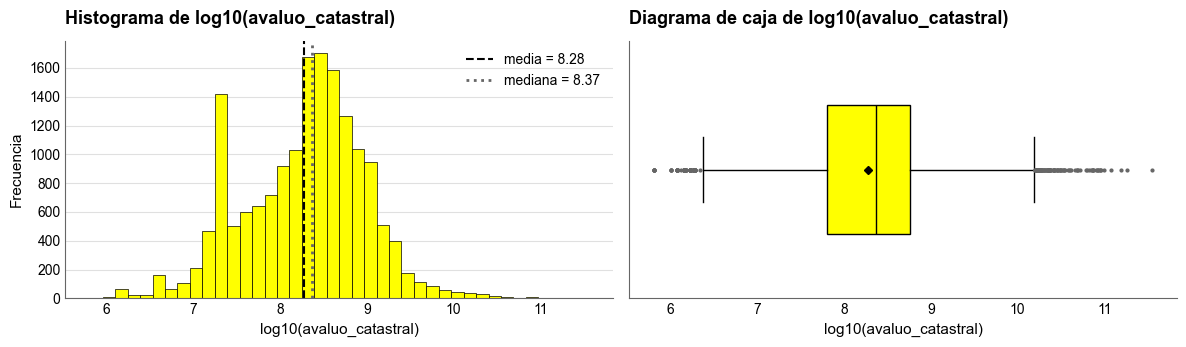

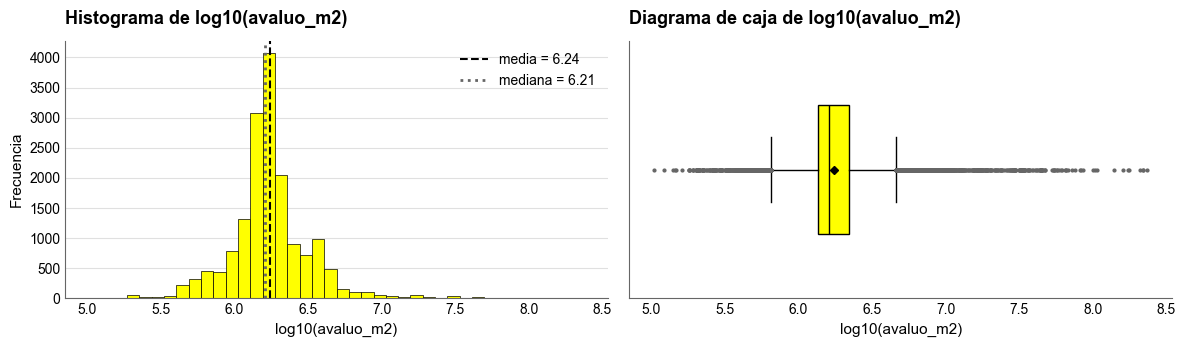

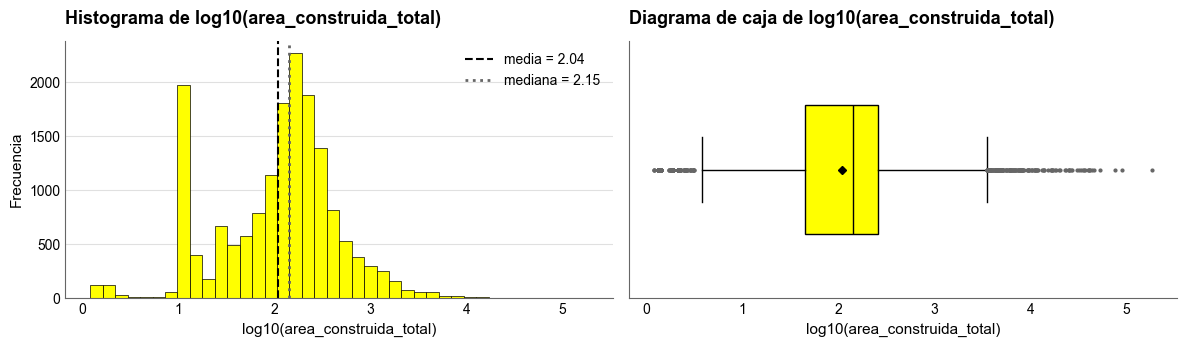

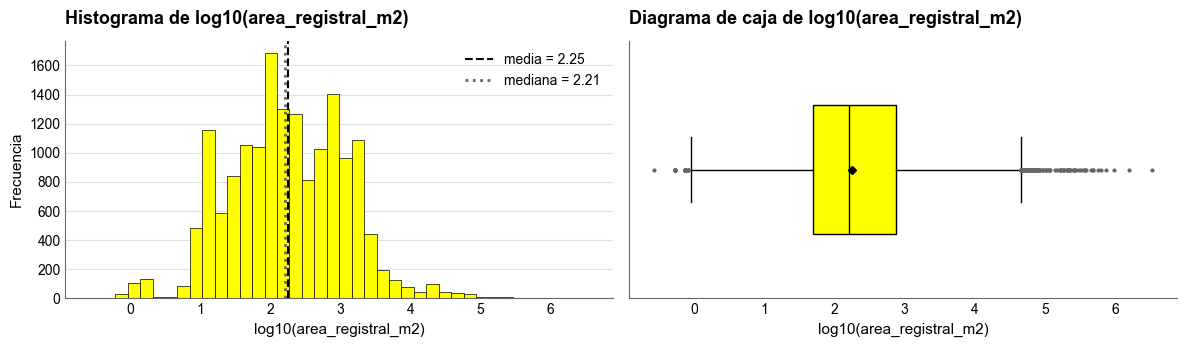

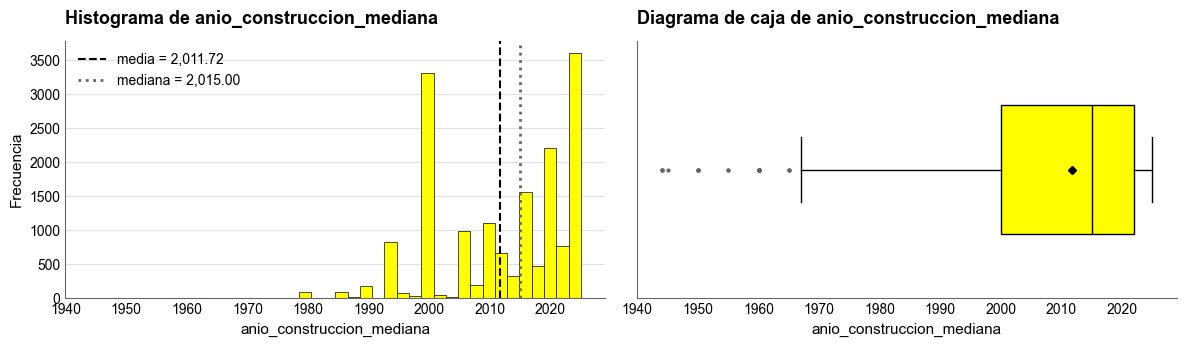

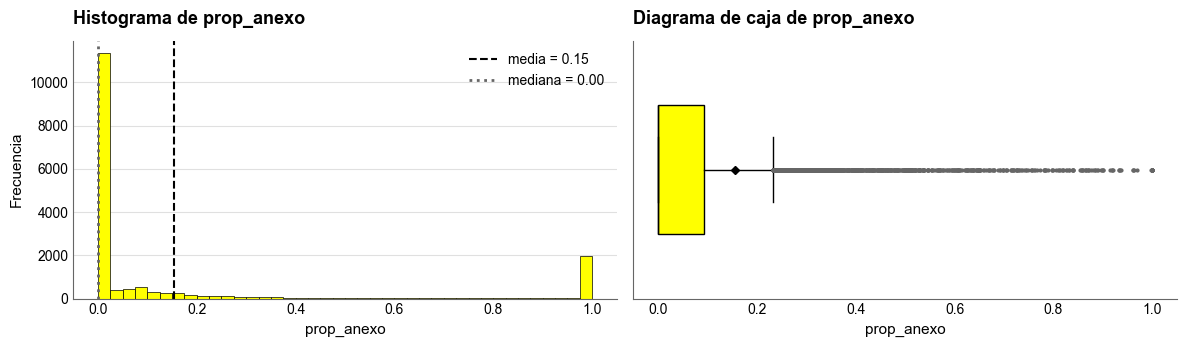

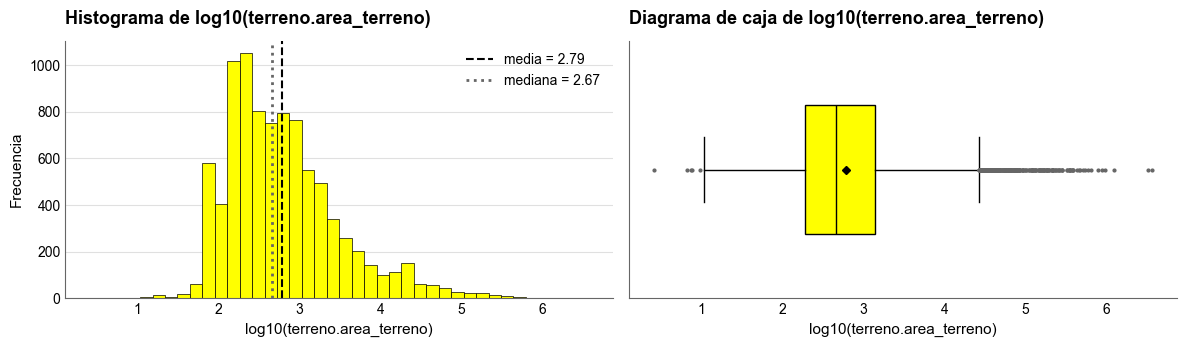

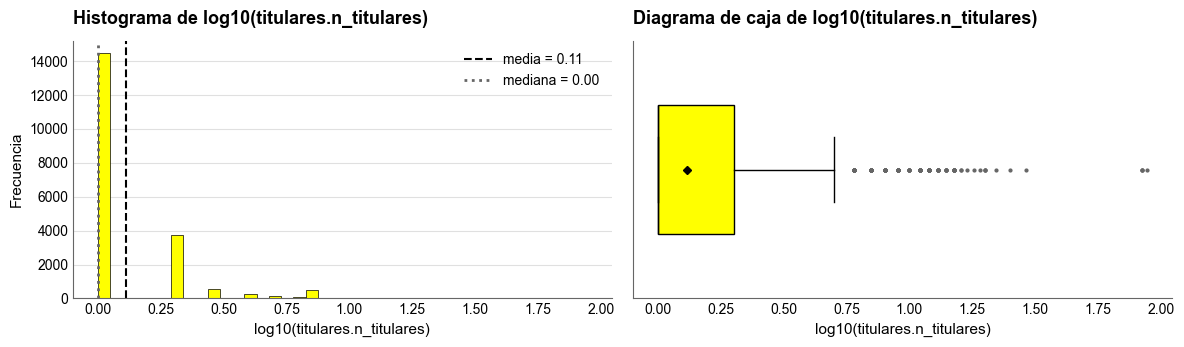

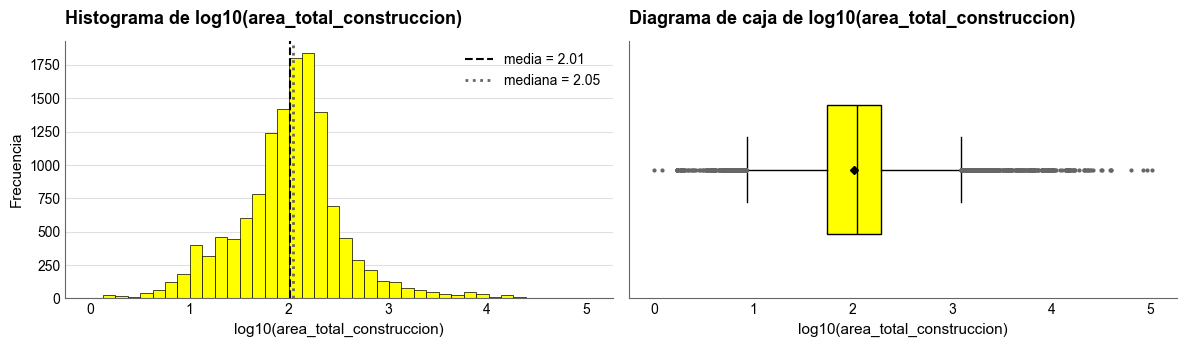

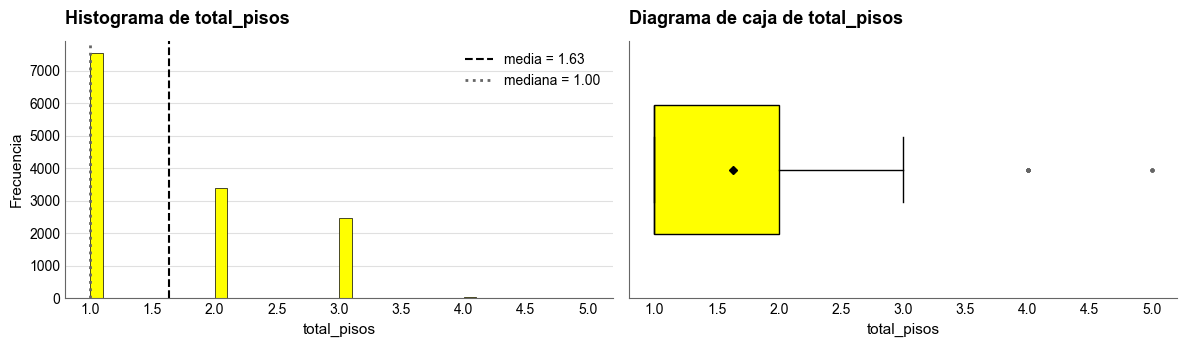

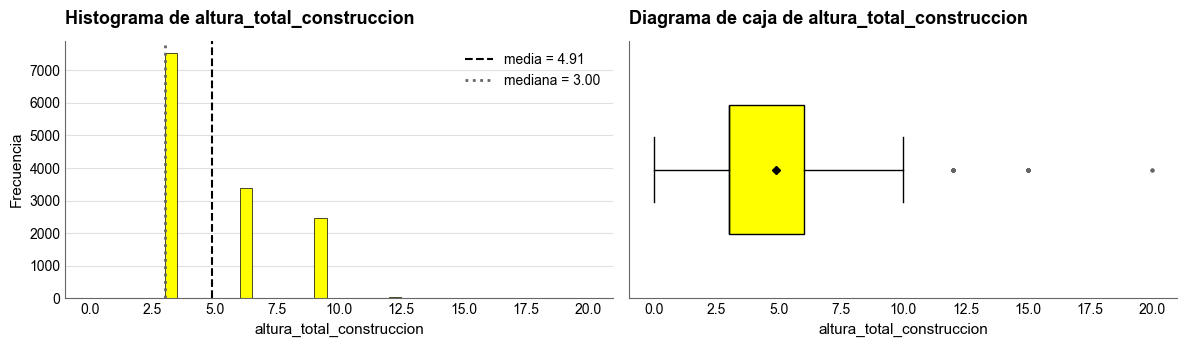

In [24]:
for col, log in [("avaluo_catastral", True), ("avaluo_m2", True), ("area_construida_total", True),
                 ("area_registral_m2", True), ("anio_construccion_mediana", False), ("prop_anexo", False)]:
    ue.graficar_numerico(base, col, log=log)
ue.graficar_numerico(predios, "terreno.area_terreno", log=True)
ue.graficar_numerico(individuales, "titulares.n_titulares", log=True)
for col, log in [("area_total_construccion", True), ("total_pisos", False), ("altura_total_construccion", False)]:
    ue.graficar_numerico(construcciones, col, log=log)

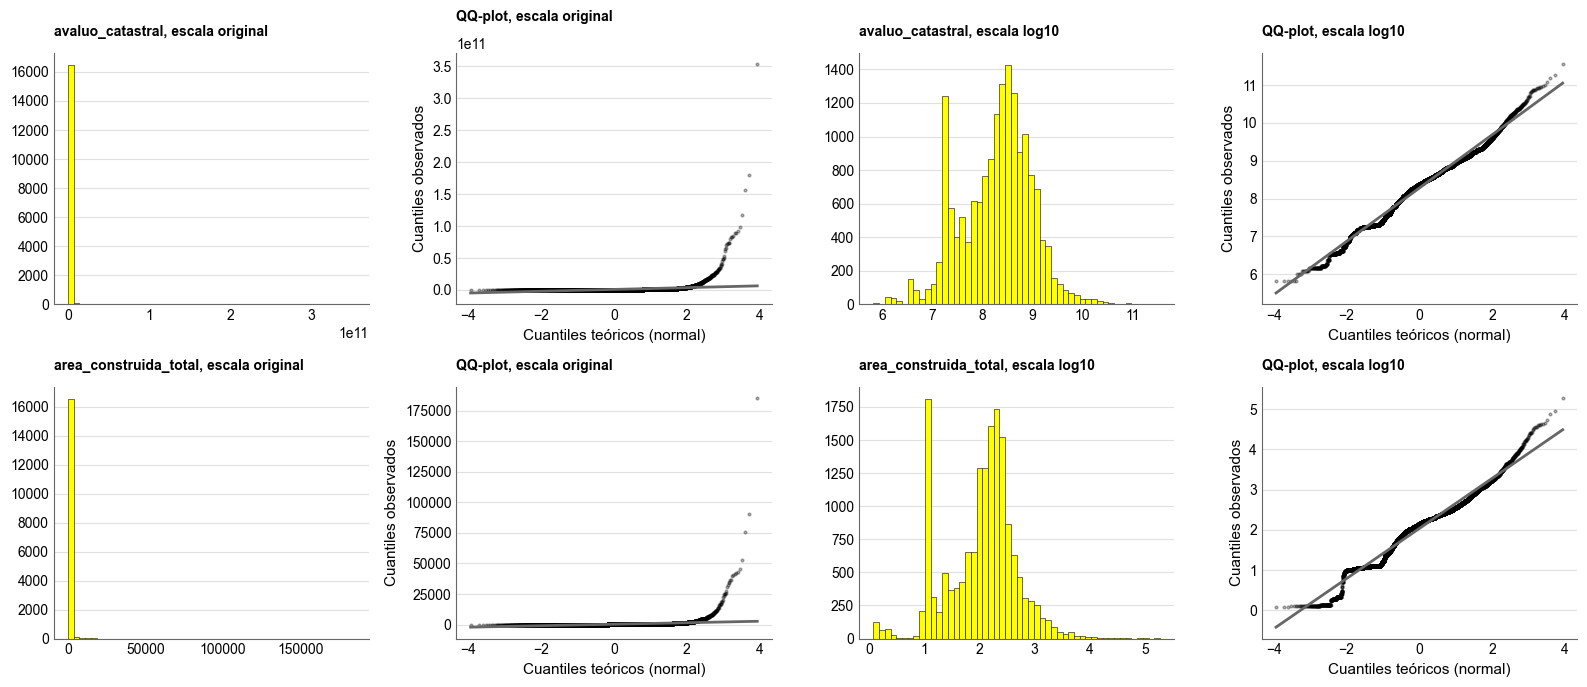

In [25]:
# Escala original frente a log10: histograma y QQ-plot del avalúo y del área construida
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for fila, col in zip(axes, ["avaluo_catastral", "area_construida_total"]):
    s = base[col][base[col] > 0]
    for k, (serie, escala) in enumerate([(s, "original"), (np.log10(s), "log10")]):
        fila[2 * k].hist(serie, bins=50, color=AMARILLO, edgecolor=NEGRO, linewidth=0.4)
        fila[2 * k].set_title(f"{col}, escala {escala}", fontsize=10)
        stats.probplot(serie, dist="norm", plot=fila[2 * k + 1])
        fila[2 * k + 1].get_lines()[0].set(color=NEGRO, markersize=2, alpha=0.3)
        fila[2 * k + 1].get_lines()[1].set(color=GRIS)
        fila[2 * k + 1].set_title(f"QQ-plot, escala {escala}", fontsize=10)
        fila[2 * k + 1].set_xlabel("Cuantiles teóricos (normal)"); fila[2 * k + 1].set_ylabel("Cuantiles observados")
plt.tight_layout(); plt.show()

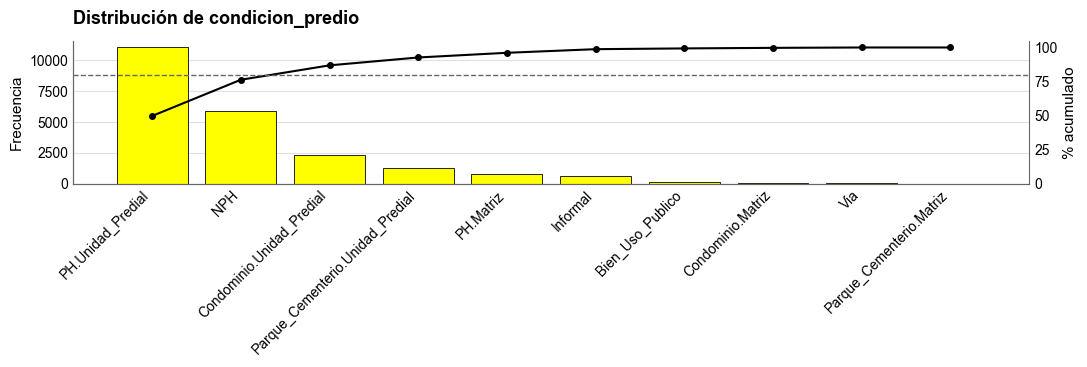

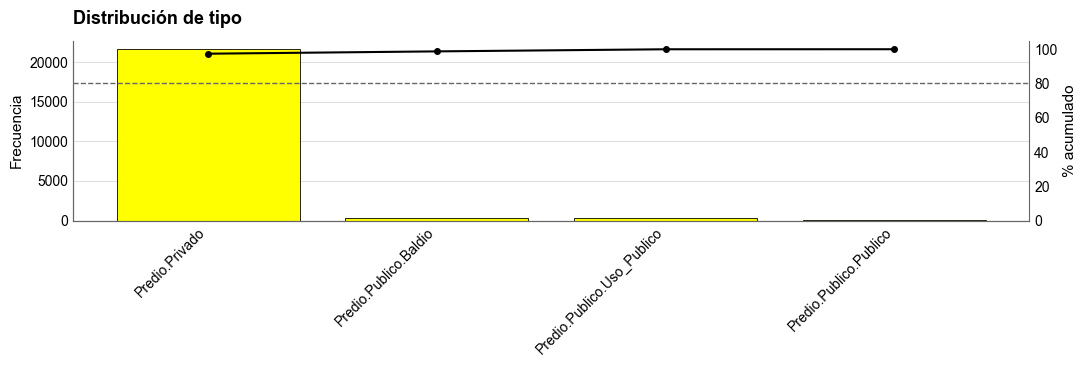

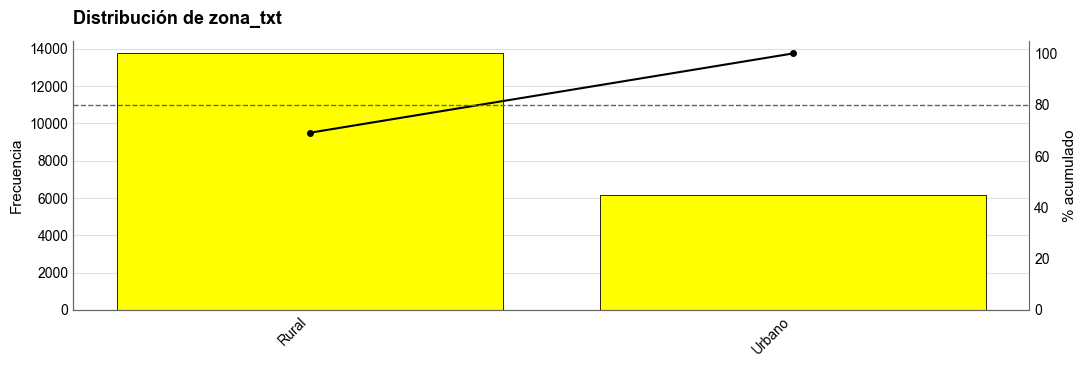

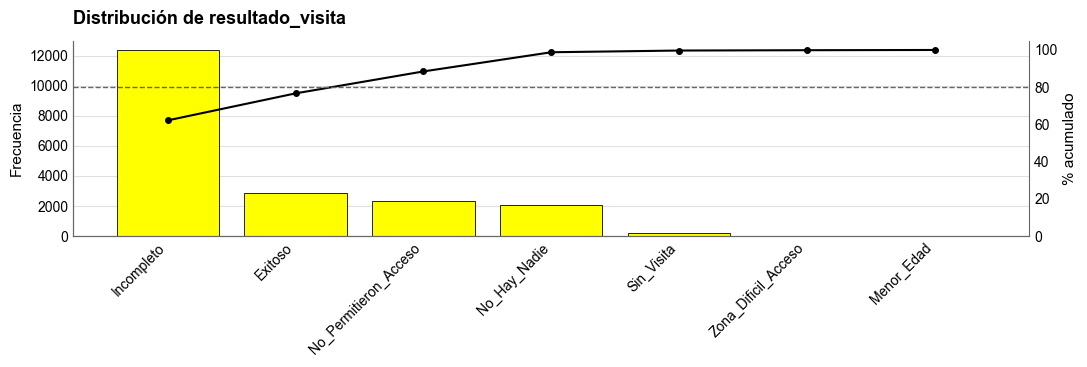

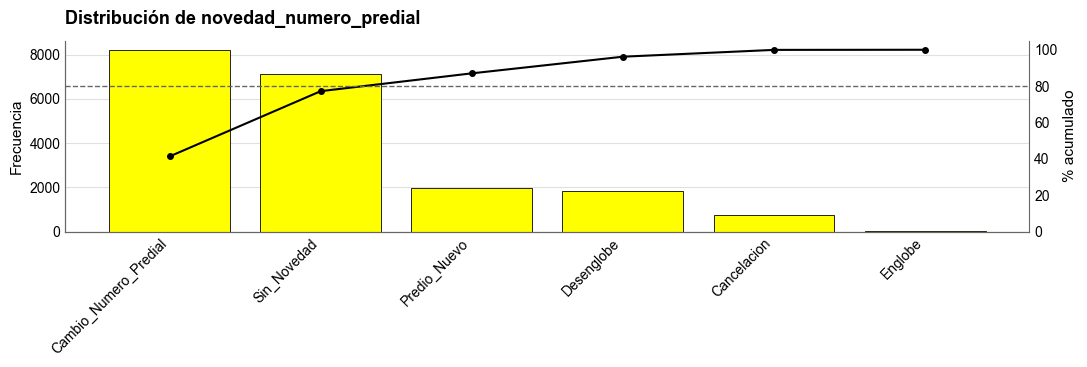

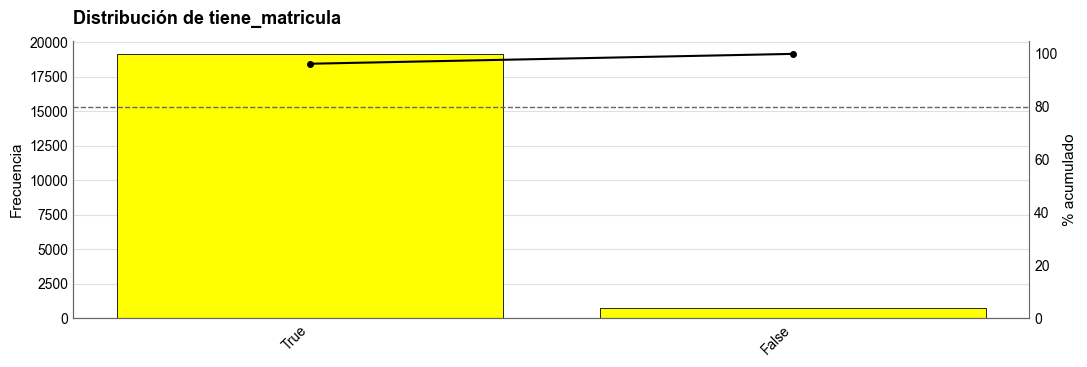

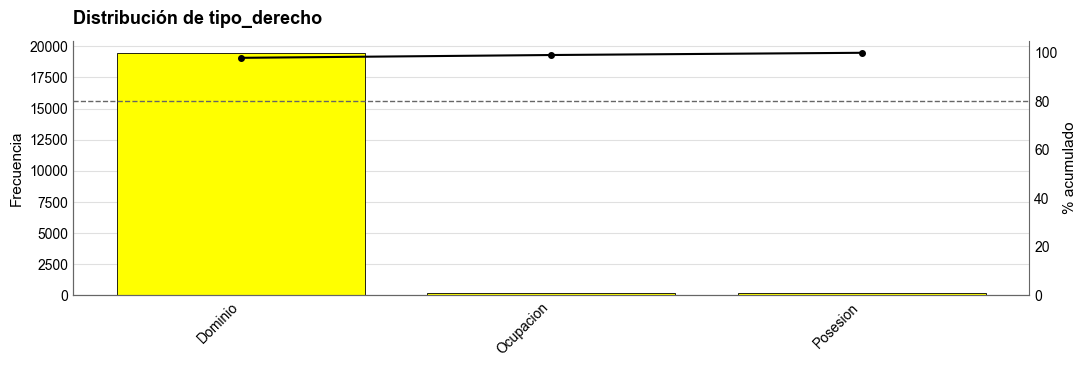

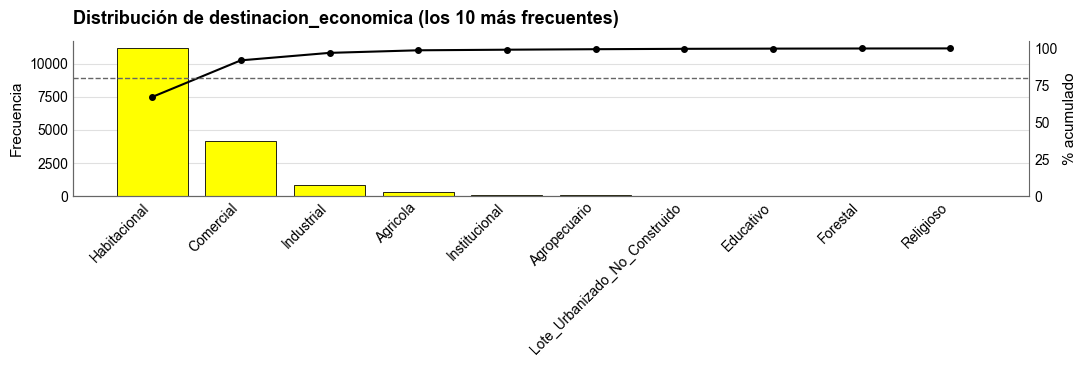

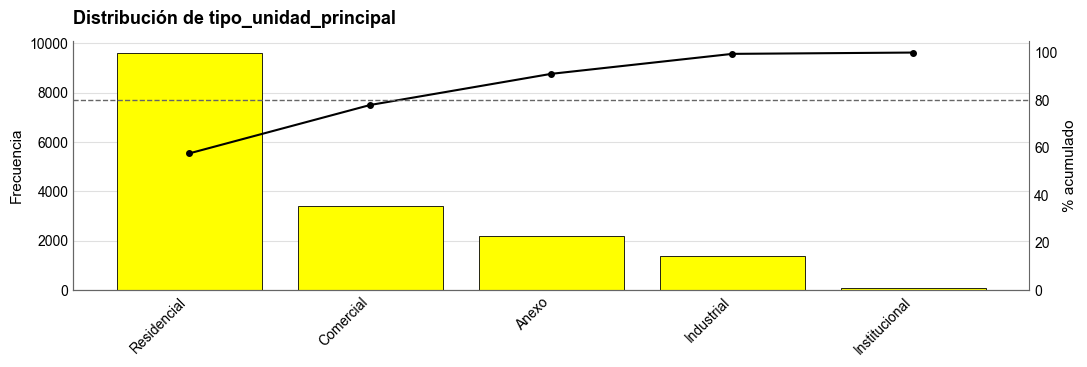

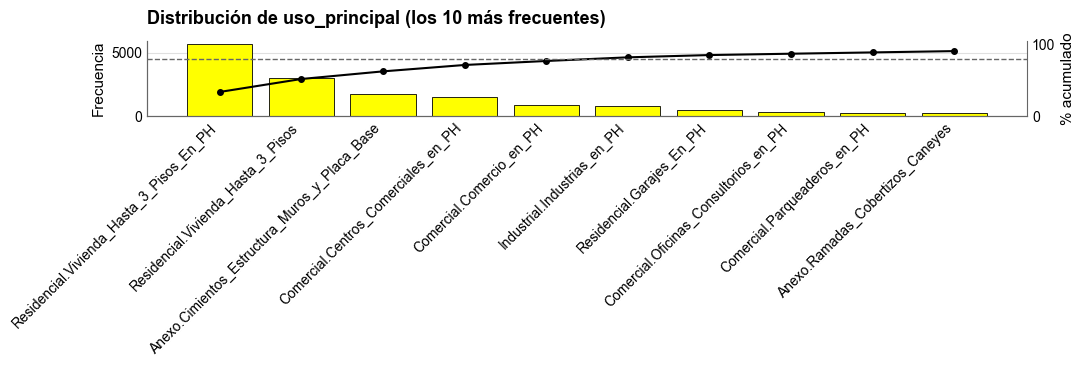

In [26]:
for col, datos, top, sobre in CUALITATIVAS:
    ue.graficar_categorico(datos, col, top=top)

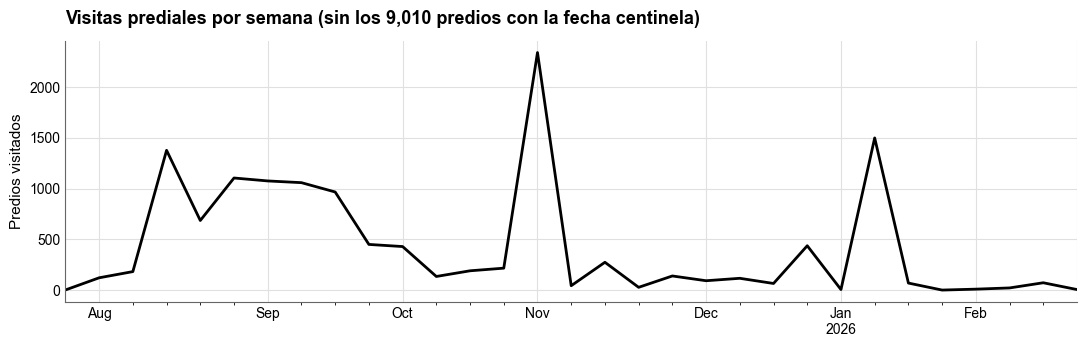

In [27]:
fig, ax = plt.subplots(figsize=(11, 3.6))
(predios.dropna(subset=["fecha_visita_valida"]).set_index("fecha_visita_valida")
        .resample("W")["id_predio"].count().plot(ax=ax, color=NEGRO))
ax.set_title(f"Visitas prediales por semana (sin los {es_fecha_centinela.sum():,} predios con la fecha centinela)")
ax.set_xlabel(""); ax.set_ylabel("Predios visitados")
plt.tight_layout(); plt.show()

**Interpretación.** Las gráficas confirman lo que muestran las tablas: en escala original los histogramas quedan comprimidos contra cero, y en log10 muestran su forma. El histograma del área construida tiene un pico cerca de 13 m² (garajes y depósitos), y el del año de construcción, un pico aislado en 2000. Las barras de régimen y de uso muestran el peso de la PH en el levantamiento.

<a id="multivariado"></a>

## 5. Análisis multivariado

Describe la distribución conjunta de varios atributos o la relación entre ellos. En la práctica casi siempre se hace de dos en dos.

### 5.1 No gráfico

- **Tablas cruzadas** entre atributos cualitativos, o cuantitativos con pocos valores.
- **Correlación** entre atributos cuantitativos: lineal (Pearson) y monótona (Spearman), y la matriz de correlación cuando son varios. Correlación no implica causalidad.
- **Regresión lineal**, para estimar un atributo a partir de otros y leer sus coeficientes. Tampoco implica causalidad y tiene supuestos que deben cumplirse.
- **Análisis de componentes principales (PCA)**, para resumir muchos atributos cuantitativos en pocos componentes.
- **Pruebas de hipótesis** (t, ANOVA, chi-cuadrado; clase 6 y tutorial 3), cuando haga falta confirmar una diferencia o una asociación.

Para no confundir la asociación de una variable con la de otra, las comparaciones del avalúo se hacen **dentro de grupos comparables** (misma zona, destinación y régimen) y por metro cuadrado construido. Toda relación que se reporta es una **asociación**, no un efecto causal.

**Cuidado:** el avalúo suma terreno y construcción. En predios con mucho terreno (sobre todo rurales) el avalúo por m² construido sube por la tierra, no por la construcción. Por eso la regresión incluye también el área registral.

#### Correlaciones

In [28]:
# log_avaluo_m2 no entra: es log_avaluo - log_area_construida, así que su correlación con esas dos
# variables sería en parte algebraica
NUMERICAS = ["log_avaluo", "log_area_construida", "log_area_registral",
             "anio_construccion_mediana", "log_n_unidades", "plantas_max", "titulares.n_titulares"]
correlaciones = {m: base[NUMERICAS].corr(method=m) for m in ["pearson", "spearman"]}
print("Pearson (lineal):"); display(correlaciones["pearson"].round(2))
print("Spearman (monótona):"); display(correlaciones["spearman"].round(2))

Pearson (lineal):


,log_avaluo,log_area_construida,log_area_registral,anio_construccion_mediana,log_n_unidades,plantas_max,titulares.n_titulares
log_avaluo,1.00,0.92,0.91,-0.12,0.62,0.17,0.06
log_area_construida,0.92,1.00,0.83,-0.11,0.68,0.19,0.06
log_area_registral,0.91,0.83,1.00,-0.13,0.55,0.14,0.06
anio_construccion_mediana,-0.12,-0.11,-0.13,1.00,-0.12,-0.01,-0.05
log_n_unidades,0.62,0.68,0.55,-0.12,1.00,0.26,0.10
plantas_max,0.17,0.19,0.14,-0.01,0.26,1.00,0.01
titulares.n_titulares,0.06,0.06,0.06,-0.05,0.10,0.01,1.00


Spearman (monótona):


,log_avaluo,log_area_construida,log_area_registral,anio_construccion_mediana,log_n_unidades,plantas_max,titulares.n_titulares
log_avaluo,1.00,0.90,0.90,-0.15,0.61,0.18,0.15
log_area_construida,0.90,1.00,0.80,-0.17,0.70,0.19,0.15
log_area_registral,0.90,0.80,1.00,-0.12,0.54,0.18,0.12
anio_construccion_mediana,-0.15,-0.17,-0.12,1.00,-0.13,-0.05,-0.01
log_n_unidades,0.61,0.70,0.54,-0.13,1.00,0.28,0.18
plantas_max,0.18,0.19,0.18,-0.05,0.28,1.00,0.06
titulares.n_titulares,0.15,0.15,0.12,-0.01,0.18,0.06,1.00


In [29]:
# Escala de las correlaciones: Pearson en escala original, Pearson en log10 y Spearman (que no depende de la escala).
# Si Pearson en log10 se acerca a Spearman y Pearson en escala original no, la relación es multiplicativa
# y unos pocos predios enormes dominan el cálculo en escala original
PARES = [("avaluo_catastral", "area_construida_total"), ("avaluo_catastral", "area_registral_m2"),
         ("area_construida_total", "area_registral_m2")]
filas = {}
for a, b in PARES:
    d = base[[a, b]].dropna()
    d = d[(d > 0).all(axis=1)]
    filas[f"{a} ~ {b}"] = {"n": len(d), "Pearson original": d.corr().iloc[0, 1],
                           "Pearson log10": np.log10(d).corr().iloc[0, 1], "Spearman": d.corr("spearman").iloc[0, 1]}
pd.DataFrame(filas).T.style.format({"n": "{:,.0f}", "Pearson original": "{:.3f}", "Pearson log10": "{:.3f}",
                                    "Spearman": "{:.3f}"})

,n,Pearson original,Pearson log10,Spearman
avaluo_catastral ~ area_construida_total,"16,705",0.868,0.921,0.902
avaluo_catastral ~ area_registral_m2,"16,246",0.262,0.908,0.896
area_construida_total ~ area_registral_m2,"16,246",0.171,0.819,0.790


#### Tablas cruzadas

In [30]:
# Mediana del avalúo por m² por destinación, régimen y zona (celdas con al menos 30 predios en alguna zona)
TOP_DESTINOS = base["destinacion_economica"].value_counts().head(6).index
sub = base[base["destinacion_economica"].isin(TOP_DESTINOS)]
regimen = sub["condicion_predio"].str.split(".").str[0].rename("regimen")
estratificada = (sub.groupby(["destinacion_economica", regimen, "zona_txt"])["avaluo_m2"]
                   .agg(n="size", mediana="median").unstack("zona_txt"))
estratificada[estratificada["n"].fillna(0).max(axis=1) >= 30].round(0)

n            mediana           
zona_txt                           Rural  Urbano      Rural     Urbano
destinacion_economica regimen                                         
Agricola              NPH         268.00     NaN 5547275.00        NaN
Agropecuario          NPH          42.00     NaN 7288019.00        NaN
Comercial             Condominio  145.00     NaN 1570902.00        NaN
                      NPH         181.00  179.00 1888835.00 1843194.00
                      PH         3458.00  165.00 1576870.00 1780000.00
Habitacional          Condominio 1288.00  217.00 3701238.00 1555117.00
                      Informal     88.00   39.00  566438.00  682418.00
                      NPH        1564.00 1324.00 1462777.00 1467217.00
                      PH         3660.00 3004.00 1787216.00 1594067.00
Industrial            Condominio   31.00     NaN 1275129.00        NaN
                      NPH         110.00   12.00 1982295.00 1764271.00
                      PH          688.00     NaN 1741474.00        NaN
Institucional         NPH          42.00   23.00 2029391.00 2077339.00

In [31]:
tabla = pd.crosstab(base["destinacion_economica"], base["zona_txt"])
print(f"V de Cramér destinación-zona: {ue.cramers_v(tabla):.3f}")
pd.crosstab(base["destinacion_economica"], base["zona_txt"], normalize="columns").mul(100).round(1).query("Rural + Urbano > 0")

V de Cramér destinación-zona: 0.361


zona_txt,Rural,Urbano
destinacion_economica,,
Agricola,2.50,0.00
Agroforestal,0.10,0.00
Agropecuario,0.50,0.00
Comercial,32.40,6.90
Educativo,0.20,0.00
Forestal,0.10,0.00
Habitacional,56.60,91.00
Industrial,7.10,0.30
Institucional,0.40,0.50


In [32]:
# Anexos: predios con la mayoría de su área en anexos y cómo cambia el avalúo por m².
# El avalúo por m² convencional solo existe donde hay área convencional: la tabla dice para cuántos
mayoria_anexo = (base["prop_anexo"] > 0.5).map({True: "Mayoría anexos", False: "Mayoría convencional"})
print(f"Predios de la base con más de la mitad del área en anexos: {(base['prop_anexo'] > 0.5).sum():,} "
      f"({(base['prop_anexo'] > 0.5).mean():.1%})")
display(base.assign(con_convencional=base["area_convencional"] > 0).groupby(mayoria_anexo).agg(
    n=("id_predio", "size"),
    pct_con_area_convencional=("con_convencional", lambda s: s.mean() * 100),
    mediana_avaluo_m2=("avaluo_m2", "median"),
    mediana_avaluo_m2_convencional=("avaluo_m2_convencional", "median"),
).round(1))
print("La mediana del avalúo por m² convencional se calcula solo sobre los predios con área convencional, y divide el "
      "avalúo total (con anexos y terreno) por esa área: no es comparable con el avalúo por m² construido.")
pd.crosstab(base["destinacion_economica"], mayoria_anexo, normalize="columns").mul(100).round(1) \
    .sort_values("Mayoría anexos", ascending=False).head(8)

Predios de la base con más de la mitad del área en anexos: 2,174 (13.0%)


,n,pct_con_area_convencional,mediana_avaluo_m2,mediana_avaluo_m2_convencional
prop_anexo,,,,
Mayoría anexos,2174,10.50,828811.40,5943625.10
Mayoría convencional,14531,100.00,1677704.90,1720000.00


La mediana del avalúo por m² convencional se calcula solo sobre los predios con área convencional, y divide el avalúo total (con anexos y terreno) por esa área: no es comparable con el avalúo por m² construido.


prop_anexo,Mayoría anexos,Mayoría convencional
destinacion_economica,,
Habitacional,80.30,65.00
Comercial,8.40,27.20
Agricola,5.20,1.20
Industrial,2.00,5.50
Lote_Urbanizado_No_Construido,1.40,0.10
Agropecuario,1.00,0.20
Lote_Urbanizable_No_Urbanizado,0.40,0.00
Institucional,0.40,0.40


In [33]:
# Novedades del número predial por régimen (predios individuales, % por fila)
pd.crosstab(individuales["condicion_predio"], individuales["novedad_numero_predial"], normalize="index").mul(100).round(1)

novedad_numero_predial,Cambio_Numero_Predial,Cancelacion,Desenglobe,Englobe,Predio_Nuevo,Sin_Novedad
condicion_predio,,,,,,
Condominio.Unidad_Predial,72.10,2.30,5.50,0.00,11.20,8.90
Informal,28.10,23.90,0.20,0.00,2.50,45.30
NPH,0.40,8.40,4.60,0.20,5.60,80.90
PH.Unidad_Predial,57.40,0.50,12.90,0.00,12.10,17.10


In [34]:
# Matrícula inmobiliaria: % sin matrícula por régimen, tipo de derecho y tipo de fuente
for col in ["condicion_predio", "tipo_derecho", "tipo_fuente"]:
    display(individuales.groupby(col)["tiene_matricula"]
            .agg(n="size", pct_sin_matricula=lambda s: (~s).mean() * 100)
            .round(1).sort_values("pct_sin_matricula", ascending=False))
tabla_mat = pd.crosstab(~individuales["tiene_matricula"], individuales["zona_txt"])
chi2, p, _, _ = stats.chi2_contingency(tabla_mat)
print(f"Sin matrícula vs. zona: chi2={chi2:.1f}, p={p:.3g}, V de Cramér={ue.cramers_v(tabla_mat):.3f}")

,n,pct_sin_matricula
condicion_predio,,
Informal,591,99.20
NPH,5903,2.60
Condominio.Unidad_Predial,2351,0.00
PH.Unidad_Predial,11052,0.00


,n,pct_sin_matricula
tipo_derecho,,
Ocupacion,231,100.00
Posesion,182,99.50
Dominio,19484,1.70


,n,pct_sin_matricula
tipo_fuente,,
Sin_Documento,752,98.50
Documento_Publico.Acto_Administrativo,64,0.00
Documento_Publico.Escritura_Publica,18591,0.00
Documento_Publico.Sentencia_Judicial,490,0.00


Sin matrícula vs. zona: chi2=38.7, p=4.91e-10, V de Cramér=0.044


#### Prueba de hipótesis: avalúo por m² urbano y rural

*Provisional hasta que se defina la pregunta de negocio.* Se compara dentro de una sola destinación (habitacional) y **dentro de cada régimen** (NPH, unidad de PH, unidad de condominio). El régimen es un confusor: su peso es muy distinto entre zonas (hay muchas más unidades de condominio en la zona rural) y el avalúo por m² depende de él, así que la comparación sin estratificar puede reflejar la mezcla y no la zona. Cada prueba revisa sus supuestos (QQ-plot y Levene) y reporta tamaño de efecto.

Para cada régimen: $H_0$, la distribución de log10(avalúo por m²) es la misma en zona urbana y rural; $H_1$, es distinta (dos colas).

zona_txt,Rural,Urbano
condicion_predio,,
Condominio.Unidad_Predial,1288,217
Informal,88,39
NPH,1564,1324
PH.Unidad_Predial,3660,3004



RÉGIMEN: NPH


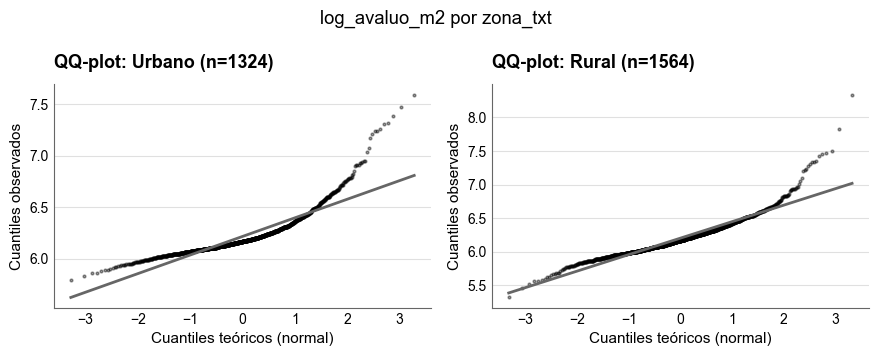

Levene (centrado en la mediana): W=76.573, p=3.541e-18 -> varianzas distintas

=== log_avaluo_m2: Urbano vs Rural ===
Urbano: n=1324, media=6.216, mediana=6.166
Rural: n=1564, media=6.202, mediana=6.165
Welch: t=1.648, p=0.09952, IC95% de la diferencia=[-0.003, 0.031], d de Cohen=0.060
Mann-Whitney: U=1098475, p=0.004708, P(Urbano > Rural)=0.530

RÉGIMEN: PH.Unidad_Predial


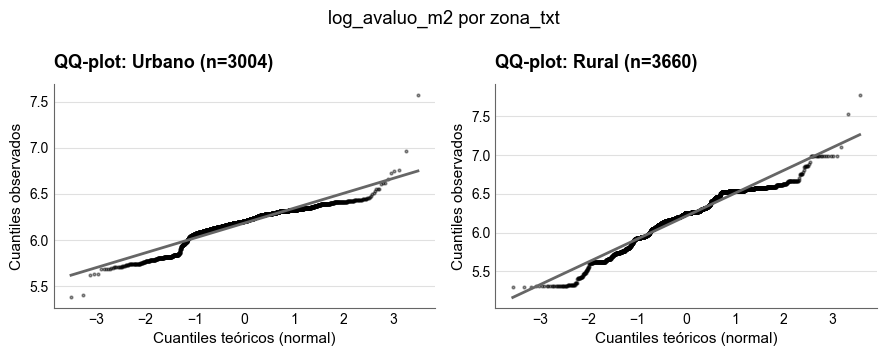

Levene (centrado en la mediana): W=707.763, p=2.739e-148 -> varianzas distintas

=== log_avaluo_m2: Urbano vs Rural ===
Urbano: n=3004, media=6.181, mediana=6.203
Rural: n=3660, media=6.212, mediana=6.252
Welch: t=-5.210, p=1.956e-07, IC95% de la diferencia=[-0.042, -0.019], d de Cohen=-0.122
Mann-Whitney: U=4929985, p=3.869e-13, P(Urbano > Rural)=0.448

RÉGIMEN: Condominio.Unidad_Predial


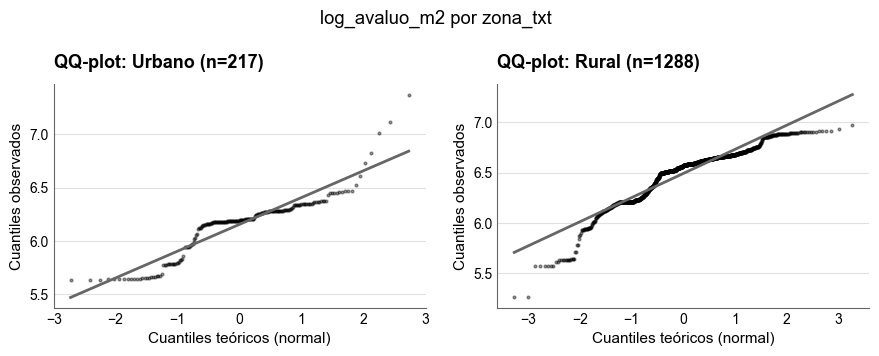

Levene (centrado en la mediana): W=0.160, p=0.6894 -> no se rechaza igualdad de varianzas

=== log_avaluo_m2: Urbano vs Rural ===
Urbano: n=217, media=6.156, mediana=6.192
Rural: n=1288, media=6.491, mediana=6.568
Welch: t=-17.294, p=2.564e-46, IC95% de la diferencia=[-0.373, -0.297], d de Cohen=-1.320
Mann-Whitney: U=44776, p=7.211e-58, P(Urbano > Rural)=0.160


In [35]:
habitacional = base[base["destinacion_economica"] == "Habitacional"]
display(pd.crosstab(habitacional["condicion_predio"], habitacional["zona_txt"]))

ESTRATOS = ["NPH", "PH.Unidad_Predial", "Condominio.Unidad_Predial"]
resultados = {}
for estrato in ESTRATOS:
    print("\n" + "=" * 80 + f"\nRÉGIMEN: {estrato}")
    datos = habitacional[habitacional["condicion_predio"] == estrato]
    resultados[estrato] = (datos, ue.comparar_dos_grupos(datos, "zona_txt", "Urbano", "Rural", "log_avaluo_m2"))

In [36]:
# Resumen: la diferencia en porcentaje y en pesos por m² (medianas), con y sin estratificar
def resumen_estrato(datos, res=None):
    med = datos.groupby("zona_txt")["avaluo_m2"].median()
    med_log = datos.groupby("zona_txt")["log_avaluo_m2"].median()
    urbano = datos.loc[datos["zona_txt"] == "Urbano", "log_avaluo_m2"]
    rural = datos.loc[datos["zona_txt"] == "Rural", "log_avaluo_m2"]
    mw = res["mann_whitney"] if res else stats.mannwhitneyu(urbano, rural)
    return {"n urbano": len(urbano), "n rural": len(rural),
            "mediana urbano ($/m²)": med["Urbano"], "mediana rural ($/m²)": med["Rural"],
            "diferencia ($/m²)": med["Urbano"] - med["Rural"],
            "diferencia (%)": (10 ** (med_log["Urbano"] - med_log["Rural"]) - 1) * 100,
            "p Mann-Whitney": mw.pvalue, "P(urbano > rural)": mw.statistic / (len(urbano) * len(rural))}

pd.DataFrame({"Sin estratificar": resumen_estrato(habitacional),
              **{e: resumen_estrato(d, r) for e, (d, r) in resultados.items()}}).T.style.format({
    "n urbano": "{:,.0f}", "n rural": "{:,.0f}", "mediana urbano ($/m²)": "{:,.0f}",
    "mediana rural ($/m²)": "{:,.0f}", "diferencia ($/m²)": "{:,.0f}", "diferencia (%)": "{:+.1f}",
    "p Mann-Whitney": "{:.3g}", "P(urbano > rural)": "{:.3f}"})

,n urbano,n rural,mediana urbano ($/m²),mediana rural ($/m²),diferencia ($/m²),diferencia (%),p Mann-Whitney,P(urbano > rural)
Sin estratificar,"4,584","6,600","1,549,846","1,788,472","-238,625",-13.3,1.2e-54,0.414
NPH,"1,324","1,564","1,467,217","1,462,777","4,440",+0.3,0.00471,0.530
PH.Unidad_Predial,"3,004","3,660","1,594,067","1,787,216","-193,149",-10.8,3.87e-13,0.448
Condominio.Unidad_Predial,217,"1,288","1,555,117","3,701,238","-2,146,121",-58.0,7.21e-58,0.160


**Interpretación.** Los supuestos de la prueba t se cumplen mal. Los QQ-plots muestran colas pesadas en NPH y escalones en PH y condominio: muchos predios comparten el mismo valor por m², lo que es coherente con un avalúo calculado por zonas homogéneas. Levene rechaza la igualdad de varianzas en NPH y PH. Por eso se reporta Mann-Whitney, con la probabilidad de superioridad como tamaño de efecto.

Sin estratificar, el avalúo por m² urbano es 13 % menor que el rural. Esa diferencia sale sobre todo de la mezcla de regímenes:

- en NPH, la diferencia es despreciable (+0,3 %; P(urbano > rural) = 0,53);
- en PH, el urbano es 11 % menor, con un efecto pequeño (P = 0,45);
- en condominio, el urbano es 58 % menor, con un efecto grande (P = 0,16), aunque solo hay 217 condominios urbanos.

Los condominios rurales tienen el avalúo por m² construido más alto de la base (mediana de 3,7 millones), probablemente por el valor de lotes privados grandes.

Implicación: la zona por sí sola no permite comparar avalúos por m²; las comparaciones entre zonas se hacen dentro de cada régimen. Los condominios rurales forman un grupo propio, con avalúos por m² muy altos, que conviene revisar con el gestor catastral.

#### Componentes principales (PCA) de las características del predio

Solo con las características (áreas construida y registral, antigüedad, número de unidades, plantas), sin el avalúo: así el PCA describe la tipología de los predios, en vez de repetir que el avalúo sigue al tamaño. Se dejan fuera los predios con el año sospechoso (3.3). El avalúo se proyecta después como variable suplementaria (su correlación con cada componente) y la zona, que tampoco entra, se usa para colorear el biplot (5.2).

In [37]:
X_cols = ["log_area_construida", "log_area_registral", "anio_construccion_mediana", "log_n_unidades", "plantas_max"]
X = base.loc[base["anio_sospechoso"] == 0, X_cols].dropna()
X_std = StandardScaler().fit_transform(X)
pca = PCA(random_state=SEMILLA).fit(X_std)
comp = pca.transform(X_std)
print(f"Predios en el PCA: {len(X):,} (sin año sospechoso ni faltantes en las variables)")

nombres_pc = [f"PC{i + 1}" for i in range(len(X_cols))]
varianza = pd.DataFrame({"varianza explicada (%)": pca.explained_variance_ratio_ * 100,
                         "acumulada (%)": np.cumsum(pca.explained_variance_ratio_) * 100}, index=nombres_pc)
loadings = pd.DataFrame(pca.components_.T, index=X_cols, columns=nombres_pc)
suplementaria = pd.Series([np.corrcoef(base.loc[X.index, "log_avaluo"], comp[:, k])[0, 1] for k in range(comp.shape[1])],
                          index=nombres_pc, name="corr. con log_avaluo (suplementaria)")
display(varianza.round(1))
pd.concat([loadings, suplementaria.to_frame().T]).round(3)

Predios en el PCA: 13,142 (sin año sospechoso ni faltantes en las variables)


,varianza explicada (%),acumulada (%)
PC1,49.70,49.70
PC2,19.90,69.60
PC3,18.50,88.10
PC4,9.30,97.40
PC5,2.60,100.00


,PC1,PC2,PC3,PC4,PC5
log_area_construida,0.59,0.08,-0.20,-0.19,0.76
log_area_registral,0.56,0.02,-0.22,-0.50,-0.62
anio_construccion_mediana,-0.08,0.99,-0.09,0.05,-0.05
log_n_unidades,0.52,-0.01,0.02,0.83,-0.20
plantas_max,0.23,0.12,0.95,-0.16,0.01
corr. con log_avaluo (suplementaria),0.92,0.05,-0.20,-0.21,0.04


**Interpretación.** Tres componentes resumen el 88 % de la variación de las características del predio:

- PC1 (50 %) es el tamaño: pesa casi igual el área construida, el área registral y el número de unidades;
- PC2 (20 %) es la antigüedad: casi solo el año de construcción;
- PC3 (19 %) es la altura: casi solo el número de plantas.

El tamaño, la antigüedad y la altura varían de forma casi independiente entre sí. El avalúo se asocia casi por completo con el tamaño (correlación de 0,92 con PC1), y muy poco con la antigüedad (0,05) o la altura (−0,20). En el biplot, los predios urbanos y rurales se superponen: tienen tamaños, antigüedades y alturas parecidos.

Implicación: el tamaño concentra casi toda la información sobre el avalúo; el año y la altura aportan poco por sí solos.

#### Regresión del log-avalúo y residuos frente a comparables

Una regresión lineal de log10(avalúo) sobre área construida, área registral (que recoge el terreno), antigüedad, zona, destinación, régimen y tipo de unidad da un **avalúo esperado** para cada predio según sus características. Los coeficientes describen asociaciones condicionadas, no efectos causales.

**Qué mide el residuo.** El avalúo catastral no es un precio de mercado: según el diccionario, es un porcentaje del avalúo comercial que calcula el propio catastro con zonas homogéneas físicas y geoeconómicas y tablas de valores de construcción. Un R² alto indica que la regresión reconstruye buena parte de esa fórmula. El residuo recoge lo que la fórmula usa y la regresión no tiene, sobre todo la zona geoeconómica y el valor del terreno. **No mide si un predio está sobre o subavaluado frente al mercado**: para eso haría falta un avalúo comercial o precios de transacción de referencia. Además, `10 ** ajustado` es la mediana condicional del avalúo, no su media.

**Inferencia.** Las unidades de un mismo edificio o conjunto comparten características que el modelo no ve, así que sus errores no son independientes: los errores estándar se agrupan por predio matriz (cada predio sin matriz es su propio grupo) y son robustos a heterocedasticidad. Las categorías de referencia son las más frecuentes, para que el VIF mida bien la colinealidad entre destinación y tipo de unidad.

In [38]:
def agrupar_raras(s, minimo=30):
    frecuentes = s.value_counts()[lambda v: v >= minimo].index
    return s.where(s.isin(frecuentes), "Otra")


modelo_df = base.assign(
    destino=agrupar_raras(base["destinacion_economica"]),
    condicion=agrupar_raras(base["condicion_predio"]),
    tipo_unidad=agrupar_raras(base["tipo_unidad_principal"]),
).dropna(subset=["log_avaluo", "log_area_construida", "log_area_registral", "anio_construccion_mediana"])
grupos = modelo_df["id_predio_matriz"].fillna(modelo_df["id_predio"])

formula = ("log_avaluo ~ log_area_construida + log_area_registral + anio_construccion_mediana + anio_sospechoso"
           " + C(zona_txt) + C(destino, Treatment('Habitacional'))"
           " + C(condicion, Treatment('PH.Unidad_Predial')) + C(tipo_unidad, Treatment('Residencial'))")
ols = smf.ols(formula, data=modelo_df)
modelo = ols.fit(cov_type="cluster", cov_kwds={"groups": grupos})
modelo_ingenuo = ols.fit()

bp = het_breuschpagan(modelo.resid, modelo.model.exog)
razon_ee = (modelo.bse / modelo_ingenuo.bse).drop("Intercept")
print(f"n={int(modelo.nobs):,} | grupos (matrices o predios sueltos)={grupos.nunique():,} | R² ajustado={modelo.rsquared_adj:.3f}")
print(f"Breusch-Pagan: LM={bp[0]:,.1f}, p={bp[1]:.3g} -> " + ("heterocedasticidad" if bp[1] < 0.05 else "sin evidencia de heterocedasticidad"))
print(f"Errores estándar agrupados / ingenuos: mediana {razon_ee.median():.1f}, rango [{razon_ee.min():.1f}, {razon_ee.max():.1f}]")
modelo.summary().tables[1]

n=16,205 | grupos (matrices o predios sueltos)=4,409 | R² ajustado=0.960
Breusch-Pagan: LM=3,006.4, p=0 -> heterocedasticidad
Errores estándar agrupados / ingenuos: mediana 4.5, rango [1.8, 9.2]


,coef,std err,z,P>|z|,[0.025,0.975]
Intercept,-1.0899,1.630,-0.669,0.504,-4.285,2.105
C(zona_txt)[T.Urbano],0.1943,0.015,13.172,0.000,0.165,0.223
"C(destino, Treatment('Habitacional'))[T.Agricola]",0.1524,0.038,3.969,0.000,0.077,0.228
"C(destino, Treatment('Habitacional'))[T.Agropecuario]",0.0465,0.073,0.640,0.522,-0.096,0.189
"C(destino, Treatment('Habitacional'))[T.Comercial]",0.0999,0.025,3.978,0.000,0.051,0.149
"C(destino, Treatment('Habitacional'))[T.Industrial]",-0.0196,0.058,-0.339,0.734,-0.133,0.094
"C(destino, Treatment('Habitacional'))[T.Institucional]",0.0016,0.057,0.027,0.978,-0.111,0.114
"C(destino, Treatment('Habitacional'))[T.Lote_Urbanizado_No_Construido]",0.3435,0.041,8.300,0.000,0.262,0.425
"C(destino, Treatment('Habitacional'))[T.Otra]",-0.0197,0.076,-0.259,0.796,-0.169,0.129
"C(condicion, Treatment('PH.Unidad_Predial'))[T.Condominio.Unidad_Predial]",0.0630,0.034,1.848,0.065,-0.004,0.130


**¿Y la regresión en escala original?** Un modelo lineal con el avalúo en pesos y las áreas en m² (las mismas variables, sin logaritmos), para comparar con el modelo en log10.

**El R² no se compara entre escalas.** El R² es la proporción de la varianza explicada, y la varianza en pesos y en log10 son cosas distintas. En pesos, la varianza se concentra en muy pocos predios (la tabla lo cuantifica), así que el R² en pesos mide sobre todo qué tan bien se ajustan los predios más caros; en log10 mide errores relativos y cada predio pesa parecido. Por eso los dos modelos se comparan aquí con las mismas métricas y en la misma escala (pesos), devolviendo el modelo log10 a pesos con `10 ** ajustado`. El R² en log10 (0,96 aprox.) indica que, en términos relativos, el avalúo es casi una función de pocas variables; no quiere decir que el modelo explique el 96 % del avalúo en pesos.

In [39]:
y = modelo_df["avaluo_catastral"]
desvio = (y - y.mean()) ** 2
mas_alejados = desvio.sort_values(ascending=False)
print("Peso de los predios más alejados de la media en la varianza total en pesos:",
      {f"{k} predios": f"{mas_alejados.head(k).sum() / desvio.sum():.1%}" for k in (1, 10, 100)}, f"de {len(y):,}")

# Modelo lineal en pesos: mismas variables, áreas en m²
formula_pesos = (formula.replace("log_avaluo ~", "avaluo_catastral ~")
                 .replace("log_area_construida", "area_construida_total").replace("log_area_registral", "area_registral_m2"))
modelo_pesos = smf.ols(formula_pesos, data=modelo_df).fit()


def metricas_en_pesos(prediccion):
    sin_caros = y < y.quantile(0.99)
    r2 = lambda real, pred: 1 - ((real - pred) ** 2).sum() / ((real - real.mean()) ** 2).sum()
    return {"R² en pesos": r2(y, prediccion), "R² en pesos sin el 1 % más caro": r2(y[sin_caros], prediccion[sin_caros]),
            "error relativo mediano (%)": ((prediccion / y - 1).abs().median() * 100),
            "predicciones negativas": int((prediccion < 0).sum())}


pd.DataFrame({"lineal en pesos (áreas en m²)": metricas_en_pesos(modelo_pesos.fittedvalues),
              "log10, devuelto a pesos": metricas_en_pesos(10 ** modelo.fittedvalues)}).style.format(precision=3)

Peso de los predios más alejados de la media en la varianza total en pesos: {'1 predios': '34.5%', '10 predios': '67.0%', '100 predios': '94.8%'} de 16,205


,lineal en pesos (áreas en m²),"log10, devuelto a pesos"
R² en pesos,0.817,0.848
R² en pesos sin el 1 % más caro,0.274,0.204
error relativo mediano (%),56.325,13.340
predicciones negativas,2468.000,0.000


In [40]:
# Colinealidad: VIF de cada término (por encima de 10 suele indicar un problema)
X_vif = modelo.model.exog
pd.Series([variance_inflation_factor(X_vif, i) for i in range(1, X_vif.shape[1])],
          index=modelo.model.exog_names[1:], name="VIF").sort_values(ascending=False).round(1).to_frame().head(10)

,VIF
"C(destino, Treatment('Habitacional'))[T.Comercial]",9.60
"C(tipo_unidad, Treatment('Residencial'))[T.Comercial]",9.30
"C(tipo_unidad, Treatment('Residencial'))[T.Industrial]",5.60
log_area_registral,5.30
log_area_construida,4.20
"C(destino, Treatment('Habitacional'))[T.Industrial]",4.00
"C(tipo_unidad, Treatment('Residencial'))[T.Institucional]",2.80
"C(destino, Treatment('Habitacional'))[T.Institucional]",2.40
anio_construccion_mediana,1.80
"C(condicion, Treatment('PH.Unidad_Predial'))[T.NPH]",1.80


In [41]:
# Lectura de los coeficientes principales en porcentaje (el modelo está en log10), con su IC del 95 %
LECTURA = {
    "log_area_construida": ("al duplicar el área construida", lambda b: 2 ** b),
    "log_area_registral": ("al duplicar el área registral", lambda b: 2 ** b),
    "anio_construccion_mediana": ("por cada año más reciente", lambda b: 10 ** b),
    "C(zona_txt)[T.Urbano]": ("zona urbana frente a rural", lambda b: 10 ** b),
    "anio_sospechoso": ("año de construcción sospechoso (2000)", lambda b: 10 ** b),
}
ic = modelo.conf_int()
pd.DataFrame({
    "lectura": [t for t, _ in LECTURA.values()],
    "coeficiente": [modelo.params[v] for v in LECTURA],
    "avalúo (%)": [(f(modelo.params[v]) - 1) * 100 for v, (_, f) in LECTURA.items()],
    "IC 95 % inferior (%)": [(f(ic.loc[v, 0]) - 1) * 100 for v, (_, f) in LECTURA.items()],
    "IC 95 % superior (%)": [(f(ic.loc[v, 1]) - 1) * 100 for v, (_, f) in LECTURA.items()],
}, index=list(LECTURA)).style.format({"coeficiente": "{:.4f}", "avalúo (%)": "{:+.1f}",
                                      "IC 95 % inferior (%)": "{:+.1f}", "IC 95 % superior (%)": "{:+.1f}"})

,lectura,coeficiente,avalúo (%),IC 95 % inferior (%),IC 95 % superior (%)
log_area_construida,al duplicar el área construida,0.5280,+44.2,+39.2,+49.4
log_area_registral,al duplicar el área registral,0.4828,+39.7,+34.5,+45.2
anio_construccion_mediana,por cada año más reciente,0.0036,+0.8,+0.5,+1.2
C(zona_txt)[T.Urbano],zona urbana frente a rural,0.1943,+56.4,+46.3,+67.2
anio_sospechoso,año de construcción sospechoso (2000),0.0391,+9.4,+1.1,+18.5


**Cómo leer "al duplicar el área".** Cada coeficiente describe la asociación de una variable *manteniendo fijas las demás*. El área construida y el área registral se mueven juntas, mucho más en PH que en NPH (la correlación por régimen está abajo). En una unidad de PH, duplicar el área construida dejando fija la registral describe un predio que casi no existe, así que esos dos porcentajes no se leen por separado como "el efecto del área": juntos describen cómo crece el avalúo con el tamaño del predio.

In [42]:
# Correlación entre el log del área construida y el del área registral, por régimen
modelo_df.groupby("condicion_predio")[["log_area_construida", "log_area_registral"]].corr() \
    .xs("log_area_construida", level=1)["log_area_registral"].round(3).to_frame("correlación").join(
    modelo_df["condicion_predio"].value_counts().rename("n"))

,correlación,n
condicion_predio,,
Condominio.Unidad_Predial,0.57,1700
NPH,0.52,3550
PH.Unidad_Predial,0.85,10955


In [43]:
# Sensibilidad al año de construcción sospechoso (3.3): el modelo sin esos predios
sin_2000 = modelo_df[modelo_df["anio_sospechoso"] == 0]
modelo_sin_2000 = smf.ols(formula.replace(" + anio_sospechoso", ""), data=sin_2000).fit(
    cov_type="cluster", cov_kwds={"groups": grupos.loc[sin_2000.index]})
CLAVE = ["log_area_construida", "log_area_registral", "anio_construccion_mediana", "C(zona_txt)[T.Urbano]"]
pd.DataFrame({"con todos (coef.)": modelo.params[CLAVE], "con todos (EE)": modelo.bse[CLAVE],
              "sin año 2000 (coef.)": modelo_sin_2000.params[CLAVE], "sin año 2000 (EE)": modelo_sin_2000.bse[CLAVE]}
             ).assign(n=f"{int(modelo.nobs):,} / {int(modelo_sin_2000.nobs):,}").style.format(precision=4)

,con todos (coef.),con todos (EE),sin año 2000 (coef.),sin año 2000 (EE),n
log_area_construida,0.5280,0.0260,0.5295,0.0396,"16,205 / 13,146"
log_area_registral,0.4828,0.0281,0.4851,0.0411,"16,205 / 13,146"
anio_construccion_mediana,0.0036,0.0008,0.0039,0.0008,"16,205 / 13,146"
C(zona_txt)[T.Urbano],0.1943,0.0148,0.1942,0.0174,"16,205 / 13,146"


**La zona en la prueba y en la regresión.** La prueba de hipótesis compara el avalúo por m² *construido* y encuentra el avalúo urbano igual o menor; la regresión encuentra el urbano mayor. La tabla siguiente muestra de dónde sale la diferencia: el coeficiente de la zona en modelos que agregan una variable a la vez. Lo que cambia el resultado es controlar el área registral, que recoge el tamaño del terreno.

In [44]:
ESPECIFICACIONES = {
    "zona + régimen + destinación": "C(zona_txt) + C(condicion) + C(destino)",
    "+ área construida": "C(zona_txt) + C(condicion) + C(destino) + log_area_construida",
    "+ área registral": "C(zona_txt) + C(condicion) + C(destino) + log_area_construida + log_area_registral",
    "modelo completo": formula.split("~ ")[1],
}
filas = {}
for nombre, derecha in ESPECIFICACIONES.items():
    m = smf.ols("log_avaluo ~ " + derecha, data=modelo_df).fit(cov_type="cluster", cov_kwds={"groups": grupos})
    coef = m.params["C(zona_txt)[T.Urbano]"]
    filas[nombre] = {"coef. zona urbana": coef, "urbano frente a rural (%)": (10 ** coef - 1) * 100,
                     "R² ajustado": m.rsquared_adj}
display(pd.DataFrame(filas).T.style.format({"coef. zona urbana": "{:.3f}", "urbano frente a rural (%)": "{:+.1f}",
                                            "R² ajustado": "{:.3f}"}))
print("Mediana del área registral (m²):", (10 ** modelo_df.groupby("zona_txt")["log_area_registral"].median()).round(0).to_dict())

,coef. zona urbana,urbano frente a rural (%),R² ajustado
zona + régimen + destinación,-0.241,-42.6,0.315
+ área construida,-0.041,-9.0,0.874
+ área registral,0.218,+65.2,0.941
modelo completo,0.194,+56.4,0.960


Mediana del área registral (m²): {'Rural': 333.0, 'Urbano': 85.0}


In [45]:
# Predios cuyo avalúo más se aparta del esperado (por debajo y por encima). Sin id_predio y con valores
# redondeados, para que la tabla no permita ubicar un predio concreto
modelo_df["avaluo_esperado"] = 10 ** modelo.fittedvalues
modelo_df["residuo_log"] = modelo.resid
modelo_df["desviacion_pct"] = (10 ** modelo.resid - 1) * 100
def vista_residuos(d):
    return pd.DataFrame({
        "zona": d["zona_txt"], "destinación": d["destinacion_economica"], "régimen": d["condicion_predio"],
        "área construida (m², a 10)": d["area_construida_total"].round(-1),
        "área registral (m², a 10)": d["area_registral_m2"].round(-1),
        "año sospechoso": d["anio_sospechoso"].astype(bool),
        "avalúo (millones)": (d["avaluo_catastral"] / 1e6).round(0),
        "esperado (millones)": (d["avaluo_esperado"] / 1e6).round(0),
        "desviación (%)": d["desviacion_pct"].round(0),
        "visita exitosa (efectiva)": d["visita_exitosa_efectiva"],
    }).reset_index(drop=True)
display(vista_residuos(modelo_df.nsmallest(10, "residuo_log")))
vista_residuos(modelo_df.nlargest(10, "residuo_log"))

,zona,destinación,régimen,"área construida (m², a 10)","área registral (m², a 10)",año sospechoso,avalúo (millones),esperado (millones),desviación (%),visita exitosa (efectiva)
0,Rural,Agricola,NPH,110.00,23870.00,True,37.00,1128.00,-97.00,False
1,Rural,Agricola,NPH,460.00,84250.00,True,429.00,9393.00,-95.00,False
2,Rural,Agricola,NPH,230.00,32300.00,False,199.00,4206.00,-95.00,False
3,Rural,Habitacional,NPH,60.00,4860.00,True,27.00,549.00,-95.00,False
4,Rural,Agropecuario,NPH,60.00,4860.00,True,34.00,617.00,-94.00,False
5,Rural,Habitacional,NPH,360.00,5900.00,False,75.00,1301.00,-94.00,False
6,Rural,Habitacional,NPH,1350.00,259740.00,True,1203.00,20095.00,-94.00,False
7,Rural,Habitacional,NPH,130.00,14350.00,True,89.00,1463.00,-94.00,False
8,Rural,Forestal,NPH,180.00,48160.00,True,91.00,1413.00,-94.00,False
9,Rural,Agricola,NPH,210.00,5660.00,True,137.00,1679.00,-92.00,False


,zona,destinación,régimen,"área construida (m², a 10)","área registral (m², a 10)",año sospechoso,avalúo (millones),esperado (millones),desviación (%),visita exitosa (efectiva)
0,Rural,Habitacional,NPH,100.00,56440.00,False,22793.00,1778.00,1182.00,False
1,Rural,Agricola,NPH,80.00,41400.00,True,13831.00,1268.00,991.00,False
2,Rural,Agricola,NPH,40.00,24820.00,False,7114.00,676.00,952.00,False
3,Rural,Agropecuario,NPH,890.00,264830.00,False,88525.00,8634.00,925.00,False
4,Rural,Comercial,NPH,80.00,690.00,True,2542.00,283.00,798.00,False
5,Rural,Agricola,NPH,10.00,3980.00,False,1267.00,149.00,750.00,False
6,Rural,Habitacional,PH.Unidad_Predial,10.00,800.00,False,267.00,35.00,670.00,False
7,Rural,Agricola,NPH,130.00,92160.00,False,30742.00,4257.00,622.00,False
8,Rural,Comercial,NPH,10.00,1390.00,False,572.00,82.00,596.00,False
9,Rural,Educativo,NPH,250.00,16020.00,False,7160.00,1111.00,544.00,False


**Interpretación.** Con pocas variables, el modelo reproduce casi todo el avalúo en términos relativos: R² ajustado de 0,96 en log10 y error relativo mediano de 13 % al devolverlo a pesos. Es coherente con un avalúo que sale de una fórmula del catastro.

Asociaciones, con las demás variables fijas:

- duplicar el área construida se asocia con un avalúo 44 % mayor (IC del 95 %: 39 % a 49 %);
- duplicar el área registral, con uno 40 % mayor (35 % a 45 %);
- cada año más reciente de construcción, con 0,8 % más;
- la zona urbana, con un avalúo 56 % mayor que la rural (46 % a 67 %).

En PH las dos áreas se mueven juntas (correlación de 0,85), así que sus efectos se leen juntos: duplicar el tamaño del predio se asocia con algo más del doble del avalúo. La prima urbana aparece al controlar el área registral: sin ella, el avalúo urbano sale 9 % menor; con ella, 65 % mayor. Los predios rurales tienen mucho más terreno (mediana de 333 m², frente a 85 m² en lo urbano), y el suelo urbano vale más por m².

Los resultados son estables: quitar los predios con año 2000 casi no cambia los coeficientes, y todos los VIF quedan por debajo de 10. Las unidades de un mismo edificio se parecen entre sí, así que los intervalos de confianza se calculan agrupando por edificio: son unas 4,5 veces más anchos que si cada predio se tratara como independiente, y los coeficientes principales siguen siendo significativos.

Los residuos más grandes son predios rurales NPH con lotes grandes (agrícolas y agropecuarios), casi todos sin visita exitosa. Señalan dónde le falta información al modelo: el valor del suelo rural, que depende de la zona geoeconómica.

### 5.2 Gráfico

- **Diagrama de dispersión** entre dos atributos cuantitativos, con el color o la forma de los puntos para una categoría.
- **Mapa de calor** para una magnitud según dos atributos cualitativos, o para la matriz de correlación.
- **Gráficas por categoría:** la distribución de un atributo cuantitativo en cada nivel de uno cualitativo.
- **Reducción de dimensionalidad** para ver muchos atributos en dos dimensiones. PCA y t-SNE están en `scikit-learn`; UMAP necesitaría una dependencia nueva.
- **Mapas**, solo si la posición geográfica es relevante. Aquí, además, un mapa del municipio lo identifica (ver la [etapa 2](#carga)).

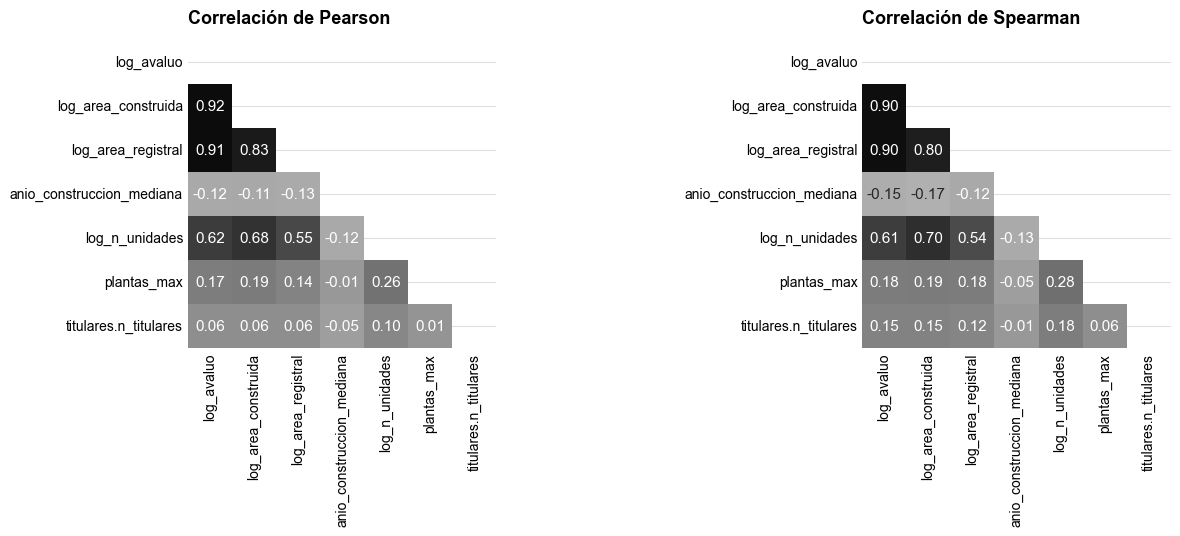

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (metodo, corr) in zip(axes, correlaciones.items()):
    sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), annot=True, fmt=".2f",
                cmap="Greys", vmin=-1, vmax=1, square=True, ax=ax, cbar=False)
    ax.set_title(f"Correlación de {metodo.capitalize()}")
plt.tight_layout(); plt.show()

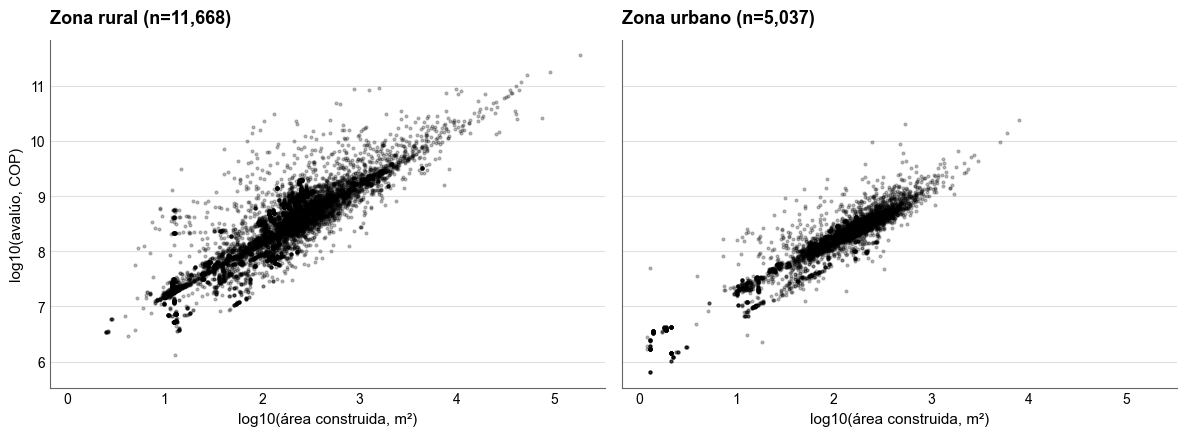

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True)
for ax, zona in zip(axes, ["Rural", "Urbano"]):
    d = base[base["zona_txt"] == zona]
    ax.scatter(d["log_area_construida"], d["log_avaluo"], s=4, alpha=0.25, color=NEGRO)
    ax.set_title(f"Zona {zona.lower()} (n={len(d):,})")
    ax.set_xlabel("log10(área construida, m²)")
axes[0].set_ylabel("log10(avalúo, COP)")
plt.tight_layout(); plt.show()

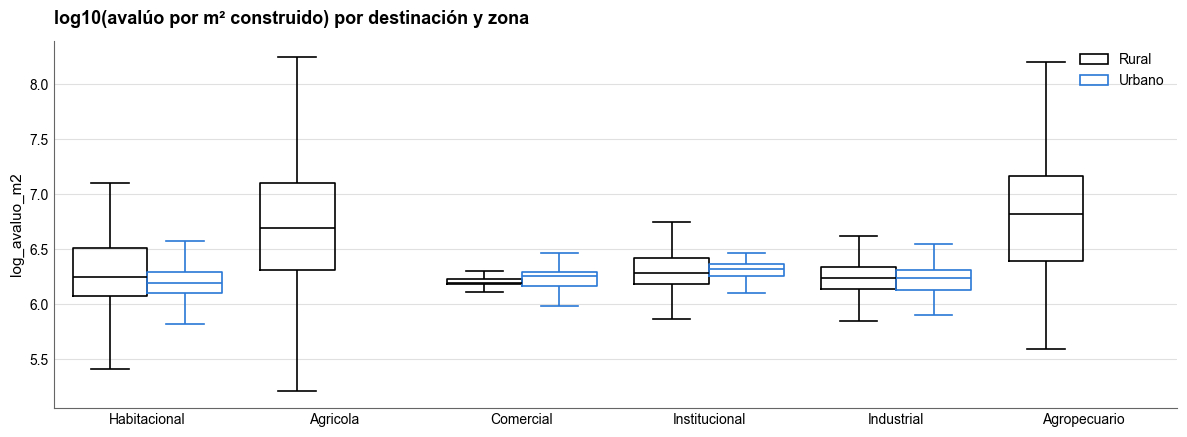

In [48]:
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.boxplot(data=sub, x="destinacion_economica", y="log_avaluo_m2", hue="zona_txt", hue_order=["Rural", "Urbano"],
            palette=[NEGRO, AZUL], fill=False, showfliers=False, linewidth=1.2, ax=ax)
ax.set_title("log10(avalúo por m² construido) por destinación y zona")
ax.set_xlabel(""); ax.legend(title="")
plt.tight_layout(); plt.show()

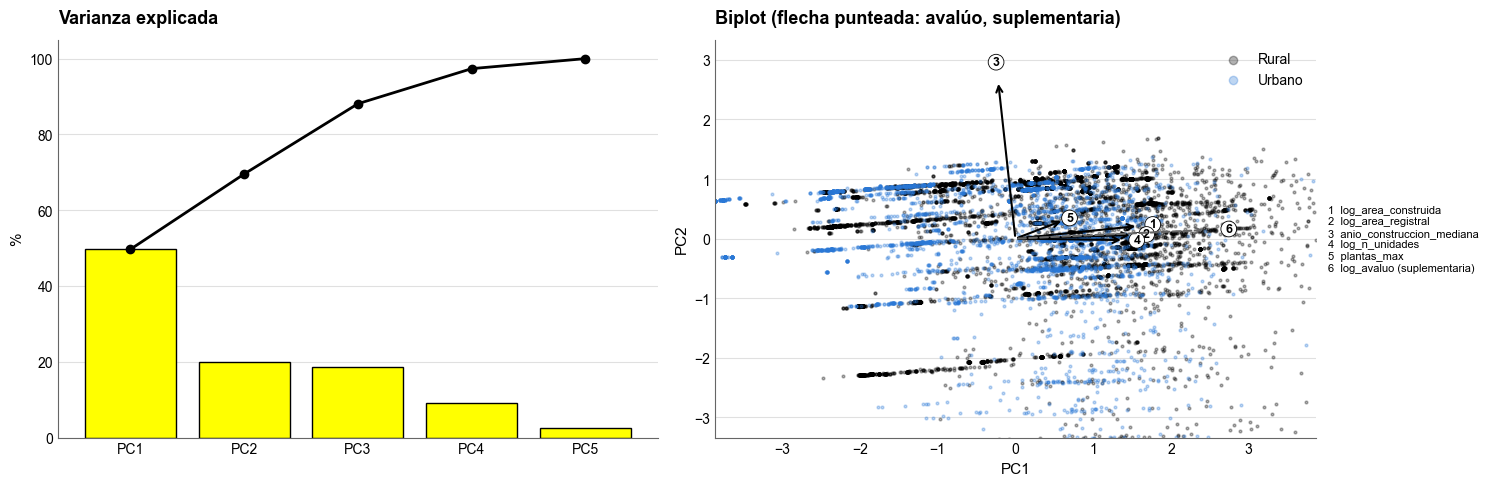

In [49]:
# Biplot del PCA (5.1): la zona y el avalúo no entran al PCA
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
ax1.bar(varianza.index, varianza["varianza explicada (%)"], color=AMARILLO, edgecolor=NEGRO)
ax1.plot(varianza.index, varianza["acumulada (%)"], color=NEGRO, marker="o")
ax1.set_title("Varianza explicada"); ax1.set_ylabel("%")
zona = base.loc[X.index, "zona_txt"]
for z, color in [("Rural", NEGRO), ("Urbano", AZUL)]:
    m = (zona == z).values
    ax2.scatter(comp[m, 0], comp[m, 1], s=4, alpha=0.3, color=color, label=z)
L = np.abs(np.percentile(comp[:, :2], [0.5, 99.5], axis=0)).max(axis=0)  # vista sin el 1 % más extremo
escala = 0.8 * L.min()
flechas = pd.concat([loadings[["PC1", "PC2"]],
                     pd.DataFrame([suplementaria[["PC1", "PC2"]].values], index=["log_avaluo (suplementaria)"],
                                  columns=["PC1", "PC2"])])
# Las flechas se numeran y la leyenda de números va aparte, para que las etiquetas no se monten
leyenda_flechas = []
for n, (var, (x, y)) in enumerate(flechas.iterrows(), start=1):
    estilo = {"color": GRIS, "linestyle": "--"} if "suplementaria" in var else {"color": NEGRO}
    ax2.annotate("", xy=(x * escala, y * escala), xytext=(0, 0), arrowprops={"arrowstyle": "->", "lw": 1.5, **estilo})
    ax2.text(x * escala * 1.12, y * escala * 1.12, str(n), fontsize=9, fontweight="bold", ha="center", va="center",
             bbox={"facecolor": "white", "edgecolor": NEGRO, "boxstyle": "circle,pad=0.15", "linewidth": 0.6})
    leyenda_flechas.append(f"{n}  {var}")
ax2.text(1.02, 0.5, "\n".join(leyenda_flechas), transform=ax2.transAxes, fontsize=8, va="center")
ax2.set_xlim(-L[0], L[0]); ax2.set_ylim(-L[1], L[1])
ax2.set_xlabel("PC1"); ax2.set_ylabel("PC2"); ax2.set_title("Biplot (flecha punteada: avalúo, suplementaria)")
ax2.legend(markerscale=3)
plt.tight_layout(); plt.show()

Las bandas horizontales del biplot vienen de variables discretas: el año de construcción y el número de plantas toman pocos valores, y cada valor forma una línea de puntos.

**t-SNE (complementario, desactivado por defecto).** Con estas variables no agrega información que no den el PCA y la regresión: los grupos compactos que forma parecen ser unidades casi idénticas de un mismo edificio en PH, y la destinación habitacional aparece en todas partes. Además es lento y, en Windows, una ejecución dentro de Jupyter llegó a quedarse colgada. Para verlo, cambiar `EJECUTAR_TSNE` a `True`. En t-SNE solo se interpretan los vecindarios: el tamaño de los grupos y la distancia entre ellos dependen de la *perplexity* y no tienen significado.

In [50]:
EJECUTAR_TSNE = False

if EJECUTAR_TSNE:
    muestra = X.sample(min(3000, len(X)), random_state=SEMILLA)
    emb = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEMILLA).fit_transform(
        StandardScaler().fit_transform(muestra))
    destino = base.loc[muestra.index, "destinacion_economica"]
    top = destino.value_counts().head(4).index
    fig, ax = plt.subplots(figsize=(8, 5.5))
    for d in top:
        m = (destino == d).values
        ax.scatter(emb[m, 0], emb[m, 1], s=6, alpha=0.5, label=d)
    m = (~destino.isin(top)).values
    ax.scatter(emb[m, 0], emb[m, 1], s=6, alpha=0.3, color=ue.GRIS_CLARO, label="Otras")
    ax.set_title("t-SNE (color: destinación, que no entra a la proyección)"); ax.legend(markerscale=3)
    plt.tight_layout(); plt.show()
else:
    print("t-SNE desactivado (EJECUTAR_TSNE = False).")

t-SNE desactivado (EJECUTAR_TSNE = False).


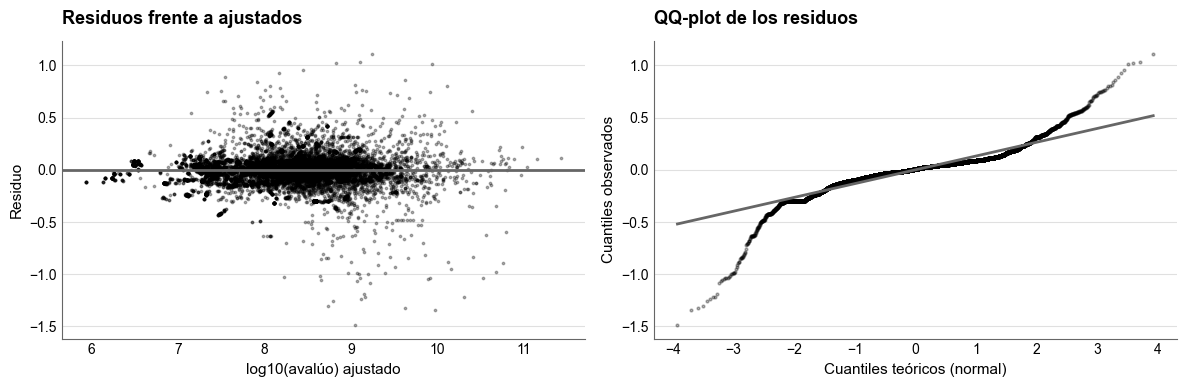

In [51]:
# Diagnóstico de la regresión (5.1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.scatter(modelo.fittedvalues, modelo.resid, s=3, alpha=0.3, color=NEGRO)
ax1.axhline(0, color=GRIS); ax1.set_xlabel("log10(avalúo) ajustado"); ax1.set_ylabel("Residuo")
ax1.set_title("Residuos frente a ajustados")
stats.probplot(modelo.resid, dist="norm", plot=ax2)
ax2.get_lines()[0].set(color=NEGRO, markersize=2, alpha=0.3); ax2.get_lines()[1].set(color=GRIS)
ax2.set_title("QQ-plot de los residuos"); ax2.set_xlabel("Cuantiles teóricos (normal)"); ax2.set_ylabel("Cuantiles observados")
plt.tight_layout(); plt.show()

**Interpretación.** Las gráficas muestran las mismas asociaciones. En log10, el avalúo, el área construida y el área registral se mueven juntos (correlaciones entre 0,82 y 0,92), y la dispersión entre avalúo y área tiene la misma forma casi lineal en las dos zonas. Las cajas por destinación muestran avalúos por m² parecidos entre destinaciones, con dos excepciones: agrícola y agropecuario, que tienen medianas más altas y mucha más dispersión por el peso del terreno. El diagnóstico de la regresión muestra residuos de colas pesadas y varianza no constante, lo que justifica los errores estándar robustos.

<a id="calidad"></a>

## 6. Calidad de los datos

El curso define nueve dimensiones de calidad: completitud, consistencia, conformidad, relevancia, precisión, procesabilidad, disponibilidad, temporalidad y credibilidad. Y clasifica los problemas según el nivel en el que aparecen:

| Nivel | Problemas |
| --- | --- |
| Atributo | Valor faltante, violación de sintaxis, error de digitación, violación de dominio |
| Registro | Violación de integridad: valores de un mismo registro que se contradicen |
| Columna | Sinónimos, homónimos, violación de singularidad |
| Tabla | Duplicados aproximados |
| Múltiples tablas | Representación heterogénea de los datos, sinónimos, granularidades distintas |

Aquí los problemas se diagnostican. La limpieza corresponde a la preparación de datos de la entrega final (actividad 8).

### 6.1 Valores faltantes y aberrantes

Paso 4 del proceso de exploración. El [diccionario de datos](../../datos/base-podada/diccionario-de-datos.md) ya trae, para cada columna, el porcentaje de filas que tienen dato; es el punto de partida para la completitud. Técnicas del tutorial 2 para lo demás:

- Diccionarios de valores válidos. Aquí ese papel lo cumplen las tablas de dominio.
- Expresiones regulares para comprobar formatos.
- Duplicados, por un conjunto de atributos o por el registro entero.
- Medidas de similitud entre textos (distancia de Levenshtein) para los errores de digitación.
- Consistencia entre columnas del mismo registro.

#### Completitud: nulos y valores que funcionan como nulos

In [52]:
ue.resumen_columnas(predios.drop(columns=COLUMNAS_RESERVADAS)).query("nulos > 0")

,tipo,nulos,% nulos,únicos
ph_matriz.numero_torres,float64,21382,96.23,8
ph_matriz.total_unidades_privadas,float64,21382,96.23,82
ph_matriz.area_total_terreno_privada,float64,21382,96.23,71
ph_matriz.area_total_terreno,float64,21382,96.23,690
ph_matriz.area_total_terreno_comun,float64,21382,96.23,686
ph_matriz.area_total_construida,float64,21382,96.23,764
ph_matriz.area_total_construida_privada,float64,21382,96.23,709
ph_matriz.area_total_construida_comun,float64,21382,96.23,161
titulares.tipo_agrupacion,object,16078,72.36,3
pisos_max,float64,15721,70.75,5


In [53]:
ceros = {
    "avalúo = 0": predios["avaluo_catastral"].eq(0),
    "área registral = 0": predios["area_registral_m2"].eq(0),
    "sin unidades de construcción": predios["n_unidades"].eq(0),
    "sin terreno": predios["terreno.area_terreno"].isna(),
}
display(pd.DataFrame({"predios": {k: int(m.sum()) for k, m in ceros.items()},
                      "%": {k: round(m.mean() * 100, 1) for k, m in ceros.items()}}))

# Composición de los predios sin terreno, para que la bitácora diga lo que muestran los datos
sin_terreno = predios.loc[ceros["sin terreno"], "condicion_predio"].value_counts()
texto_sin_terreno = ", ".join(f"{k} {v:,}" for k, v in sin_terreno.head(4).items())
print("Predios sin terreno, por régimen:", texto_sin_terreno)

bitacora.registrar("Avalúo igual a 0 (todo el levantamiento)", "predios.avaluo_catastral", "Completitud", "Atributo",
                   ceros["avalúo = 0"].sum(), "Se explica por régimen en 3.4; en los predios individuales se excluye del análisis del avalúo")
bitacora.registrar("Área registral igual a 0 (todo el levantamiento)", "predios.area_registral_m2", "Completitud",
                   "Atributo", ceros["área registral = 0"].sum(), "Se describe; en la base del avalúo se marca como faltante")
bitacora.registrar(f"Terreno sin información ({texto_sin_terreno})", "predios.terreno", "Completitud",
                   "Múltiples tablas", ceros["sin terreno"].sum(),
                   "Se conserva; el área de terreno no entra al análisis (se usa el área registral)")

,predios,%
avalúo = 0,2335,10.50
área registral = 0,1133,5.10
sin unidades de construcción,5388,24.20
sin terreno,13300,59.90


Predios sin terreno, por régimen: PH.Unidad_Predial 11,052, Parque_Cementerio.Unidad_Predial 1,284, NPH 495, Informal 409


#### Conformidad y precisión: valores fuera de rango o centinela

Los dos centinelas principales (la fecha de visita y el año 2000) se detectaron en 3.3. Aquí se revisan los demás.

**Planta de ubicación.** En el número predial, los pisos 99 a 81 indican sótanos, contados desde el nivel de la vía hacia abajo (99 es el primer sótano). Por eso `planta_ubicacion = 99` no es un faltante: se comprueba si coincide con el tipo de planta.

In [54]:
visita = predios["fecha_visita_valida"]
REGLAS = [
    # (problema, tabla y atributo, dimensión, nivel, máscara, estrategia)
    ("Fecha de inicio de tenencia en 1900-01-01 (fecha desconocida)", "predios.fecha_inicio_tenencia", "Precisión",
     "Columna", predios["fecha_inicio_tenencia"].eq(pd.Timestamp("1900-01-01")), "No se usa en el análisis; se reporta"),
    ("Fecha de inicio de tenencia posterior a la visita (con fecha válida)", "predios.fecha_inicio_tenencia",
     "Consistencia", "Registro", predios["fecha_inicio_tenencia"] > visita, "No se usa en el análisis; se reporta"),
    ("Fecha de inicio de tenencia en el futuro", "predios.fecha_inicio_tenencia", "Conformidad", "Atributo",
     predios["fecha_inicio_tenencia"] > pd.Timestamp.today(), "No se usa en el análisis; se reporta"),
    ("Fecha del documento de la fuente en 1900-01-01", "predios.fecha_documento_fuente", "Precisión", "Columna",
     predios["fecha_documento_fuente"].eq(pd.Timestamp("1900-01-01")), "No se usa en el análisis; se reporta"),
    ("Año de construcción posterior a la visita", "unidades.anio_construccion", "Consistencia", "Múltiples tablas",
     predios["anio_construccion_min"] > visita.dt.year, "Ninguno"),
    ("Coeficiente de copropiedad fuera de [0, 1]", "predios.coeficiente_copropiedad", "Conformidad", "Atributo",
     ~predios["coeficiente_copropiedad"].dropna().between(0, 1).reindex(predios.index, fill_value=True), "Ninguno"),
]
for problema, atributo, dimension, nivel, mascara, estrategia in REGLAS:
    if mascara.sum():
        bitacora.registrar(problema, atributo, dimension, nivel, mascara.sum(), estrategia)
pd.Series({r[0]: int(r[4].sum()) for r in REGLAS}, name="predios").to_frame()

,predios
Fecha de inicio de tenencia en 1900-01-01 (fecha desconocida),751
Fecha de inicio de tenencia posterior a la visita (con fecha válida),57
Fecha de inicio de tenencia en el futuro,2
Fecha del documento de la fuente en 1900-01-01,754
Año de construcción posterior a la visita,0
"Coeficiente de copropiedad fuera de [0, 1]",0


In [55]:
# Planta de ubicación frente al tipo de planta
codigo_sotano = unidades["planta_ubicacion"].between(81, 99)
es_bajo_nivel = unidades["tipo_planta"].isin(["Sotano", "Semisotano"])
display(pd.crosstab(codigo_sotano.map({True: "planta 81-99", False: "planta 1-80"}), unidades["tipo_planta"]))
sotano_sin_codigo = es_bajo_nivel & ~codigo_sotano
bitacora.registrar("Sótanos y semisótanos con planta_ubicacion fuera de 81-99 (conviven dos convenciones)",
                   "unidades.planta_ubicacion", "Consistencia", "Registro", sotano_sin_codigo.sum(),
                   "Se reporta; planta_ubicacion no se usa en el análisis")
print(f"Sótanos o semisótanos con planta 1-80: {sotano_sin_codigo.sum():,} de {es_bajo_nivel.sum():,}")

tipo_planta,Mezanine,Piso,Semisotano,Sotano
planta_ubicacion,,,,
planta 1-80,1454,39866,96,1377
planta 81-99,0,2,170,23


Sótanos o semisótanos con planta 1-80: 1,473 de 1,666


#### Conformidad: formatos, dominios y errores de digitación

Las técnicas del tutorial 2: expresiones regulares para los formatos, diccionarios de valores válidos (aquí, los dominios del modelo LADM-COL según el [diccionario de datos](../../datos/base-podada/diccionario-de-datos.md)) y la distancia de Levenshtein para buscar categorías que difieren por un error de digitación. Las columnas reservadas solo se cuentan, sin mostrar valores.

In [56]:
from Levenshtein import distance as levenshtein

# Formatos con expresiones regulares
FORMATOS = {"numero_predial": r"\d{30}", "zona": r"\d{2}", "sector": r"\d{2}", "comuna": r"\d{2}", "barrio": r"\d{2}",
            "manzana_vereda": r"\d{4}", "numero_terreno": r"\d{4}", "condicion_propiedad": r"\d",
            "edificio": r"\d{2}", "piso": r"\d{2}", "unidad": r"\d{4}"}
fuera_de_formato = {c: int((~predios[c].astype(str).str.fullmatch(p)).sum()) for c, p in FORMATOS.items()}

# Cada segmento coincide con su posición dentro del número predial (posiciones del IGAC)
POSICIONES = {"zona": (5, 7), "sector": (7, 9), "comuna": (9, 11), "barrio": (11, 13), "manzana_vereda": (13, 17),
              "numero_terreno": (17, 21), "condicion_propiedad": (21, 22), "edificio": (22, 24), "piso": (24, 26),
              "unidad": (26, 30)}
segmento_distinto = {c: int((predios["numero_predial"].str[i:j] != predios[c]).sum()) for c, (i, j) in POSICIONES.items()}
display(pd.DataFrame({"fuera de formato": fuera_de_formato, "distinto de su segmento del número predial": segmento_distinto}))

,fuera de formato,distinto de su segmento del número predial
numero_predial,0,NaN
zona,0,0.00
sector,0,0.00
comuna,0,0.00
barrio,0,0.00
manzana_vereda,0,0.00
numero_terreno,0,0.00
condicion_propiedad,0,0.00
edificio,0,0.00
piso,0,0.00


In [57]:
# Diccionarios de valores válidos: los dominios del modelo
DOMINIOS = {
    ("predios", "resultado_visita"): {"Exitoso", "Incompleto", "Menor_Edad", "No_Hay_Nadie", "No_Permitieron_Acceso",
                                      "Sin_Visita", "Situacion_Orden_Publico", "Zona_Dificil_Acceso"},
    ("predios", "tipo_derecho"): {"Dominio", "Ocupacion", "Posesion"},
    ("predios", "condicion_predio"): {"Bien_Uso_Publico", "Condominio.Matriz", "Condominio.Unidad_Predial", "Informal",
                                      "NPH", "PH.Matriz", "PH.Unidad_Predial", "Parque_Cementerio.Matriz",
                                      "Parque_Cementerio.Unidad_Predial", "Via"},
    ("predios", "tipo_fuente"): {"Documento_Privado", "Documento_Publico.Acto_Administrativo",
                                 "Documento_Publico.Escritura_Publica", "Documento_Publico.Sentencia_Judicial", "Sin_Documento"},
    ("predios", "tipo_novedad_numero_predial"): {"Cambio_Numero_Predial", "Cancelacion", "Desenglobe", "Englobe", "Predio_Nuevo"},
    ("unidades", "tipo_planta"): {"Mezanine", "Piso", "Semisotano", "Sotano", "Subterraneo"},
    ("unidades", "tipo_unidad_construccion"): {"Anexo", "Comercial", "Industrial", "Institucional", "Residencial"},
}
violaciones = {f"{t}.{c}": int((~TABLAS[t][c].dropna().isin(validos)).sum()) for (t, c), validos in DOMINIOS.items()}
grupo_uso = unidades["uso"].str.split(".").str[0]
violaciones["unidades.uso (grupo válido)"] = int((~grupo_uso.isin(DOMINIOS[("unidades", "tipo_unidad_construccion")])).sum())
uso_distinto_tipo = grupo_uso != unidades["tipo_unidad_construccion"]
display(pd.Series(violaciones, name="valores fuera del dominio").to_frame())
print(f"Unidades cuyo grupo de uso no coincide con su tipo de unidad: {uso_distinto_tipo.sum():,} ({uso_distinto_tipo.mean():.1%})")
if uso_distinto_tipo.sum():
    bitacora.registrar("Grupo del uso distinto del tipo de unidad de construcción", "unidades.uso y tipo_unidad_construccion",
                       "Consistencia", "Registro", uso_distinto_tipo.sum(), "Se reporta; el análisis usa el tipo de unidad")

# Errores de digitación: pares de categorías de un mismo atributo a distancia de Levenshtein 2 o menos
pares = []
for t, c in [("predios", "destinacion_economica"), ("predios", "resultado_visita"), ("predios", "tipo_fuente"),
             ("unidades", "uso"), ("unidades", "tipo_planta")]:
    valores = sorted(TABLAS[t][c].dropna().unique())
    pares += [(f"{t}.{c}", a, b, levenshtein(a, b)) for i, a in enumerate(valores) for b in valores[i + 1:]
              if levenshtein(a, b) <= 2]
print("Pares de categorías casi iguales:", pares if pares else "ninguno")
for atributo, n in violaciones.items():
    if n:
        bitacora.registrar(f"Valores fuera del dominio en {atributo}", atributo, "Conformidad", "Atributo", n, "Se revisan")

,valores fuera del dominio
predios.resultado_visita,0
predios.tipo_derecho,0
predios.condicion_predio,0
predios.tipo_fuente,0
predios.tipo_novedad_numero_predial,0
unidades.tipo_planta,0
unidades.tipo_unidad_construccion,0
unidades.uso (grupo válido),0


Unidades cuyo grupo de uso no coincide con su tipo de unidad: 272 (0.6%)
Pares de categorías casi iguales: ninguno


#### Consistencia entre columnas y entre tablas

In [58]:
# Código de la posición 22 que corresponde a cada régimen en LADM-COL
CODIGO_ESPERADO = {"NPH": {"0"}, "Informal": {"2", "5"}, "Bien_Uso_Publico": {"3"}, "Via": {"4"},
                   "Parque_Cementerio": {"7"}, "Condominio": {"8"}, "PH": {"9"}}
esperado = predios["condicion_predio"].str.split(".").str[0].map(CODIGO_ESPERADO)
codigo_incoherente = pd.Series([c not in e for c, e in zip(predios["condicion_propiedad"], esperado)], index=predios.index)

CONSISTENCIA = [
    ("Matrices cuyos coeficientes de copropiedad no suman 1 (±1 %)", "predios.coeficiente_copropiedad", "Múltiples tablas",
     int((por_matriz["suma_coeficientes"] - 1).abs().gt(0.01).sum())),
    ("Área construida y área de la geometría difieren más de 10 %", "unidades.area_construida", "Registro",
     int(predios["dif_area_geometrica_pct"].gt(10).sum())),
    ("Código de la posición 22 distinto de la condición LADM-COL", "predios.condicion_propiedad", "Registro",
     int(codigo_incoherente.sum())),
    ("Destinación habitacional sin unidades de construcción", "predios.destinacion_economica", "Múltiples tablas",
     int((predios["destinacion_economica"].eq("Habitacional") & predios["n_unidades"].eq(0)).sum())),
]
for problema, atributo, nivel, n in CONSISTENCIA:
    if n:
        bitacora.registrar(problema, atributo, "Consistencia", nivel, n, "Se reporta; pendiente de revisar con el gestor catastral")
display(pd.Series({c[0]: c[3] for c in CONSISTENCIA}, name="predios").to_frame())
pd.crosstab(predios["condicion_propiedad_txt"], predios["condicion_predio"])

,predios
Matrices cuyos coeficientes de copropiedad no suman 1 (±1 %),2
Área construida y área de la geometría difieren más de 10 %,131
Código de la posición 22 distinto de la condición LADM-COL,4
Destinación habitacional sin unidades de construcción,1871


condicion_predio,Bien_Uso_Publico,Condominio.Matriz,Condominio.Unidad_Predial,Informal,NPH,PH.Matriz,PH.Unidad_Predial,Parque_Cementerio.Matriz,Parque_Cementerio.Unidad_Predial,Via
condicion_propiedad_txt,,,,,,,,,,
Bien de uso público distinto de vías,124,0,0,0,0,0,0,0,0,0
Condominio,0,91,2351,0,0,0,0,0,0,0
"Informal (ocupación, posesión)",0,0,0,182,0,0,0,0,0,0
Mejora en terreno ajeno sin PH,0,0,0,407,0,0,0,0,0,0
No reglamentado en PH,0,0,0,2,5903,0,1,0,0,1
Parque cementerio,0,0,0,0,0,0,0,1,1284,0
Propiedad horizontal,0,0,0,0,0,763,11051,0,0,0
Vía,0,0,0,0,0,0,0,0,0,59


**Área registral frente a área levantada.** El diccionario distingue dos fuentes para el área: el **área registral** sale de los títulos o del certificado de tradición y libertad, y el **área de terreno** sale de la medición del levantamiento. Una diferencia grande es un hallazgo catastral en sí mismo, porque señala predios cuya área jurídica no coincide con la física. Solo se comparan los predios que tienen las dos.

**La diferencia depende del régimen.** En NPH las dos áreas coinciden en mediana. En condominio el área levantada es sistemáticamente menor que la registral, por una causa que está por confirmar con el gestor catastral. Por eso la diferencia se mide por régimen, y la bitácora registra aparte la de condominio, como una diferencia sistemática y no como errores aislados.

In [59]:
con_ambas = predios["terreno.area_terreno"].notna() & predios["area_registral_m2"].gt(0)
areas = predios.loc[con_ambas, ["id_predio", "condicion_predio", "zona_txt", "area_registral_m2", "terreno.area_terreno"]].copy()
areas["razon_levantada_registral"] = areas["terreno.area_terreno"] / areas["area_registral_m2"]
areas["dif_abs_pct"] = (areas["razon_levantada_registral"] - 1).abs() * 100
areas["rango"] = pd.cut(areas["dif_abs_pct"], [-0.01, 5, 10, 50, np.inf], labels=["hasta 5 %", "5-10 %", "10-50 %", "más de 50 %"])
condominio = areas["condicion_predio"].str.startswith("Condominio")
print(f"Predios con área registral y área levantada: {len(areas):,} de {len(predios):,} ({condominio.sum():,} en condominio)")

# Razón levantada / registral por régimen: en NPH ronda 1; en condominio es sistemáticamente menor
display(areas.groupby("condicion_predio")["razon_levantada_registral"]
        .describe(percentiles=[0.25, 0.5, 0.75])[["count", "25%", "50%", "75%"]].round(2))
display(areas.groupby(condominio.map({True: "condominio", False: "demás regímenes"}))["rango"]
        .value_counts(normalize=True).unstack().mul(100).round(1))

bitacora.registrar("Área levantada y área registral difieren más de 50 % (sin condominios)",
                   "predios.area_registral_m2 y terreno.area_terreno", "Consistencia", "Múltiples tablas",
                   areas.loc[~condominio, "dif_abs_pct"].gt(50).sum(),
                   "Se reporta; posible diferencia entre el título y la realidad física")
bitacora.registrar("Área levantada menor que la registral en condominio (diferencia sistemática)",
                   "predios.area_registral_m2 y terreno.area_terreno", "Consistencia", "Múltiples tablas",
                   areas.loc[condominio, "razon_levantada_registral"].lt(0.95).sum(),
                   "Se reporta como diferencia sistemática del régimen; causa por confirmar con el gestor catastral")
areas.loc[~condominio].groupby("zona_txt")["dif_abs_pct"].agg(
    n="size", mediana_dif_pct="median", pct_mas_50=lambda s: (s > 50).mean() * 100).round(1)

Predios con área registral y área levantada: 8,241 de 22,220 (2,384 en condominio)


,count,25%,50%,75%
condicion_predio,,,,
Bien_Uso_Publico,123.00,0.91,1.00,1.06
Condominio.Matriz,87.00,0.12,0.32,0.95
Condominio.Unidad_Predial,2297.00,0.50,0.79,1.00
NPH,4914.00,0.96,1.00,1.05
PH.Matriz,761.00,0.98,1.01,1.05
Parque_Cementerio.Matriz,1.00,0.90,0.90,0.90
Via,58.00,0.94,1.00,1.05


rango,hasta 5 %,5-10 %,10-50 %,más de 50 %
condicion_predio,,,,
condominio,32.60,5.20,34.10,28.00
demás regímenes,52.90,21.60,20.80,4.60


,n,mediana_dif_pct,pct_mas_50
zona_txt,,,
Rural,3445,4.90,5.80
Urbano,2412,4.10,3.00


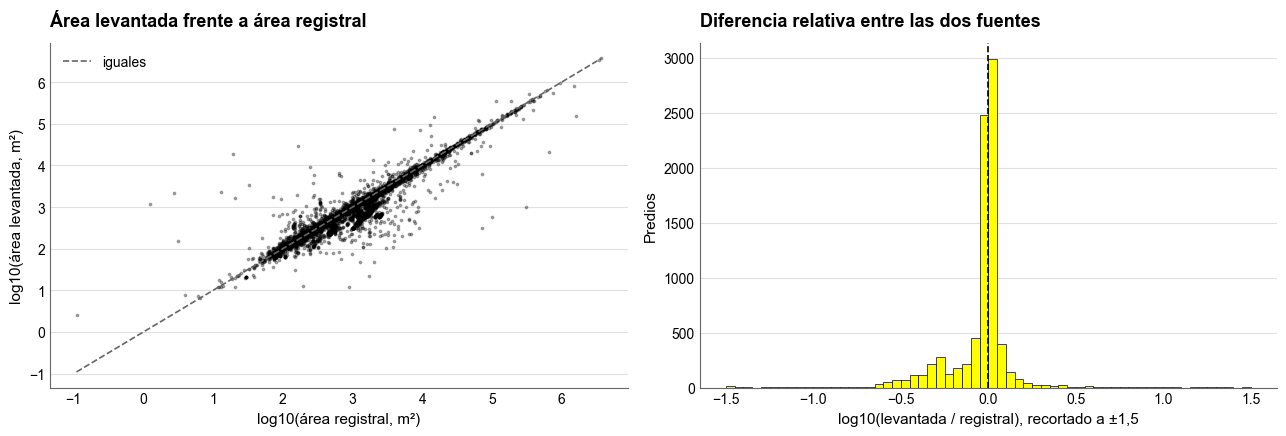

In [60]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.scatter(np.log10(areas["area_registral_m2"]), np.log10(areas["terreno.area_terreno"]), s=3, alpha=0.3, color=NEGRO)
lim = np.log10(areas[["area_registral_m2", "terreno.area_terreno"]]).agg(["min", "max"]).values
ax1.plot([lim.min(), lim.max()], [lim.min(), lim.max()], color=GRIS, linestyle="--", linewidth=1.2, label="iguales")
ax1.set_xlabel("log10(área registral, m²)"); ax1.set_ylabel("log10(área levantada, m²)")
ax1.set_title("Área levantada frente a área registral"); ax1.legend()
ax2.hist(np.log10(areas["razon_levantada_registral"]).clip(-1.5, 1.5), bins=60, color=AMARILLO, edgecolor=NEGRO, linewidth=0.5)
ax2.axvline(0, color=NEGRO, linestyle="--", linewidth=1.2)
ax2.set_xlabel("log10(levantada / registral), recortado a ±1,5"); ax2.set_ylabel("Predios")
ax2.set_title("Diferencia relativa entre las dos fuentes")
plt.tight_layout(); plt.show()

#### Unicidad y relevancia

In [61]:
# Identificadores: solo se cuentan los repetidos, sin mostrar valores
repetidos = {c: int(predios[c].duplicated().sum()) for c in ["id_predio", "numero_predial", "codigo_homologado", "id_operacion"]}
print("Valores repetidos en identificadores que deberían ser únicos:", repetidos)
for col, n in repetidos.items():
    if n:
        bitacora.registrar(f"{col} repetido", f"predios.{col}", "Consistencia", "Columna", n,
                           "Se reporta al gestor catastral; el análisis usa id_predio")

# Duplicados: se comparan todas las columnas simples, también las reservadas (no se muestran sus valores)
columnas_simples = [c for c in predios.columns
                    if not predios[c].map(lambda v: isinstance(v, (list, np.ndarray))).any()]
duplicados = predios[columnas_simples].drop(columns="id_predio").astype(str).duplicated().sum()
columnas_simples = [c for c in columnas_simples if c not in COLUMNAS_RESERVADAS]
print(f"Predios con todo el contenido repetido (sin contar el id): {duplicados}")
constantes = [c for c in columnas_simples if predios[c].astype(str).nunique(dropna=False) <= 1]
print("Columnas constantes:", constantes)
bitacora.registrar("Columnas constantes: " + ", ".join(constantes), "predios", "Relevancia", "Columna", len(constantes),
                   "No se usan en el análisis")

Valores repetidos en identificadores que deberían ser únicos: {'id_predio': 0, 'numero_predial': 0, 'codigo_homologado': 1, 'id_operacion': 0}


Predios con todo el contenido repetido (sin contar el id): 0


Columnas constantes: ['sector', 'comuna', 'barrio', 'tipo_direccion', 'es_direccion_principal', 'estado_disponibilidad']


#### ¿Los faltantes y los centinelas son aleatorios?

Si se concentran en un tipo de predio o en las visitas que no fueron exitosas, excluirlos sesga el análisis. Para cada indicador, el porcentaje de predios individuales afectados según la visita efectiva (propia o de la matriz, ver 3.3), y la asociación (chi-cuadrado y V de Cramér) con que esa visita haya sido exitosa.

**Cuidado con el régimen.** El régimen se asocia a la vez con los faltantes (una unidad de PH no tiene terreno propio) y con el resultado de la visita (las visitas exitosas son muy distintas entre regímenes), así que la primera tabla mezcla los dos efectos. La segunda repite la comparación dentro de cada régimen; la V de Cramér se calcula solo donde hay al menos 30 visitas exitosas y 30 no exitosas.

In [62]:
INDICADORES = {
    "avalúo = 0": individuales["avaluo_catastral"].eq(0),
    "área registral = 0": individuales["area_registral_m2"].eq(0),
    "sin terreno": individuales["terreno.area_terreno"].isna(),
    "sin unidades de construcción": individuales["n_unidades"].eq(0),
    "año de construcción 2000": individuales["anio_sospechoso"].eq(1),
    "fecha de visita centinela": individuales["fecha_visita_valida"].isna(),
}
visita_exitosa = individuales["visita_exitosa_efectiva"].map({True: "visita exitosa", False: "visita no exitosa"})
filas = []
for nombre, ind in INDICADORES.items():
    tabla = pd.crosstab(ind, visita_exitosa)
    filas.append({"indicador": nombre, "% total": ind.mean() * 100,
                  **ind.groupby(visita_exitosa).mean().mul(100).add_prefix("% con ").to_dict(),
                  "p chi-cuadrado": stats.chi2_contingency(tabla)[1], "V de Cramér": ue.cramers_v(tabla)})
display(pd.DataFrame(filas).set_index("indicador").round(3))

porcentajes = pd.DataFrame(INDICADORES).astype(int).mul(100)
display(porcentajes.groupby(individuales["condicion_predio"]).mean().round(1)
        .assign(n=individuales["condicion_predio"].value_counts()))
porcentajes.groupby(individuales["zona_txt"]).mean().round(1)

,% total,% con visita exitosa,% con visita no exitosa,p chi-cuadrado,V de Cramér
indicador,,,,,
avalúo = 0,5.25,0.08,10.12,0.00,0.23
área registral = 0,5.67,1.42,9.68,0.00,0.18
sin terreno,60.36,69.31,51.94,0.00,0.18
sin unidades de construcción,16.04,7.42,24.16,0.00,0.23
año de construcción 2000,16.59,9.54,23.22,0.00,0.18
fecha de visita centinela,45.27,60.57,30.86,0.00,0.30


,avalúo = 0,área registral = 0,sin terreno,sin unidades de construcción,año de construcción 2000,fecha de visita centinela,n
condicion_predio,,,,,,,
Condominio.Unidad_Predial,2.50,0.00,2.30,27.70,3.10,2.40,2351
Informal,73.30,99.20,69.20,73.30,11.00,68.20,591
NPH,8.40,9.20,8.40,34.70,29.00,8.40,5903
PH.Unidad_Predial,0.50,0.00,100.00,0.50,13.10,72.80,11052


,avalúo = 0,área registral = 0,sin terreno,sin unidades de construcción,año de construcción 2000,fecha de visita centinela
zona_txt,,,,,,
Rural,5.70,5.90,62.40,15.10,15.80,47.40
Urbano,4.30,5.10,55.80,18.10,18.20,40.50


In [63]:
# Lo mismo dentro de cada régimen
filas = []
for regimen, d in individuales.groupby("condicion_predio"):
    exitosa = d["visita_exitosa_efectiva"]
    for nombre, ind in INDICADORES.items():
        ind_r = ind.loc[d.index]
        fila = {"régimen": regimen, "indicador": nombre, "n": len(d), "% visitas exitosas": exitosa.mean() * 100,
                "% con visita exitosa": ind_r[exitosa].mean() * 100 if exitosa.any() else np.nan,
                "% con visita no exitosa": ind_r[~exitosa].mean() * 100, "V de Cramér": np.nan}
        if exitosa.sum() >= 30 and (~exitosa).sum() >= 30 and ind_r.nunique() > 1:
            fila["V de Cramér"] = ue.cramers_v(pd.crosstab(ind_r, exitosa))
        filas.append(fila)
pd.DataFrame(filas).set_index(["régimen", "indicador"]).round(2)

n  \
régimen                   indicador                             
Condominio.Unidad_Predial avalúo = 0                     2351   
                          área registral = 0             2351   
                          sin terreno                    2351   
                          sin unidades de construcción   2351   
                          año de construcción 2000       2351   
                          fecha de visita centinela      2351   
Informal                  avalúo = 0                      591   
                          área registral = 0              591   
                          sin terreno                     591   
                          sin unidades de construcción    591   
                          año de construcción 2000        591   
                          fecha de visita centinela       591   
NPH                       avalúo = 0                     5903   
                          área registral = 0             5903   
                          sin terreno                    5903   
                          sin unidades de construcción   5903   
                          año de construcción 2000       5903   
                          fecha de visita centinela      5903   
PH.Unidad_Predial         avalúo = 0                    11052   
                          área registral = 0            11052   
                          sin terreno                   11052   
                          sin unidades de construcción  11052   
                          año de construcción 2000      11052   
                          fecha de visita centinela     11052   

                                                        % visitas exitosas  \
régimen                   indicador                                          
Condominio.Unidad_Predial avalúo = 0                                 77.54   
                          área registral = 0                         77.54   
                          sin terreno                                77.54   
                          sin unidades de construcción               77.54   
                          año de construcción 2000                   77.54   
                          fecha de visita centinela                  77.54   
Informal                  avalúo = 0                                  8.63   
                          área registral = 0                          8.63   
                          sin terreno                                 8.63   
                          sin unidades de construcción                8.63   
                          año de construcción 2000                    8.63   
                          fecha de visita centinela                   8.63   
NPH                       avalúo = 0                                 18.43   
                          área registral = 0                         18.43   
                          sin terreno                                18.43   
                          sin unidades de construcción               18.43   
                          año de construcción 2000                   18.43   
                          fecha de visita centinela                  18.43   
PH.Unidad_Predial         avalúo = 0                                 60.51   
                          área registral = 0                         60.51   
                          sin terreno                                60.51   
                          sin unidades de construcción               60.51   
                          año de construcción 2000                   60.51   
                          fecha de visita centinela                  60.51   

                                                        % con visita exitosa  \
régimen                   indicador                                            
Condominio.Unidad_Predial avalúo = 0                                    0.27   
                          área registral = 0                            0.00   
                    

**Interpretación.** La mayoría de los faltantes se explican por el tipo de predio. Las unidades de PH no tienen terreno propio, los informales casi nunca tienen área registral (no tienen título) y las unidades de parque cementerio tienen avalúo 0. Son casos válidos del modelo LADM-COL.

Los errores están en valores de relleno: la fecha de visita repetida (40,5 % de los predios), el año 2000 (3 322), las fechas de 1900-01-01 en la tenencia y en los documentos (751 y 754), y el 99 en plantas y pisos. A esto se suman 57 fechas de tenencia posteriores a la visita y 2 en el futuro.

La conformidad es buena: los formatos del número predial, los dominios y las categorías no tienen errores. Las inconsistencias son pocas y puntuales: 4 códigos de condición, 2 matrices cuyos coeficientes no suman 1 y 131 predios con áreas construidas que no coinciden con su geometría. Dos merecen revisión con el gestor catastral: 1 871 predios habitacionales sin unidades de construcción, y los sótanos, que en su mayoría no usan la convención 81 a 99 del número predial.

El área registral y la levantada coinciden en la mayoría de los predios: fuera de los condominios, solo el 4,6 % difiere más de 50 %. En condominio la diferencia es sistemática (28 %), y su causa está por confirmar.

Dentro de cada régimen, los faltantes y los valores de relleno se concentran en los predios sin visita exitosa. Es más fuerte en los informales (V = 0,46) y en los condominios (V entre 0,26 y 0,30), y más débil en NPH (V entre 0,12 y 0,18). Por eso, excluir los predios con datos faltantes deja una base con más predios visitados, formales y construidos.

### 6.2 Valores atípicos

Paso 5 del proceso de exploración. Las dos definiciones estándar del curso: valores a más de 3 desviaciones estándar de la media, o a más de 1,5 veces el rango intercuartílico por debajo del primer cuartil o por encima del tercero. Qué cuenta como atípico depende muchas veces del negocio.

In [64]:
# Sin id_predio y con las áreas redondeadas a la decena, para que las tablas no ubiquen un predio concreto
CONTEXTO = ["condicion_predio", "destinacion_economica", "zona_txt", "area_construida_total", "area_registral_m2"]
base_vista = base.assign(area_construida_total=base["area_construida_total"].round(-1),
                         area_registral_m2=base["area_registral_m2"].round(-1))
_ = ue.inspeccionar_outliers(base_vista, "log_avaluo", None, k=3, extra_cols=CONTEXTO)

=== Atípicos de log_avaluo (k=3) ===
Rango observado: [5.81, 11.55] | cercos: [4.93, 11.63]
Por debajo: 0 | por encima: 0


In [65]:
# El avalúo por m² tiene muchos valores fuera de los cercos de Tukey con k=1,5: se revisan los extremos con k=3
_ = ue.inspeccionar_outliers(base_vista, "log_avaluo_m2", None, k=3, extra_cols=CONTEXTO)

=== Atípicos de log_avaluo_m2 (k=3) ===
Rango observado: [5.02, 8.37] | cercos: [5.49, 6.98]
Por debajo: 112 | por encima: 287

--- 8 valores más bajos


,log_avaluo_m2,condicion_predio,destinacion_economica,zona_txt,area_construida_total,area_registral_m2
939,5.02,Informal,Habitacional,Rural,10.00,0.00
953,5.09,Informal,Lote_Urbanizado_No_Construido,Urbano,20.00,0.00
9914,5.15,Informal,Habitacional,Urbano,130.00,0.00
9929,5.16,Informal,Lote_Urbanizado_No_Construido,Urbano,330.00,0.00
1057,5.17,Informal,Habitacional,Rural,210.00,0.00
8566,5.21,NPH,Agricola,Rural,780.00,3360.00
1977,5.26,Informal,Habitacional,Rural,1180.00,0.00
7854,5.26,Condominio.Unidad_Predial,Habitacional,Rural,410.00,1310.00



--- 8 valores más altos


,log_avaluo_m2,condicion_predio,destinacion_economica,zona_txt,area_construida_total,area_registral_m2
5315,8.15,NPH,Agricola,Rural,70.00,165710.00
1026,8.21,NPH,Agropecuario,Rural,100.00,63680.00
3696,8.24,NPH,Agricola,Rural,80.00,41400.00
1653,8.25,NPH,Agricola,Rural,40.00,24820.00
7172,8.32,NPH,Agricola,Rural,10.00,0.00
9139,8.34,NPH,Habitacional,Rural,100.00,56440.00
1224,8.35,NPH,Agricola,Rural,80.00,62060.00
4548,8.37,NPH,Agricola,Rural,130.00,92160.00


**Interpretación.** El avalúo no tiene atípicos extremos: en log10, todos los predios quedan dentro de los cercos de Tukey con k = 3. El avalúo por m² construido sí los tiene: 399 predios, el 2,4 % de la base.

- Los más bajos son casi todos informales sin área registral: predios con construcción y un avalúo muy bajo, posiblemente construcciones precarias o mejoras.
- Los más altos son predios rurales agrícolas o agropecuarios, con lotes de varias hectáreas y poca construcción. Como el avalúo incluye el terreno, al dividirlo entre pocos m² construidos el valor por m² se dispara.

Son predios reales, así que se conservan. Para comparar el valor de lotes rurales grandes, el área construida no sirve como denominador; ahí conviene usar el área registral o la de terreno.

### 6.3 Resumen de problemas de calidad

Como pide la conclusión del tutorial 2: cada problema encontrado, la dimensión de calidad que afecta, el nivel en que aparece y la estrategia para resolverlo o mitigarlo. La tabla sale de la bitácora que se llenó a lo largo del notebook, así que sus conteos son los que calculó el código. Las filas con "filas antes" y "filas después" son las exclusiones que dan lugar a la base del avalúo (3.4).

In [66]:
with pd.option_context("display.max_colwidth", 120):
    display(bitacora.tabla())

,problema,tabla y atributo,dimensión,nivel,filas afectadas,estrategia,filas antes,filas después
#,,,,,,,,
1,total_plantas = 99,unidades.total_plantas,Precisión,Atributo,4,Se marca como faltante,NaN,NaN
2,total_pisos = 99 (con altura de 297 m),construcciones.total_pisos y altura_total_construccion,Precisión,Atributo,1,Se marca como faltante,NaN,NaN
3,"Fecha de visita 2025-07-18 repetida en bloque, todas con visita incompleta",predios.fecha_visita_predial,Precisión,Columna,9010,"Se marca como faltante (fecha_visita_valida); se concentra en unidades de PH, cuya visita parece registrarse en el p...",NaN,NaN
4,Año de construcción 2000 muy por encima de los años vecinos,unidades.anio_construccion,Precisión,Columna,3322,Se marca con anio_sospechoso; el PCA lo excluye y la regresión se estima con y sin él,NaN,NaN
5,"Matrices, vías, bienes de uso público y parque cementerio",predios.condicion_predio,Relevancia,Múltiples tablas,2323,Se excluyen del análisis del avalúo: no es comparable con el de un predio individual,22220.00,19897.00
6,Avalúo igual a 0 en los predios individuales,predios.avaluo_catastral,Completitud,Atributo,1045,Se excluyen del análisis del avalúo,19897.00,18852.00
7,Predio sin área construida,unidades.area_construida,Completitud,Múltiples tablas,2147,Se excluyen del análisis por m² construido,18852.00,16705.00
8,Área registral igual a 0 en la base del avalúo,predios.area_registral_m2,Completitud,Atributo,459,Se marca como faltante: quedan fuera del PCA y de la regresión,NaN,NaN
9,Área construida más de 20 veces el área registral,predios.area_registral_m2 y unidades.area_construida,Consistencia,Múltiples tablas,41,Se marca el área registral como faltante: quedan fuera del PCA y de la regresión,NaN,NaN


**Interpretación.** La bitácora registra 26 problemas. Los datos tienen buena conformidad y pocas inconsistencias puntuales. Los problemas principales son tres:

- valores de relleno que afectan a muchos predios: la fecha de visita en el 40,5 % y el año de construcción en 3 322;
- faltantes que dependen del régimen y de la visita: avalúo 0, terreno y área registral;
- una diferencia sistemática entre el área registral y la levantada en condominio.

Ninguno impide el análisis: los valores de relleno se marcan como faltantes, y las exclusiones dejan una base de 16 705 predios comparables.

<a id="suficiencia"></a>

## 7. Suficiencia de los datos

Responde, con lo encontrado en las etapas anteriores, si los datos alcanzan para la solución planteada: si están los atributos que necesitan las preguntas de negocio, cuántos registros utilizables quedan y qué haría falta conseguir.

La respuesta completa depende de las preguntas de negocio del enfoque analítico (actividad 4). Mientras tanto, se miden tres cosas que cualquier pregunta va a necesitar: qué parte de los predios tiene información de campo confiable, si eso depende de la zona y a qué predios aplican las conclusiones sobre el avalúo.

#### Resultado de la visita

In [67]:
# Resultado registrado en cada predio
display(ue.frecuencias(individuales["resultado_visita"]))
display(pd.crosstab(individuales["resultado_visita"], individuales["zona_txt"], normalize="columns").mul(100).round(1))

# Información de campo confiable: visita exitosa con fecha válida, propia o de la matriz (ver 3.3)
for medida in ["visita_exitosa_propia", "visita_exitosa_efectiva"]:
    print(f"Predios individuales con {medida.replace('_', ' ')}: {individuales[medida].sum():,} "
          f"({individuales[medida].mean():.1%})")
individuales.groupby("condicion_predio").agg(
    n=("id_predio", "size"),
    pct_visita_propia=("visita_exitosa_propia", lambda s: s.mean() * 100),
    pct_visita_efectiva=("visita_exitosa_efectiva", lambda s: s.mean() * 100),
).round(1).sort_values("n", ascending=False)

,frecuencia,%,% acumulado
resultado_visita,,,
Incompleto,12374,62.19,62.19
Exitoso,2886,14.50,76.69
No_Permitieron_Acceso,2344,11.78,88.48
No_Hay_Nadie,2050,10.30,98.78
Sin_Visita,183,0.92,99.70
Zona_Dificil_Acceso,36,0.18,99.88
Menor_Edad,24,0.12,100.00


zona_txt,Rural,Urbano
resultado_visita,,
Exitoso,13.90,15.80
Incompleto,64.20,57.80
Menor_Edad,0.10,0.30
No_Hay_Nadie,7.60,16.40
No_Permitieron_Acceso,12.90,9.20
Sin_Visita,1.10,0.50
Zona_Dificil_Acceso,0.20,0.10


Predios individuales con visita exitosa propia: 2,886 (14.5%)
Predios individuales con visita exitosa efectiva: 9,650 (48.5%)


,n,pct_visita_propia,pct_visita_efectiva
condicion_predio,,,
PH.Unidad_Predial,11052,0.40,60.50
NPH,5903,18.40,18.40
Condominio.Unidad_Predial,2351,72.40,77.50
Informal,591,8.60,8.60


**¿El resultado de la visita es independiente de la zona?** $H_0$: el resultado de la visita es independiente de la zona; $H_1$: hay asociación. Supuesto del chi-cuadrado: frecuencias esperadas de al menos 5 en la gran mayoría de las celdas.

In [68]:
tabla_visita = pd.crosstab(individuales["resultado_visita"], individuales["zona_txt"])
chi2, p, gl, esperadas = stats.chi2_contingency(tabla_visita)
print(f"Celdas con frecuencia esperada < 5: {(esperadas < 5).sum()} de {esperadas.size}")
print(f"chi2={chi2:.1f}, gl={gl}, p={p:.4g}, V de Cramér={ue.cramers_v(tabla_visita):.3f}")

# La misma pregunta con la visita efectiva (exitosa o no)
tabla_efectiva = pd.crosstab(individuales["visita_exitosa_efectiva"], individuales["zona_txt"])
chi2_e, p_e, _, _ = stats.chi2_contingency(tabla_efectiva)
print(f"Visita efectiva vs. zona: chi2={chi2_e:.1f}, p={p_e:.4g}, V de Cramér={ue.cramers_v(tabla_efectiva):.3f}")
tabla_visita

Celdas con frecuencia esperada < 5: 0 de 14
chi2=445.8, gl=6, p=3.957e-93, V de Cramér=0.150
Visita efectiva vs. zona: chi2=633.9, p=7.024e-140, V de Cramér=0.178


zona_txt,Rural,Urbano
resultado_visita,,
Exitoso,1914,972
Incompleto,8820,3554
Menor_Edad,7,17
No_Hay_Nadie,1044,1006
No_Permitieron_Acceso,1778,566
Sin_Visita,154,29
Zona_Dificil_Acceso,30,6


#### Representatividad de la base del avalúo

Las exclusiones de 3.4 cambian la composición. La tabla compara el porcentaje de cada grupo en todos los predios, en los predios individuales y en la base del avalúo.

In [69]:
def composicion(col, top=None):
    partes = {"todos": predios, "individuales": individuales, "base del avalúo": base}
    t = pd.DataFrame({k: d[col].value_counts(normalize=True).mul(100) for k, d in partes.items()}).fillna(0)
    t = t.sort_values("todos", ascending=False)
    return (t.head(top) if top else t).round(1)

for col, top in [("condicion_predio", None), ("zona_txt", None), ("destinacion_economica", 8), ("resultado_visita", None)]:
    print(f"=== {col} (% de predios)")
    display(composicion(col, top))

=== condicion_predio (% de predios)


,todos,individuales,base del avalúo
condicion_predio,,,
PH.Unidad_Predial,49.70,55.50,65.80
NPH,26.60,29.70,23.10
Condominio.Unidad_Predial,10.60,11.80,10.20
Parque_Cementerio.Unidad_Predial,5.80,0.00,0.00
PH.Matriz,3.40,0.00,0.00
Informal,2.70,3.00,0.90
Bien_Uso_Publico,0.60,0.00,0.00
Condominio.Matriz,0.40,0.00,0.00
Via,0.30,0.00,0.00


=== zona_txt (% de predios)


,todos,individuales,base del avalúo
zona_txt,,,
Rural,69.70,69.10,69.80
Urbano,30.30,30.90,30.20


=== destinacion_economica (% de predios)


,todos,individuales,base del avalúo
destinacion_economica,,,
Habitacional,59.20,62.10,67.00
Comercial,19.40,21.50,24.80
Servicios_Funerarios,5.80,0.00,0.00
Agricola,5.50,6.10,1.70
Industrial,4.00,4.40,5.10
Lote_Urbanizado_No_Construido,2.10,2.30,0.30
Uso_Publico,1.30,0.60,0.00
Agropecuario,1.10,1.20,0.30


=== resultado_visita (% de predios)


,todos,individuales,base del avalúo
resultado_visita,,,
Incompleto,61.80,62.20,67.50
Exitoso,14.10,14.50,13.30
No_Permitieron_Acceso,11.70,11.80,10.40
No_Hay_Nadie,11.00,10.30,8.00
Sin_Visita,1.10,0.90,0.60
Zona_Dificil_Acceso,0.20,0.20,0.10
Menor_Edad,0.10,0.10,0.10


**Interpretación.** Sin una pregunta de negocio definida, la suficiencia se mide con tres criterios.

**Información de campo.** El 48,5 % de los predios individuales tiene una visita exitosa con fecha válida, propia o de su matriz; con la visita propia solo, el 14,5 %. La cobertura depende del régimen: 78 % en condominio, 61 % en PH, 18 % en NPH y 9 % en informales. NPH e informales tienen la información de campo más débil, y son los que no tienen una matriz que los cubra. El resultado de la visita se asocia poco con la zona (V = 0,18).

**Representatividad.** La base del avalúo conserva la proporción entre zonas (70 % rural) y sobrerrepresenta la PH (66 %, frente a 50 % en el levantamiento). Casi no incluye informales (0,9 %), predios agrícolas (1,7 %) ni lotes sin construir (0,3 %). Las conclusiones sobre el avalúo describen sobre todo predios construidos y formales en PH y NPH.

**Suficiencia.** Los datos alcanzan para describir y modelar el avalúo catastral de los predios construidos y formales: el tamaño, el uso, la antigüedad y el régimen están casi completos. Hay tres cosas para las que no alcanzan:

- comparar el avalúo con el valor de mercado, porque no hay avalúos comerciales ni precios de transacción;
- analizar a fondo los informales y la tierra rural, que tienen poca información de campo;
- ubicar los predios en el espacio, porque las direcciones están vacías y las geometrías identifican al municipio.

Para ampliar el análisis harían falta avalúos comerciales o una muestra de transacciones, y la zona geoeconómica de cada predio.

<a id="conclusiones"></a>

## 8. Conclusiones e insights

Los hallazgos de las etapas anteriores, escritos como insights: un entendimiento profundo, no obvio, significativo (con valor potencial), accionable (abre nuevas preguntas) y basado en los datos. Alimentan la sección 6 del reporte y las conclusiones iniciales (actividad 7).

**Calidad y suficiencia.** Los datos tienen buena conformidad. Sus problemas principales son valores de relleno (la fecha de visita en el 40,5 % de los predios y el año 2000 en 3 322) y faltantes que dependen del régimen y de la visita. Se marcan como faltantes y no impiden el análisis. El 48,5 % de los predios individuales tiene información de campo confiable, con la cobertura más débil en NPH (18 %) e informales (9 %). La base del avalúo, de 16 705 predios, describe sobre todo predios construidos y formales.

**Insights**

1. **El catastro anterior estaba desactualizado.** El 64 % de los predios individuales tiene alguna novedad en su número predial, y el 10 % son predios nuevos.
2. **El avalúo depende casi solo del tamaño.** Con pocas variables, el avalúo se reproduce con un error relativo mediano de 13 %. Duplicar el tamaño del predio se asocia con algo más del doble del avalúo, mientras que la antigüedad y la altura aportan poco.
3. **La zona solo se compara dentro de cada régimen.** Sin estratificar, el avalúo por m² urbano es 13 % menor que el rural; en NPH son iguales. Con el terreno controlado, el avalúo urbano es 56 % mayor: los predios rurales valen más por su tierra.
4. **La visita de la PH se registra en el predio matriz.** Con la visita propia, solo el 0,4 % de las unidades de PH tiene información de campo; contando la de su matriz, el 60,5 %. Leer la visita por predio subestima la información disponible.
5. **En condominio, el lote medido es menor que el del título.** La mediana de la razón entre las dos áreas es 0,79, y el 28 % difiere más de 50 %. Fuera de los condominios, las dos áreas coinciden.

**Limitaciones.** No hay valor de mercado (avalúos comerciales o transacciones), zona geoeconómica ni localización utilizable. La visita en la matriz y la diferencia en condominio están por confirmar. La regresión es descriptiva: no tiene partición ni evaluación fuera de muestra.

**Próximas acciones**

- definir la pregunta de negocio con el stakeholder;
- confirmar con el gestor catastral la visita de la PH, la diferencia de áreas en condominio y el significado de los valores de relleno;
- conseguir avalúos comerciales o transacciones, y la zona geoeconómica;
- en la entrega final, preparar los datos y separar entrenamiento, validación y prueba.